# Primospire / NMP campaign analysis — September-October 2026

Full analysis flow synchronized with `campaign_trends.ipynb`, restricted to recorded **Primospire / NMP** campaigns. Each marker is a sample mean and each error bar is **±1 intra-sample standard deviation**. The original stock bottle was prepared on **September 8, 2026** and the September 30 campaign uses a new bottle prepared on **September 29, 2026**. The October 30 campaign uses a separate bottle prepared on **October 29, 2026**. Timestamps at or before 9:00 AM count toward the preceding experimental day.


In [30]:
from pathlib import Path
import sys
import importlib
import matplotlib.pyplot as plt

# Works whether Jupyter starts in the repository root or EVALUATE/.
repo_root = Path.cwd() if (Path.cwd() / 'data').is_dir() else Path.cwd().parent
evaluate_dir = repo_root / 'EVALUATE'
if str(evaluate_dir) not in sys.path:
    sys.path.insert(0, str(evaluate_dir))

from campaign_trends import (
    available_properties, export_campaign, load_campaign_data,
    plot_properties, select_campaign,
)
from IPython.display import display


## Settings

`SAMPLE_START_DATE` and `SAMPLE_END_DATE` optionally restrict the entire notebook by effective experiment date after applying the 9:00 AM previous-day rule. Both default to `None`. `MAX_CV = None` retains every sample passing the chemistry, thickness, and compression-strain checks; set a dimensionless pre-discard CV limit such as `0.20` to apply an additional global quality filter.


`MAX_DISCARDS` is an inclusive maximum number of discarded curves per four-curve test. Set it to `0` for no discards, `1` for at least three valid curves, or `None` to disable the filter. It defaults to `None` here because eight of the nine September 30 samples report more than one discarded curve; setting it to `1` would retain only one new-campaign sample.


In [31]:
PROPERTIES = [
    'Thickness',
    'Elastic Modulus',
    'Yield Strength',
    'Pore Fraction',
    'Creep Strain',
    'Strain at 50 bar',
]
PROPERTY_UNITS = {
    'Thickness': 'µm',
    'Elastic Modulus': 'bar',
    'Yield Strength': 'bar',
    'Pore Fraction': 'dimensionless',
    'Creep Strain': 'dimensionless',
    'Strain at 50 bar': 'dimensionless',
    'Strain at 80 bar': 'dimensionless',
    'Strain at 150 bar': 'dimensionless',
    'Strain at 500 bar': 'dimensionless',
    'Slope Plateau': 'bar',
    'Slope Densification': 'bar',
    'CV': 'dimensionless',
}

def property_label(property_name):
    unit = PROPERTY_UNITS.get(property_name)
    return f'{property_name} ({unit})' if unit and unit != 'dimensionless' else property_name
START = None       # Example: '2026-08-10'
END = None         # Example: '2026-08-22' (the full day is included)
CAMPAIGNS = ['2026-09-10-exploration-mode', '2026-09-30', '2026-10-30']
CONNECT_POINTS = True
SAVE_OUTPUTS = False
CHEMISTRY_FILTER = 'Primospire / NMP'
MIN_THICKNESS = 70  # Same quality filter as the reference notebook.
MIN_TARGET_SAMPLES = 12  # Same minimum for model-based analysis.

# Optional global sample-quality filter. None preserves the existing Primospire selection.
MAX_CV = 0.15
MAX_DISCARDS = None  # Example: 1 keeps tests with at least 3 of 4 valid curves.
SAMPLE_START_DATE = None  # Example: '2026-09-10'
SAMPLE_END_DATE = None    # Inclusive effective date; example: '2026-09-30'

def filter_by_cv(data, maximum_cv):
    if maximum_cv is None:
        return data.copy()
    import math
    threshold = float(maximum_cv)
    if isinstance(maximum_cv, bool) or not math.isfinite(threshold) or threshold < 0:
        raise ValueError('MAX_CV must be None or a finite nonnegative number.')
    values = pd.to_numeric(data['CV PreDiscard Mean'], errors='coerce')
    return data[(values >= 0) & (values <= threshold)].copy()


def filter_by_discards(data, maximum_discards):
    if maximum_discards is None:
        return data.copy()
    import math
    import re
    import pandas as pd
    try:
        threshold = float(maximum_discards)
    except (TypeError, ValueError):
        raise ValueError('MAX_DISCARDS must be None or a finite nonnegative integer.')
    if isinstance(maximum_discards, bool) or not math.isfinite(threshold) or threshold < 0 or not threshold.is_integer():
        raise ValueError('MAX_DISCARDS must be None or a finite nonnegative integer.')

    def discard_count(row):
        # The pipeline records one worst-fit reason per discarded curve.
        reasons = row.get('Discarded Fit Reasons')
        if pd.notna(reasons) and str(reasons).strip():
            parts = str(reasons).split(';')
            matches = [re.fullmatch(r'\s*(\d+) failed due to .+', part) for part in parts]
            if all(matches):
                return sum(int(match.group(1)) for match in matches)
            return float('nan')
        # Plain aggregates mean no specimens were discarded. A suffixed row
        # without recorded reasons has an unknown count and is excluded.
        name = str(row.get('name', '')).strip()
        if not name or re.search(r'_(?:pre|post)Discard$', name, re.IGNORECASE):
            return float('nan')
        return 0

    counts = data.apply(discard_count, axis=1)
    return data[(counts >= 0) & (counts <= threshold)].copy()



## Campaign interpretation

- **September 10 campaign:** exploration mode over the Primospire/NMP design space, using the stock bottle prepared September 8.
- **September 30 campaign:** double-objective optimization of higher Elastic Modulus and higher Pore Fraction (`search_mode: "double"`), using the new stock bottle prepared September 29. Its proposals include validation repeats of promising Pareto candidates as part of that optimization campaign.
- **October 30 campaign:** double-objective optimization with modest exploration (`search_mode: "double_explore"`), using a separate stock bottle prepared **October 29, 2026**. Bottle age is calculated from this preparation date, retaining the same 9:00 AM previous-day rule.


In [32]:
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from matplotlib.patches import Patch

PHASES = [
    dict(campaigns=['2026-09-10-exploration-mode'], label='Exploration mode',
         color='#1f77b4', mode_label='Exploration mode'),
    dict(campaigns=['2026-09-30'], label='Double-objective optimization',
         color='#2ca02c', mode_label='Double-objective optimization'),
    dict(campaigns=['2026-10-30'], label='Double-objective + exploration',
         color='#d9822b', mode_label='Double-objective + exploration'),
]

GOAL_DIRECTION = {
    'Elastic Modulus': 'maximize',
    'Yield Strength': 'maximize',
    'Pore Fraction': 'maximize',
}

def infer_chemistry(row):
    polymer = str(row.get('polymer_type', '')).strip().lower()
    solvent = str(row.get('solvent_type', '')).strip().lower()
    return 'Primospire / NMP' if polymer == 'primospire' and solvent == 'nmp' else 'Other / unknown chemistry'

def _phase_mask(phase, points):
    if phase.get('campaigns') is not None:
        return points['campaign'].isin(phase['campaigns'])
    mask = points['sample_time'].notna()
    if phase.get('start') is not None:
        mask &= points['sample_time'] >= pd.Timestamp(phase['start'])
    if phase.get('end') is not None:
        mask &= points['sample_time'] < pd.Timestamp(phase['end'])
    return mask

def _shade_phases(ax, points):
    for phase in PHASES:
        mask = _phase_mask(phase, points)
        phase_iterations = points.loc[mask, 'iteration']
        if not phase_iterations.empty:
            ax.axvspan(phase_iterations.min() - 0.5, phase_iterations.max() + 0.5,
                       color=phase['color'], alpha=0.18, zorder=0)

def plot_detailed_campaign(data, properties, color_column, color_label, *,
                           nitrogen_markers=False, columns=2, connect_points=True, cmap='viridis'):
    import math
    properties = list(properties)
    columns = max(1, min(columns, len(properties)))
    rows = math.ceil(len(properties) / columns)
    fig, grid = plt.subplots(rows, columns, figsize=(8.5 * columns, 5.2 * rows), squeeze=False)
    axes = list(grid.flat)
    enriched = data.copy().sort_values('sample_time').reset_index(drop=True)
    enriched['chemistry'] = enriched.apply(infer_chemistry, axis=1)
    enriched['iteration'] = enriched.index + 1
    color_values = pd.to_numeric(enriched[color_column], errors='coerce')
    color_min, color_max = color_values.min(), color_values.max()
    if color_min == color_max:
        color_min -= 0.5; color_max += 0.5
    normalization = plt.Normalize(color_min, color_max)
    color_map = plt.get_cmap(cmap)
    def nitrogen_is_on(value):
        return value is True or str(value).strip().lower() in {'true', '1', 'yes', 'on'}
    for ax, prop in zip(axes, properties):
        mean_col, sd_col = f'{prop} Mean', f'{prop} SD'
        points = enriched.dropna(subset=['sample_time', mean_col]).sort_values('sample_time')
        _shade_phases(ax, enriched)
        if connect_points:
            ax.plot(points['iteration'], points[mean_col], color='#707070', lw=.9, alpha=.55, zorder=2)
        point_values = pd.to_numeric(points[color_column], errors='coerce').fillna(color_values.median())
        for (_, point), color in zip(points.iterrows(), color_map(normalization(point_values))):
            error = pd.to_numeric(pd.Series([point.get(sd_col)]), errors='coerce').fillna(0).iloc[0]
            marker = ('o' if nitrogen_is_on(point.get('nitrogen')) else 's') if nitrogen_markers else 'o'
            ax.errorbar(point['iteration'], point[mean_col], yerr=error, fmt=marker, linestyle='none',
                        color=color, ecolor=color, markeredgecolor='black', markeredgewidth=1.2,
                        markersize=11, capsize=4, elinewidth=1.3, zorder=3)
        direction = GOAL_DIRECTION.get(prop)
        if direction:
            values = pd.to_numeric(points[mean_col], errors='coerce')
            running_best = values.cummax() if direction == 'maximize' else values.cummin()
            ax.step(points['iteration'], running_best, where='post', color='#b21f35',
                    linestyle='--', linewidth=1.6, label=f'Running best ({direction})', zorder=4)
        ax.set_title(prop, fontsize=20, fontweight='semibold', pad=12)
        ax.set_xlabel('Iteration (chronological order)', fontsize=16, labelpad=9)
        ax.set_ylabel(f'{property_label(prop)}', fontsize=16, labelpad=8)
        ax.tick_params(axis='both', which='major', labelsize=14)
        ax.grid(True, alpha=.22); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.set_xlim(.5, len(enriched) + .5)
    for ax in axes[len(properties):]: ax.remove()
    phase_handles = [Patch(facecolor=p['color'], alpha=.25, label=p['label']) for p in PHASES]
    goal_handle = plt.Line2D([], [], color='#b21f35', linestyle='--', label='Optimization goal: running best')
    nitrogen_handles = [
        plt.Line2D([], [], marker='o', markersize=13, markerfacecolor='#888', markeredgecolor='black', linestyle='none', label='Nitrogen on'),
        plt.Line2D([], [], marker='s', markersize=13, markerfacecolor='#888', markeredgecolor='black', linestyle='none', label='Nitrogen off')]
    fig.legend(handles=phase_handles + [goal_handle] + (nitrogen_handles if nitrogen_markers else []),
               loc='lower center', bbox_to_anchor=(.5, .12), ncol=4, frameon=False, fontsize=13)
    scale = plt.cm.ScalarMappable(norm=normalization, cmap=color_map); scale.set_array([])
    fig.subplots_adjust(left=.09, right=.87, bottom=.25, top=.90, wspace=.32, hspace=.42)
    colorbar_axis = fig.add_axes([.915, .25, .018, .55])
    colorbar = fig.colorbar(scale, cax=colorbar_axis); colorbar.set_label(color_label, fontsize=16, labelpad=14)
    colorbar.ax.tick_params(labelsize=14)
    fig.suptitle(f'Primospire / NMP properties — color: {color_label}', fontsize=22, fontweight='semibold')
    return fig, axes[:len(properties)], enriched


In [33]:
# Stage only the selected aggregate files for the shared loader; source files are unchanged.
import tempfile
import shutil
with tempfile.TemporaryDirectory() as selected_root:
    for campaign_name in CAMPAIGNS:
        folder = Path(selected_root) / ('begins_' + campaign_name)
        folder.mkdir()
        shutil.copyfile(repo_root / 'data' / 'results' / folder.name / 'agg.csv', folder / 'agg.csv')
    all_data = load_campaign_data(selected_root, repo_root / 'data' / 'raw')
all_data['source_csv'] = all_data['campaign'].map(lambda name: str(repo_root / 'data' / 'results' / ('begins_' + name) / 'agg.csv'))
campaign = select_campaign(all_data, start=START, end=END, campaigns=CAMPAIGNS)
campaign['chemistry'] = campaign.apply(infer_chemistry, axis=1)
if CHEMISTRY_FILTER is not None:
    campaign = campaign[campaign['chemistry'] == CHEMISTRY_FILTER].copy()
property_mean_columns = [f'{prop} Mean' for prop in PROPERTIES]
campaign = campaign[campaign[property_mean_columns].notna().any(axis=1)].copy()
campaign = campaign[pd.to_numeric(campaign['Thickness Mean'], errors='coerce') >= MIN_THICKNESS].copy()
# Compression strain must be finite and between 0 and 1 (dimensionless).
# Check replicates too: invalid positive/negative values can average to a valid mean.
replicate_frames = []
for campaign_name in CAMPAIGNS:
    reps = pd.read_csv(repo_root / 'data' / 'results' / ('begins_' + campaign_name) / 'reps.csv')
    reps['campaign'] = campaign_name
    reps['condition'] = reps['name'].map(lambda name: str(name).split(' | rep ', 1)[0].strip())
    replicate_frames.append(reps)
strain_replicates = pd.concat(replicate_frames, ignore_index=True)
rep_strain_50 = pd.to_numeric(strain_replicates['Strain at 50 bar'], errors='coerce')
invalid_strain_replicates = strain_replicates.loc[~rep_strain_50.between(0, 1)].copy()
invalid_keys = pd.MultiIndex.from_frame(invalid_strain_replicates[['campaign', 'condition']])
campaign_keys = pd.MultiIndex.from_frame(campaign[['campaign', 'condition']])
strain_50 = pd.to_numeric(campaign['Strain at 50 bar Mean'], errors='coerce')
invalid_strain = ~strain_50.between(0, 1) | campaign_keys.isin(invalid_keys)
dropped_invalid_strain = campaign.loc[invalid_strain].copy()
campaign = campaign.loc[~invalid_strain].copy()
print(f'Dropped {len(dropped_invalid_strain)} samples with invalid strain at 50 bar.')
display(dropped_invalid_strain[['condition', 'Strain at 50 bar Mean', 'Strain at 50 bar SD']])
dropped_keys = pd.MultiIndex.from_frame(dropped_invalid_strain[['campaign', 'condition']])
replicate_keys = pd.MultiIndex.from_frame(strain_replicates[['campaign', 'condition']])
display(strain_replicates.loc[replicate_keys.isin(dropped_keys),
    ['condition', 'Trial', 'Strain at 50 bar', 'Good Fit']].sort_values(['condition', 'Trial']))
# Optional pre-discard CV filter, applied consistently to every downstream section.
samples_before_cv = len(campaign)
campaign = filter_by_cv(campaign, MAX_CV)
if MAX_CV is not None:
    print(f'CV PreDiscard Mean <= {float(MAX_CV):g}: retained {len(campaign)}/{samples_before_cv} samples.')
samples_before_discards = len(campaign)
campaign = filter_by_discards(campaign, MAX_DISCARDS)
if MAX_DISCARDS is not None:
    print(f'Discards <= {MAX_DISCARDS}: retained {len(campaign)}/{samples_before_discards} samples; '
          f'excluded {samples_before_discards - len(campaign)} (including missing/invalid counts).')
if campaign.empty:
    raise ValueError('No Primospire samples remain after MAX_CV/MAX_DISCARDS filtering.')

# Assign stock bottles by source campaign, independently of sample timestamps.
# Early-morning timestamps through 09:00 still use the preceding experimental day.
STOCK_SOLUTION_PREP_BY_CAMPAIGN = {
    '2026-09-10-exploration-mode': pd.Timestamp('2026-09-08'),
    '2026-09-30': pd.Timestamp('2026-09-29'),
    '2026-10-30': pd.Timestamp('2026-10-29'),
}
campaign['stock_solution_prepared'] = campaign['campaign'].map(STOCK_SOLUTION_PREP_BY_CAMPAIGN)
if campaign['stock_solution_prepared'].isna().any():
    raise ValueError('A selected campaign has no recorded stock preparation date.')
campaign['stock_solution_batch'] = campaign['stock_solution_prepared'].dt.strftime('%Y-%m-%d') + ' bottle'
sample_times = pd.to_datetime(campaign['sample_time'], errors='coerce')
DAY_ROLLOVER_HOUR = 9
seconds_after_midnight = sample_times.dt.hour * 3600 + sample_times.dt.minute * 60 + sample_times.dt.second
campaign['effective_sample_date'] = sample_times.dt.normalize()
campaign.loc[seconds_after_midnight <= DAY_ROLLOVER_HOUR * 3600, 'effective_sample_date'] -= pd.Timedelta(days=1)
campaign['polymer_solution_age_days'] = (
    campaign['effective_sample_date'] - campaign['stock_solution_prepared']
).dt.days.astype(float)
if (campaign['polymer_solution_age_days'].dropna() < 0).any():
    raise ValueError('A sample predates its assigned Primospire stock preparation date.')

# Optional effective-date sampling window, applied globally after date normalization.
samples_before_date_filter = len(campaign)
if SAMPLE_START_DATE is not None:
    campaign = campaign[campaign['effective_sample_date'] >= pd.Timestamp(SAMPLE_START_DATE)].copy()
if SAMPLE_END_DATE is not None:
    campaign = campaign[campaign['effective_sample_date'] <= pd.Timestamp(SAMPLE_END_DATE)].copy()
if SAMPLE_START_DATE is not None or SAMPLE_END_DATE is not None:
    print(f'Effective-date window retained {len(campaign)}/{samples_before_date_filter} samples.')
if campaign.empty:
    raise ValueError('No Primospire samples remain after the effective-date filter.')

# Split exposure into state-specific durations so nitrogen-on and nitrogen-off slopes can differ.
campaign['nitrogen_binary'] = campaign['nitrogen'].map(
    lambda value: 1 if (value is True or str(value).strip().lower() in {'true', '1', 'yes', 'on'}) else 0
)
campaign['nitrogen_exposure_time'] = campaign['coupon_to_bath_wait_time'] * campaign['nitrogen_binary']
campaign['air_exposure_time'] = campaign['coupon_to_bath_wait_time'] * (1 - campaign['nitrogen_binary'])
print(f'{len(campaign)} samples from {campaign.sample_time.min()} to {campaign.sample_time.max()}')
print('Available properties:', available_properties(campaign))
campaign[['sample_time', 'condition', 'campaign', 'chemistry', 'stock_solution_batch', 'stock_solution_prepared', 'effective_sample_date', 'polymer_solution_age_days', 'time_source']]

Dropped 11 samples with invalid strain at 50 bar.


,condition,Strain at 50 bar Mean,Strain at 50 bar SD
6,18p5-0add-20deg-cosolv-none-bathSolv-none-0wt-...,0.831966,1.692440
7,19p5-0add-5deg-cosolv-none-bathSolv-none-0wt-6...,-2.435280,0.092339
13,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,-0.771335,0.970143
19,20-0add-15deg-cosolv-none-bathSolv-none-0wt-54...,-1.055784,0.829770
27,20p5-0add-20deg-cosolv-none-bathSolv-none-0wt-...,0.074969,0.007718
60,17p5-0add-15deg-cosolv-none-bathSolv-none-0wt-...,0.016537,0.078453
86,17p5-0add-18deg-cosolv-none-bathSolv-none-0wt-...,-0.317313,0.168088
87,17p5-0add-18deg-cosolv-none-bathSolv-none-0wt-...,-0.174668,0.335532
88,17p5-0add-19deg-cosolv-none-bathSolv-none-0wt-...,0.006200,0.111723
95,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,0.005718,0.174547


,condition,Trial,Strain at 50 bar,Good Fit
381,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 17,0.109526,True
382,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 18,0.147768,False
380,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 19,-0.240139,False
383,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 20,NaN,False
54,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 5,0.162049,False
55,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 6,0.098592,True
52,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 7,-1.167639,True
53,17p5-0add-10deg-cosolv-none-bathSolv-none-0wt-...,sample 8,-2.178343,False
243,17p5-0add-15deg-cosolv-none-bathSolv-none-0wt-...,sample 206,0.099529,True
241,17p5-0add-15deg-cosolv-none-bathSolv-none-0wt-...,sample 207,0.089543,False


CV PreDiscard Mean <= 0.15: retained 74/98 samples.
74 samples from 2026-09-10 17:07:16 to 2026-11-05 18:01:04
Available properties: ['Creep Strain', 'Elastic Modulus', 'Pore Fraction', 'Pore Fraction Unsubtracted', 'Slope Densification', 'Slope Plateau', 'Strain at 150 bar', 'Strain at 50 bar', 'Strain at 500 bar', 'Strain at 80 bar', 'Thickness', 'Yield Strength']


,sample_time,condition,campaign,chemistry,stock_solution_batch,stock_solution_prepared,effective_sample_date,polymer_solution_age_days,time_source
0,2026-09-10 17:07:16,17-0add-5deg-cosolv-none-bathSolv-none-0wt-30s...,2026-09-10-exploration-mode,Primospire / NMP,2026-09-08 bottle,2026-09-08,2026-09-10,2.0,raw specimen filename
2,2026-09-10 22:01:51,19-0add-5deg-cosolv-none-bathSolv-none-0wt-0s-...,2026-09-10-exploration-mode,Primospire / NMP,2026-09-08 bottle,2026-09-08,2026-09-10,2.0,raw specimen filename
3,2026-09-11 00:11:31,18-0add-15deg-cosolv-none-bathSolv-none-0wt-60...,2026-09-10-exploration-mode,Primospire / NMP,2026-09-08 bottle,2026-09-08,2026-09-10,2.0,raw specimen filename
4,2026-09-11 02:34:43,20-0add-5deg-cosolv-none-bathSolv-none-0wt-150...,2026-09-10-exploration-mode,Primospire / NMP,2026-09-08 bottle,2026-09-08,2026-09-10,2.0,raw specimen filename
5,2026-09-11 04:45:09,17-0add-10deg-cosolv-none-bathSolv-none-0wt-90...,2026-09-10-exploration-mode,Primospire / NMP,2026-09-08 bottle,2026-09-08,2026-09-10,2.0,raw specimen filename
...,...,...,...,...,...,...,...,...,...
97,2026-11-03 03:42:49,18-0add-12deg-cosolv-none-bathSolv-none-0wt-90...,2026-10-30,Primospire / NMP,2026-10-29 bottle,2026-10-29,2026-11-02,4.0,raw specimen filename
101,2026-11-03 15:02:57,17p5-0add-17deg-cosolv-none-bathSolv-none-0wt-...,2026-10-30,Primospire / NMP,2026-10-29 bottle,2026-10-29,2026-11-03,5.0,raw specimen filename
103,2026-11-03 23:49:28,17p5-0add-17deg-cosolv-none-bathSolv-none-0wt-...,2026-10-30,Primospire / NMP,2026-10-29 bottle,2026-10-29,2026-11-03,5.0,raw specimen filename
107,2026-11-04 12:07:30,18p5-0add-14deg-cosolv-none-bathSolv-none-0wt-...,2026-10-30,Primospire / NMP,2026-10-29 bottle,2026-10-29,2026-11-04,6.0,raw specimen filename


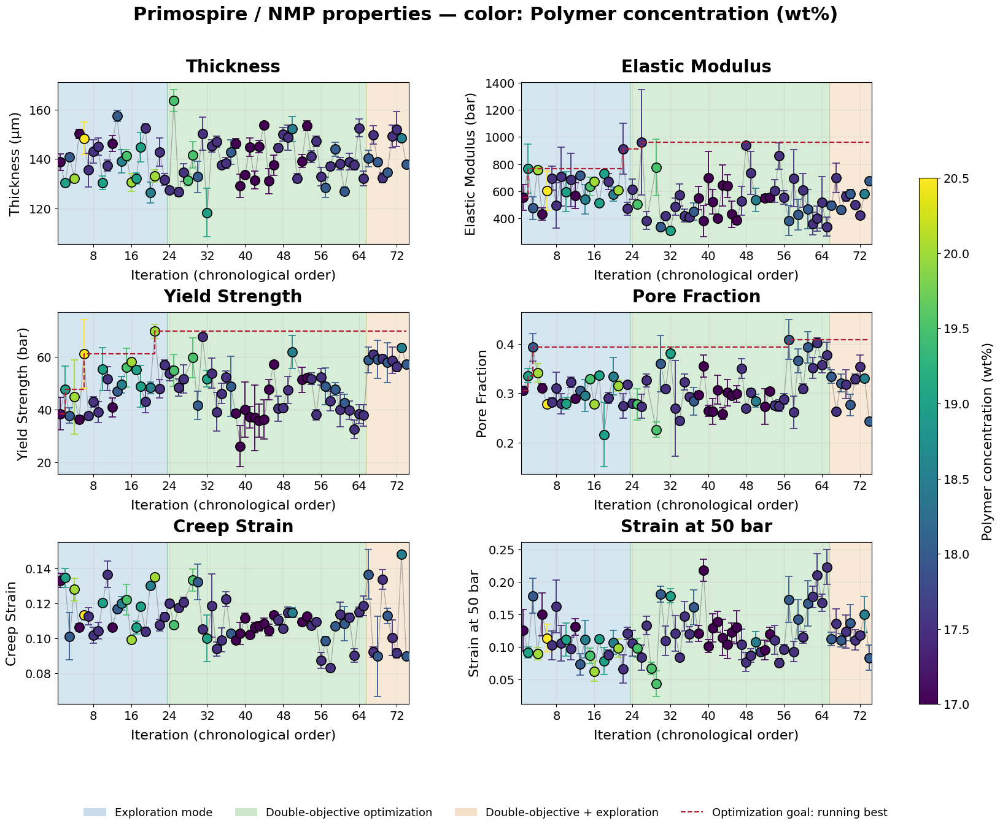

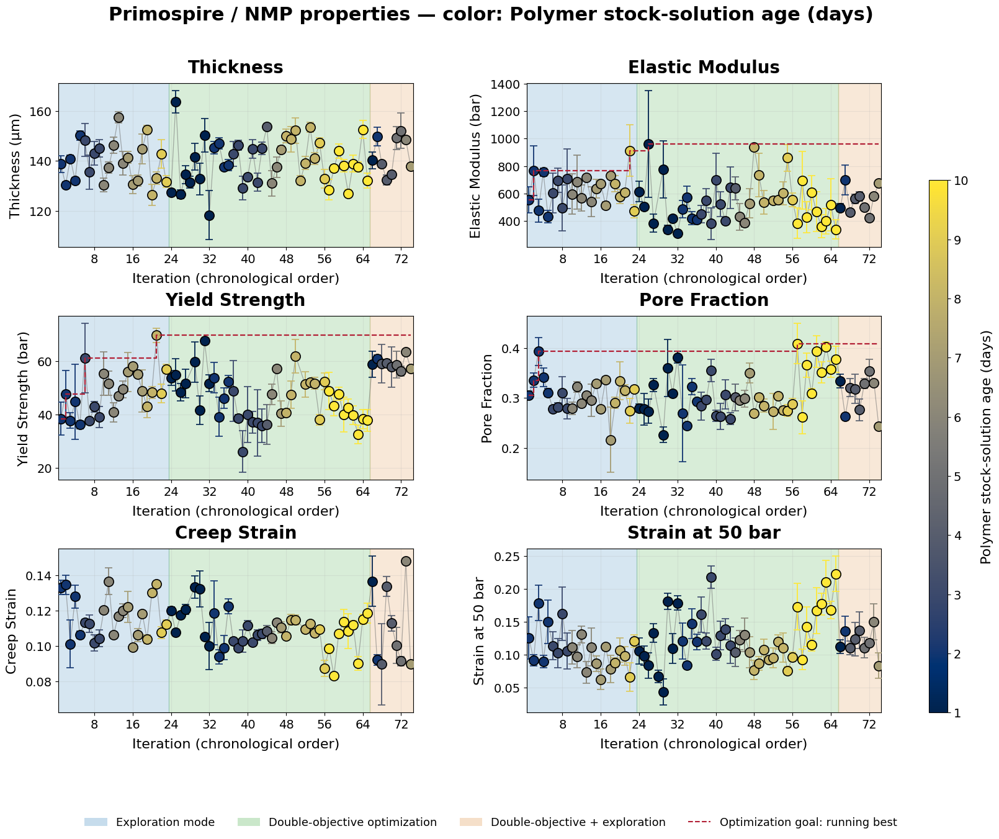

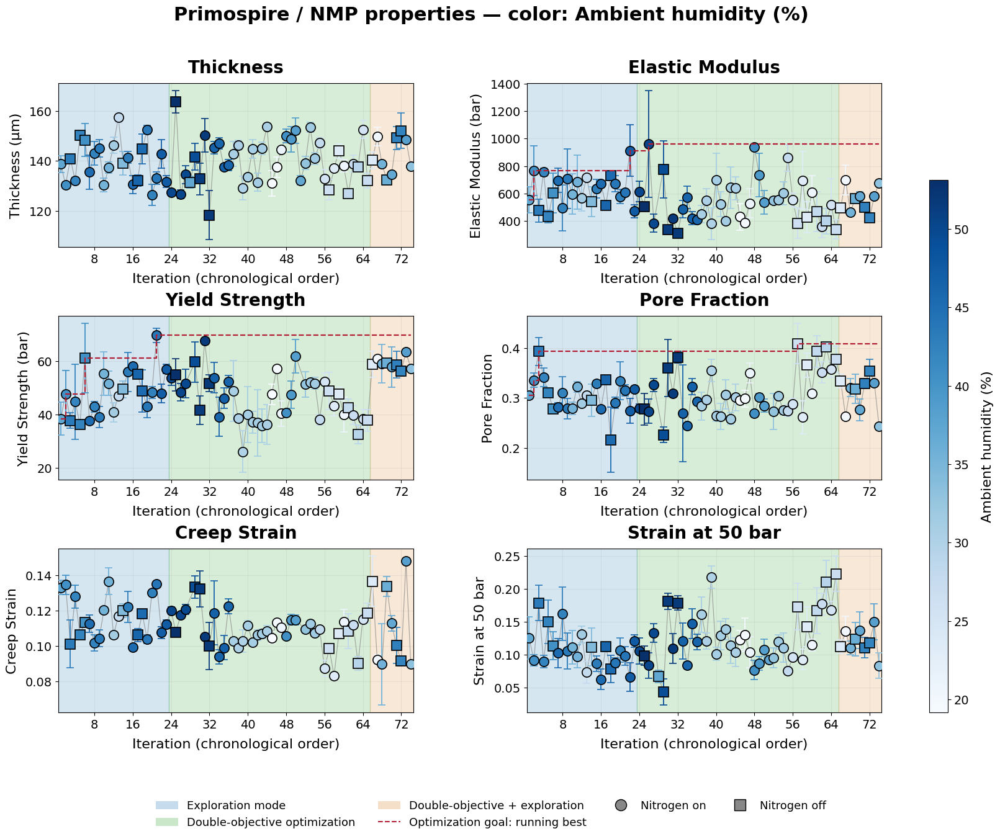

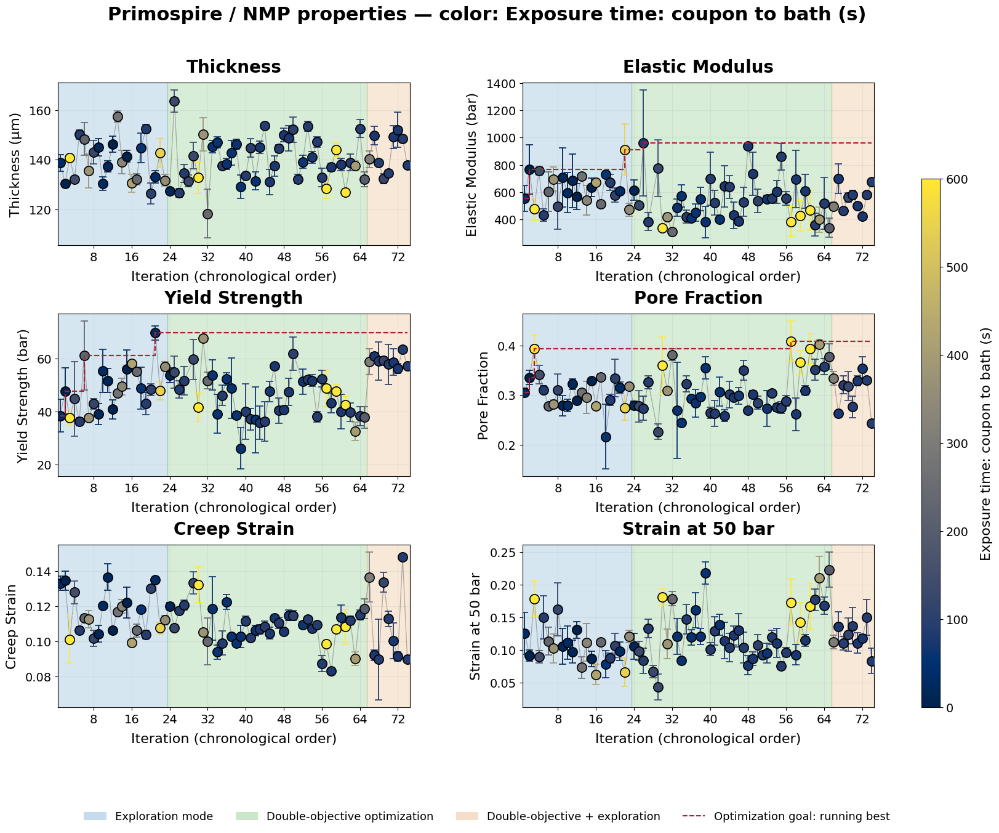

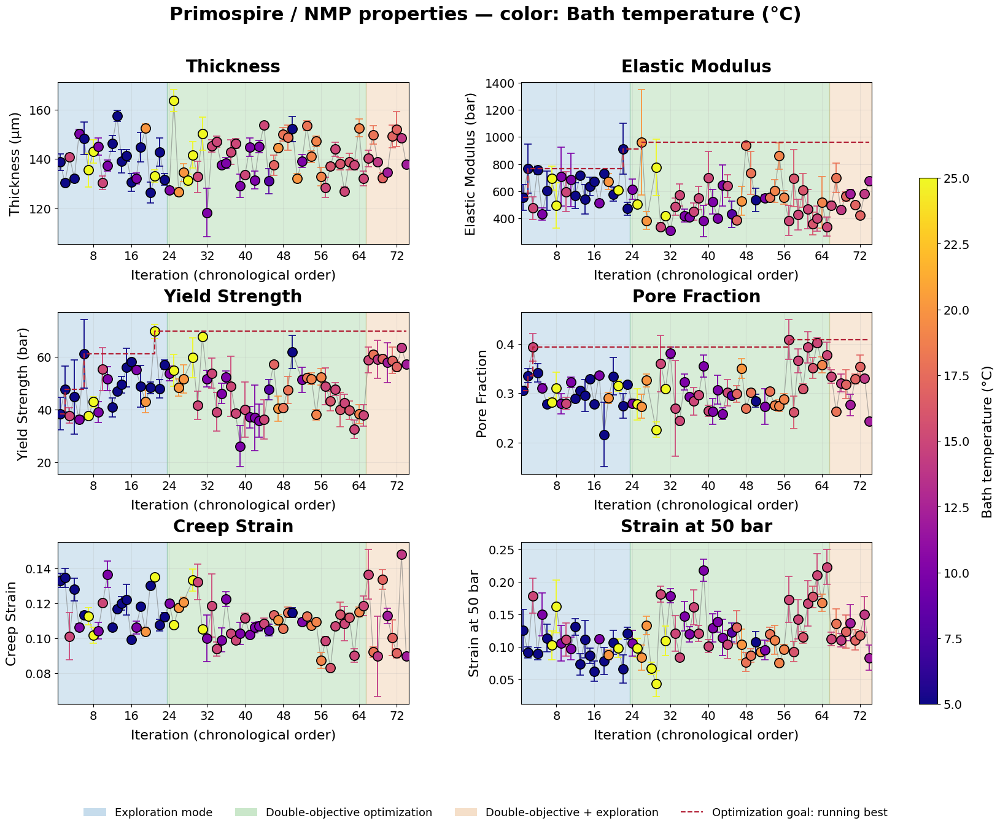

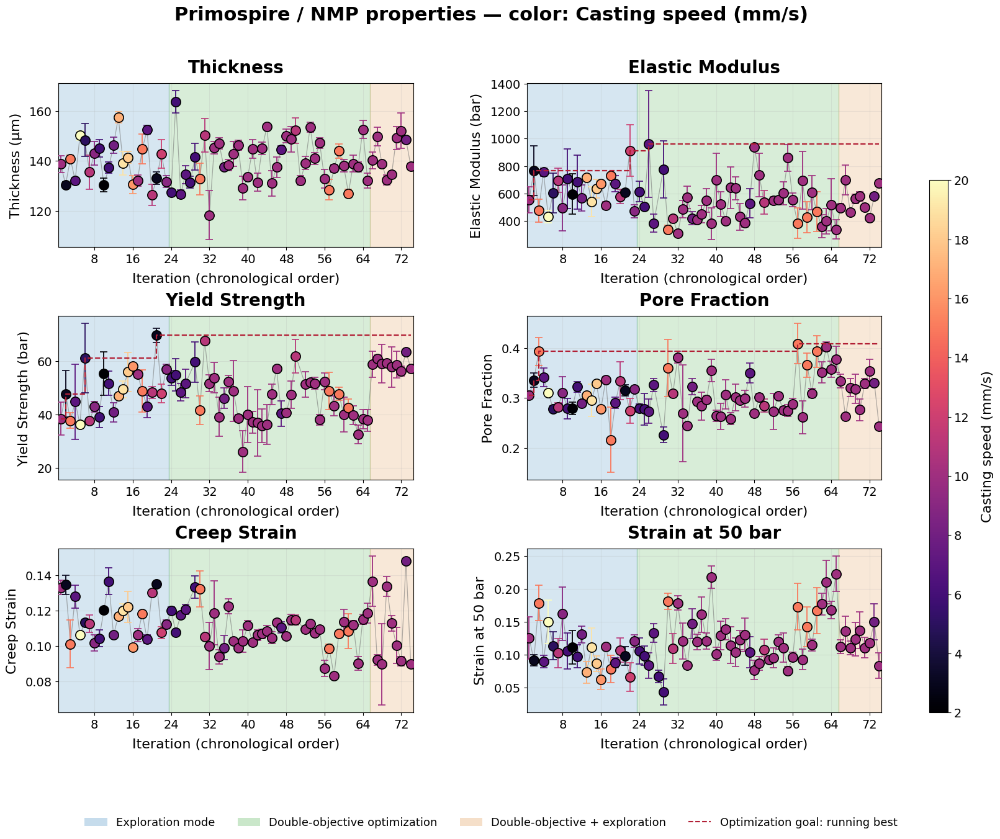

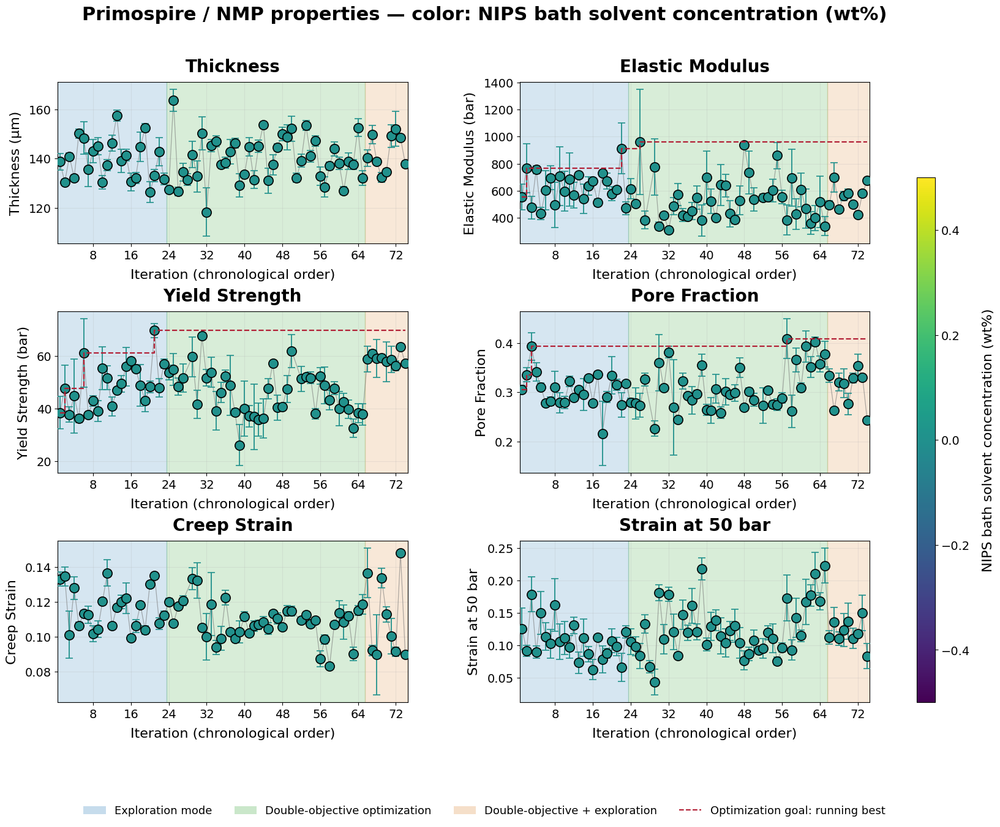

Warm-start dataset updated: 74 samples


In [34]:
figure_polymer, axes_polymer, campaign_detailed = plot_detailed_campaign(
    campaign, PROPERTIES, 'polymer_wt', 'Polymer concentration (wt%)',
    connect_points=CONNECT_POINTS, cmap='viridis')
figure_stock_age, axes_stock_age, _ = plot_detailed_campaign(
    campaign, PROPERTIES, 'polymer_solution_age_days', 'Polymer stock-solution age (days)',
    connect_points=CONNECT_POINTS, cmap='cividis')
figure_humidity, axes_humidity, _ = plot_detailed_campaign(
    campaign, PROPERTIES, 'Humidity Mean', 'Ambient humidity (%)', nitrogen_markers=True,
    connect_points=CONNECT_POINTS, cmap='Blues')
figure_exposure, axes_exposure, _ = plot_detailed_campaign(
    campaign, PROPERTIES, 'coupon_to_bath_wait_time', 'Exposure time: coupon to bath (s)',
    connect_points=CONNECT_POINTS, cmap='cividis')
figure_bath, axes_bath, _ = plot_detailed_campaign(
    campaign, PROPERTIES, 'bath_temp', 'Bath temperature (°C)', connect_points=CONNECT_POINTS, cmap='plasma')
figure_casting, axes_casting, _ = plot_detailed_campaign(
    campaign, PROPERTIES, 'pullcast_speed', 'Casting speed (mm/s)', connect_points=CONNECT_POINTS, cmap='magma')
figure_bath_solvent, axes_bath_solvent, _ = plot_detailed_campaign(
    campaign, PROPERTIES, 'nips_bath_solvent_wt_percent',
    'NIPS bath solvent concentration (wt%)',
    connect_points=CONNECT_POINTS, cmap='viridis'
)
plt.show()
if SAVE_OUTPUTS:
    bath_solvent_output = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    bath_solvent_output.mkdir(parents=True, exist_ok=True)
    figure_bath_solvent.savefig(bath_solvent_output / 'campaign_properties_by_bath_solvent_concentration.png',
                                dpi=180, bbox_inches='tight')

# Keep AL warm-start history identical to the data selected for these plots.
from export_warm_start import export_notebook_warm_start
warm_start_summary = export_notebook_warm_start(
    campaign_detailed, 'primospire_nmp_campaign_trends.ipynb', root=repo_root, settings=globals())
print('Warm-start dataset updated:', warm_start_summary['rows'], 'samples')


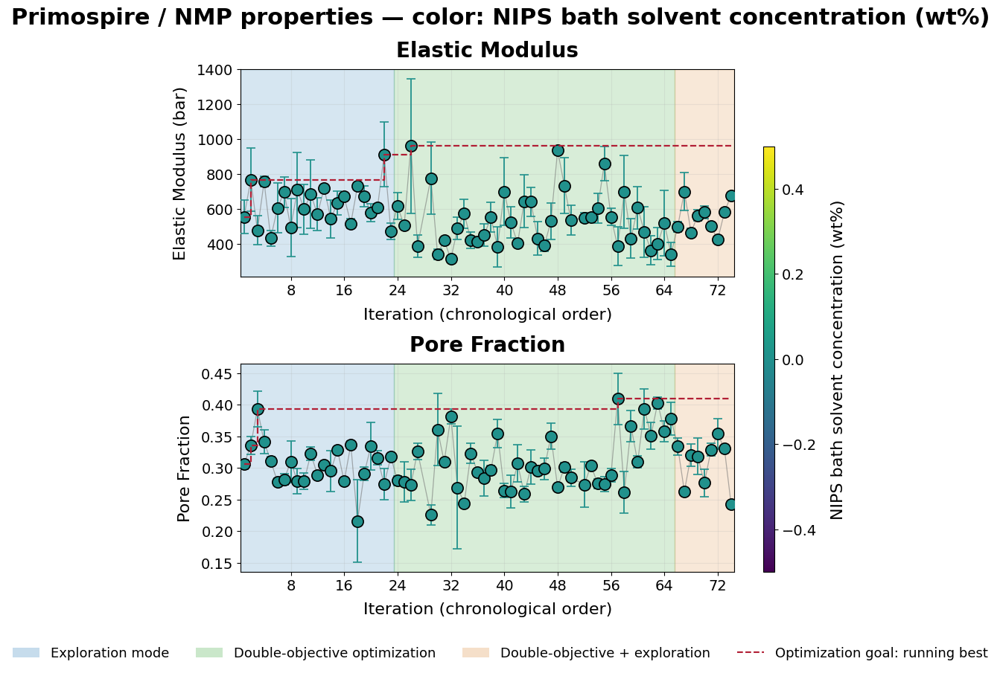

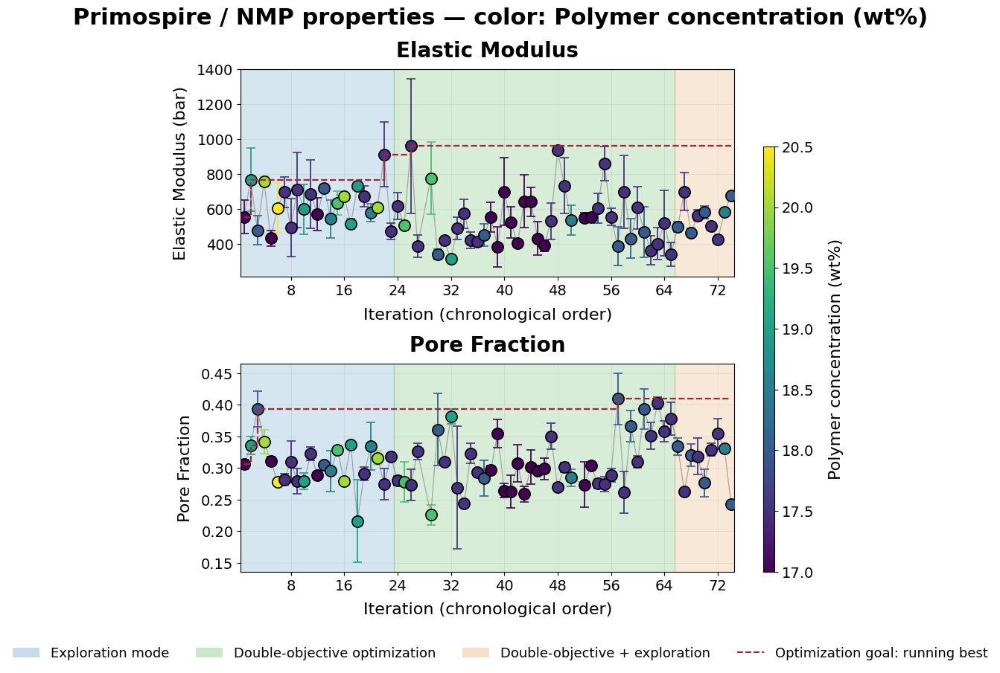

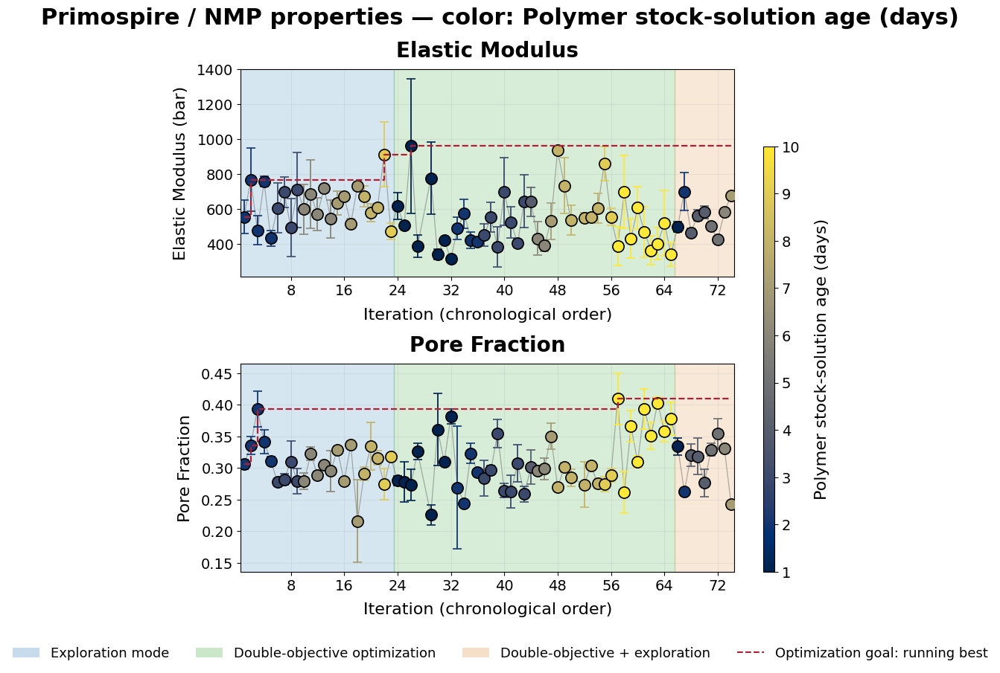

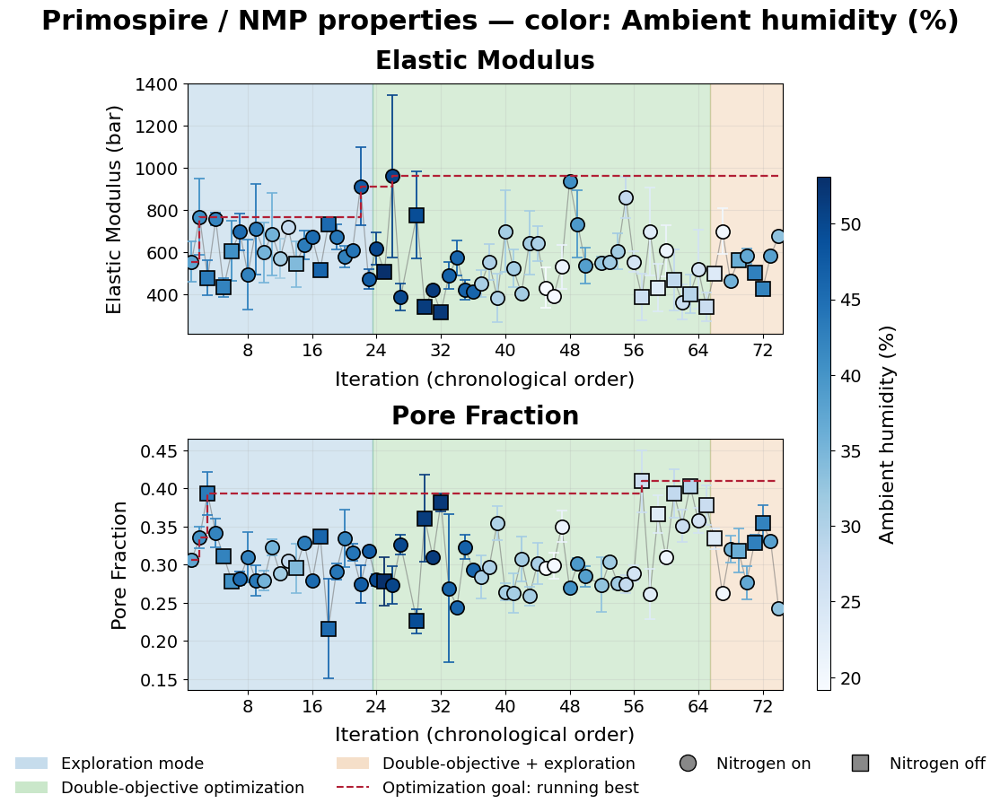

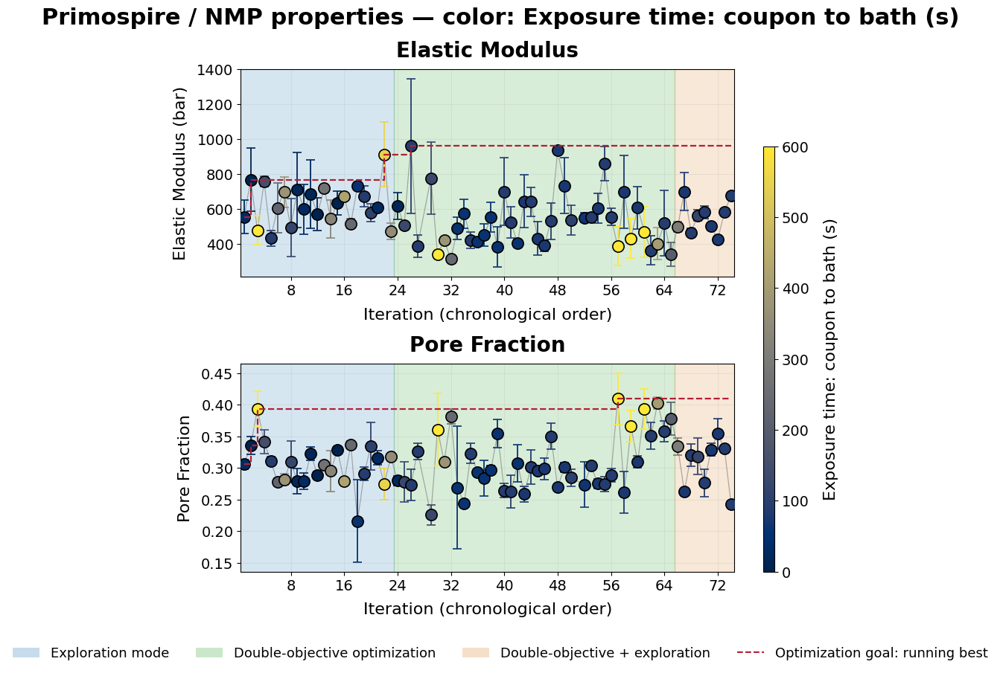

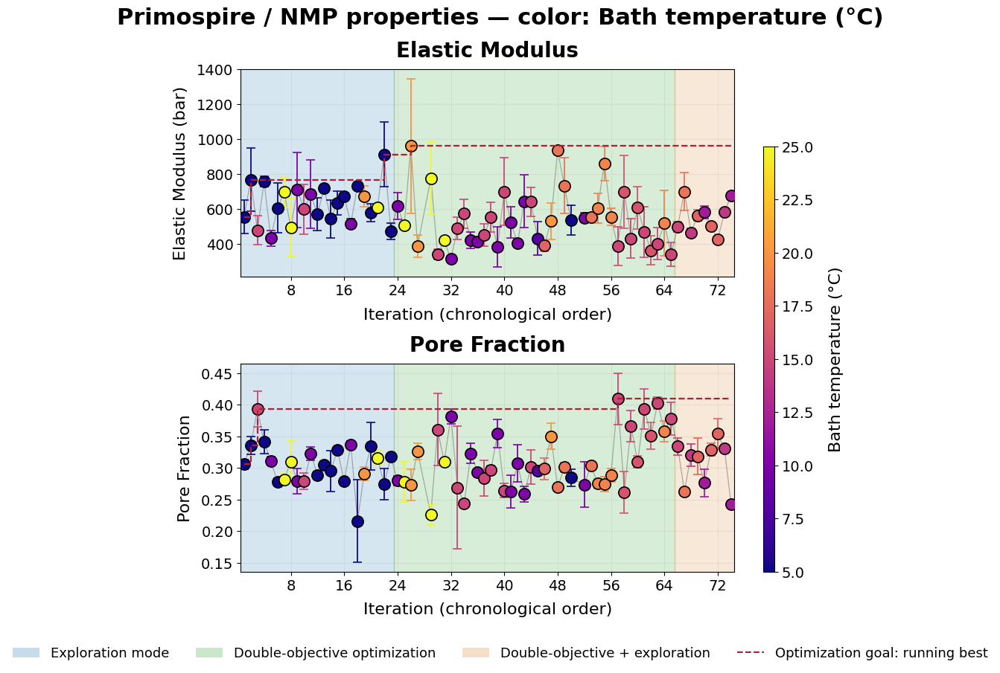

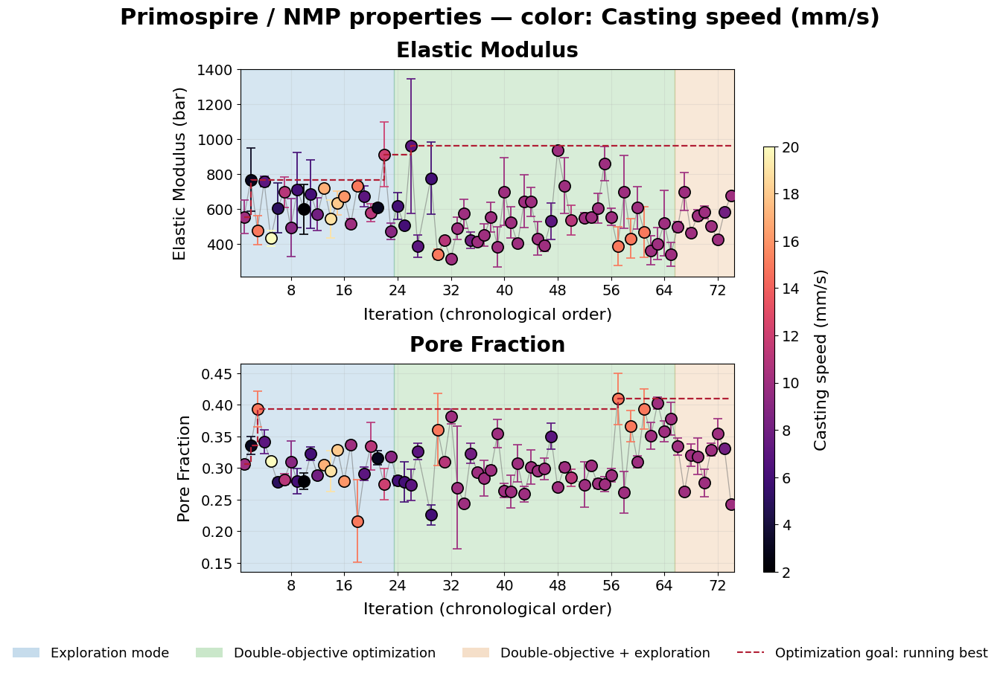

In [35]:
# Compact companion figures: the three optimization properties stacked vertically.
CORE_PROPERTIES = ['Elastic Modulus', 'Pore Fraction']
CORE_TREND_VIEWS = {
    'bath_solvent': ('nips_bath_solvent_wt_percent', 'NIPS bath solvent concentration (wt%)', False, 'viridis'),
    'polymer': ('polymer_wt', 'Polymer concentration (wt%)', False, 'viridis'),
    'stock_age': ('polymer_solution_age_days', 'Polymer stock-solution age (days)', False, 'cividis'),
    'humidity': ('Humidity Mean', 'Ambient humidity (%)', True, 'Blues'),
    'exposure': ('coupon_to_bath_wait_time', 'Exposure time: coupon to bath (s)', False, 'cividis'),
    'bath': ('bath_temp', 'Bath temperature (°C)', False, 'plasma'),
    'casting': ('pullcast_speed', 'Casting speed (mm/s)', False, 'magma'),
}

core_trend_figures = {}
core_trend_axes = {}
for view_name, (color_column, color_label, nitrogen_markers, color_map) in CORE_TREND_VIEWS.items():
    figure, axes, _ = plot_detailed_campaign(
        campaign, CORE_PROPERTIES, color_column, color_label,
        nitrogen_markers=nitrogen_markers, columns=1,
        connect_points=CONNECT_POINTS, cmap=color_map,
    )
    core_trend_figures[view_name] = figure
    core_trend_axes[view_name] = axes
plt.show()


## Consistency of samples with matched conditions

Polymer concentration, nitrogen state, and NIPS bath solvent concentration (`nips_bath_solvent_wt_percent`, wt%) must match **exactly**. Missing or invalid bath concentrations are excluded from matching; 0 and 10 wt% samples cannot share a group. The editable limits below are the **maximum difference between any two members**, not a plus/minus window: exposure 10 s, bath temperature 3 degrees C, casting speed 3 mm/s, and humidity 5 percentage points. Matching uses process inputs only; property values never influence membership.

Complete-linkage grouping prevents chains of near matches from exceeding these limits. Groups are disjoint and contain at least two samples; some valid pairs can span different groups, so `repeat_pairs` retains **every qualifying pair**. Missing matching inputs are excluded and listed in `repeat_excluded`; unmatched samples remain in `repeat_rows`. The same campaign quality filters used above apply here.

Each row of plots shows one group, with a panel for each response. Points are sample means and error bars are **intra-sample SD**, not confidence intervals. Dashed lines show the group mean. The table and panel titles report **between-sample CV = 100 x SD(sample means) / abs(mean)**, using sample SD (ddof=1). Smaller CV indicates closer agreement; small groups and near-zero means limit its interpretation. Missing responses are omitted separately for each property.

Mixing temperature and bath residence time are not constrained; their ranges are shown in the condition table for reference. These are similar-condition comparisons within the configured tolerances, not necessarily exact controlled replicates. Group IDs are recomputed when tolerances change.


In [36]:
import campaign_repeatability
importlib.reload(campaign_repeatability)
from campaign_repeatability import match_conditions, group_conditions, summarize_repeats, plot_repeatability

consistency_data = campaign_detailed.copy()
REPEAT_TOLERANCES = {
    'coupon_to_bath_wait_time': 10.0,  # seconds
    'bath_temp': 3.0,                 # degrees C
    'pullcast_speed': 3.0,            # mm/s
    'Humidity Mean': 5.0,             # percentage points
}
repeat_rows, repeat_pairs = match_conditions(consistency_data, REPEAT_TOLERANCES)
repeat_members = repeat_rows[repeat_rows['repeat_group'].notna()].copy()
repeat_excluded = repeat_rows[repeat_rows['match_status'] == 'Missing matching inputs'].copy()
repeat_conditions = group_conditions(repeat_rows, REPEAT_TOLERANCES)
repeat_summary = summarize_repeats(repeat_rows)
print(f'{len(repeat_conditions)} groups containing {len(repeat_members)} samples; '
      f'{len(repeat_pairs)} qualifying pairs in total.')
print(f'{len(repeat_excluded)} samples excluded for missing matching inputs; '
      f"{(repeat_rows['match_status'] == 'No grouped repeat').sum()} complete samples outside repeat groups.")
repeat_conditions


12 groups containing 31 samples; 30 qualifying pairs in total.
2 samples excluded for missing matching inputs; 41 complete samples outside repeat groups.


,group,n,iterations,polymer_wt,nips_bath_solvent_wt_percent,nitrogen,coupon_to_bath_wait_time range,bath_temp range,pullcast_speed range,Humidity Mean range,mixing_temp range (not matched),nips_bath_wait_time range (not matched),additive_wt range (not matched)
0,G1,2,"20, 50",18.5,0.0,On,105 to 105,5 to 5,11 to 11,38.47 to 42.57,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing
1,G2,2,"25, 29",19.5,0.0,Off,130 to 130,25 to 25,6 to 6,49.4 to 53.12,80 to 80; 0 missing,1550 to 1550; 0 missing,0 to 0; 0 missing
2,G3,2,"26, 27",17.5,0.0,On,90 to 90,20 to 20,7 to 7,50 to 50.42,50 to 50; 0 missing,1250 to 1250; 0 missing,0 to 0; 0 missing
3,G4,2,"33, 34",17.5,0.0,On,60 to 60,15 to 15,10 to 10,46.12 to 46.51,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing
4,G5,3,"39, 42, 52",17.0,0.0,On,60 to 65,10 to 10,10 to 10,29.94 to 32.91,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing
5,G6,3,"40, 44, 53",17.0,0.0,On,90 to 90,15 to 18,10 to 10,30.51 to 31.68,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing
6,G7,2,"48, 49",17.5,0.0,On,75 to 75,18 to 18,10 to 10,39.28 to 40.58,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing
7,G8,4,"55, 56, 62, 64",17.5,0.0,On,90 to 90,16 to 19,10 to 10,25.15 to 27.84,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing
8,G9,3,"57, 59, 61",18.0,0.0,Off,600 to 600,15 to 15,15 to 15,23.46 to 28.12,80 to 80; 0 missing,1350 to 1350; 0 missing,0 to 0; 0 missing
9,G10,3,"58, 60, 67",17.5,0.0,On,75 to 75,16 to 18,10 to 10,20.28 to 23.21,65 to 65; 0 missing,1800 to 1800; 0 missing,0 to 0; 0 missing


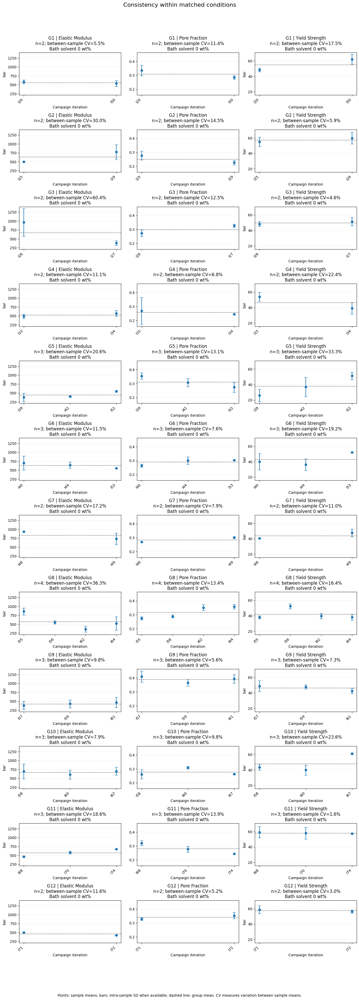

,group,property,n,mean,between_sample_SD,CV_percent,min,max
0,G1,Elastic Modulus,2,557.914,30.801,5.521,536.134,579.693
1,G1,Pore Fraction,2,0.309,0.035,11.419,0.284,0.334
2,G1,Yield Strength,2,55.137,9.647,17.497,48.316,61.959
3,G2,Elastic Modulus,2,640.342,191.897,29.968,504.650,776.033
4,G2,Pore Fraction,2,0.252,0.037,14.536,0.226,0.278
5,G2,Yield Strength,2,57.300,3.398,5.930,54.897,59.703
6,G3,Elastic Modulus,2,672.943,406.691,60.435,385.369,960.517
7,G3,Pore Fraction,2,0.300,0.037,12.484,0.273,0.326
8,G3,Yield Strength,2,49.989,2.315,4.631,48.352,51.626
9,G4,Elastic Modulus,2,530.709,59.053,11.127,488.952,572.466


In [37]:
figure_repeatability = plot_repeatability(repeat_rows)
plt.show()
repeat_summary.round(3)


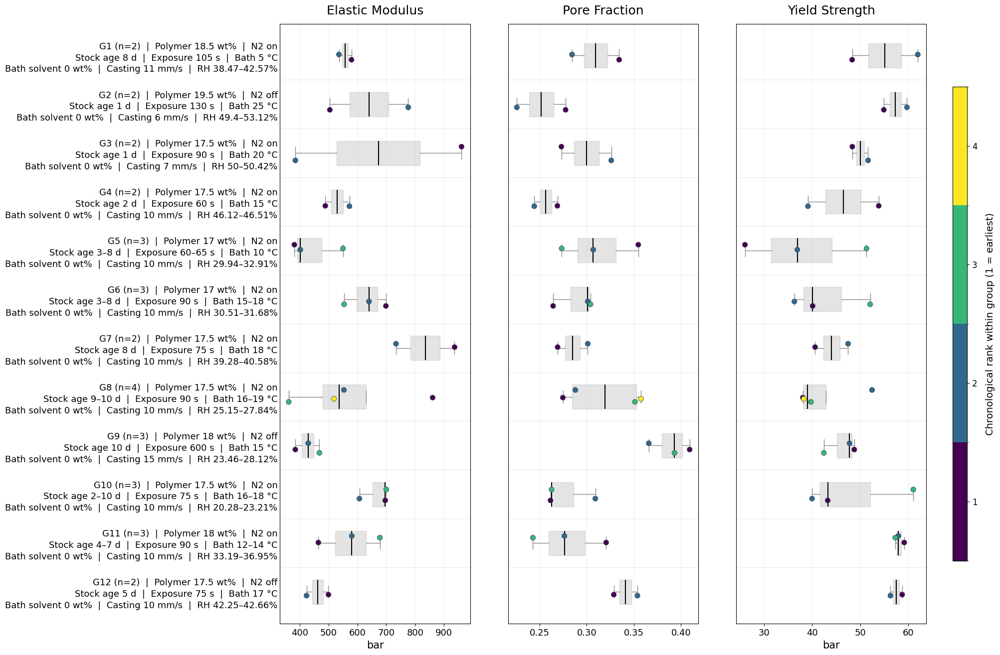

In [38]:
# Horizontal boxes with observations colored by chronological rank within each group.
figure_repeatability_boxes = campaign_repeatability.plot_repeatability_boxes(repeat_rows)
plt.show()


In [39]:
if SAVE_OUTPUTS:
    repeat_output_dir = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    repeat_output_dir.mkdir(parents=True, exist_ok=True)
    for name, table in {'members': repeat_members, 'conditions': repeat_conditions,
                        'summary': repeat_summary, 'pairs': repeat_pairs,
                        'all_samples': repeat_rows}.items():
        table.to_csv(repeat_output_dir / f'campaign_repeatability_{name}.csv', index=False)
    figure_repeatability.savefig(repeat_output_dir / 'campaign_repeatability.png',
                                dpi=180, bbox_inches='tight')

    figure_repeatability_boxes.savefig(repeat_output_dir / 'campaign_repeatability_boxes.png',
                                       dpi=180)  # Preserve the short, wide aspect ratio.

# Trace each plotted iteration back to its original sample and matching inputs.
repeat_members[['repeat_group', 'iteration', 'condition', 'campaign', 'sample_time',
                'polymer_wt', 'nitrogen'] + list(REPEAT_TOLERANCES)]


,repeat_group,iteration,condition,campaign,sample_time,polymer_wt,nitrogen,coupon_to_bath_wait_time,bath_temp,pullcast_speed,Humidity Mean
19,G1,20,18p5-0add-5deg-cosolv-none-bathSolv-none-0wt-1...,2026-09-10-exploration-mode,2026-09-16 20:55:08,18.5,True,105,5,11,42.57
24,G2,25,19p5-0add-25deg-cosolv-none-bathSolv-none-0wt-...,2026-09-30,2026-09-30 11:47:53,19.5,False,130,25,6,53.12
25,G3,26,17p5-0add-20deg-cosolv-none-bathSolv-none-0wt-...,2026-09-30,2026-09-30 14:21:55,17.5,True,90,20,7,50.42
26,G3,27,17p5-0add-20deg-cosolv-none-bathSolv-none-0wt-...,2026-09-30,2026-09-30 16:23:56,17.5,True,90,20,7,50.00
28,G2,29,19p5-0add-25deg-cosolv-none-bathSolv-none-0wt-...,2026-09-30,2026-09-30 20:44:11,19.5,False,130,25,6,49.40
32,G4,33,17p5-0add-15deg-cosolv-none-bathSolv-none-0wt-...,2026-09-30,2026-10-01 15:15:03,17.5,True,60,15,10,46.51
33,G4,34,17p5-0add-15deg-cosolv-none-bathSolv-none-0wt-...,2026-09-30,2026-10-01 17:34:17,17.5,True,60,15,10,46.12
38,G5,39,17-0add-10deg-cosolv-none-bathSolv-none-0wt-60...,2026-09-30,2026-10-02 19:41:06,17.0,True,60,10,10,29.94
39,G6,40,17-0add-15deg-cosolv-none-bathSolv-none-0wt-90...,2026-09-30,2026-10-02 21:59:41,17.0,True,90,15,10,31.00
41,G5,42,17-0add-10deg-cosolv-none-bathSolv-none-0wt-60...,2026-09-30,2026-10-03 02:30:58,17.0,True,60,10,10,31.27


## Confounding stratification

This diagnostic asks whether input?property associations persist after comparing samples within similar design strata. It controls for **acquisition mode**, **polymer stock bottle**, **polymer concentration band**, and **nitrogen state**. **Polymer stock-solution age** is included as days since the applicable bottle was prepared (August 14 before the September 10 changeover; September 10 afterward). Timestamps at or before 9:00 AM are assigned to the previous experimental day. The stock bottle is also included in the strata, so the age result measures within-bottle aging rather than treating the bottle reset as continuous time. When polymer concentration or nitrogen is the input being evaluated, that same variable is removed from its own stratification set.

For each input and response, the analysis first keeps strata with at least `MIN_CONFOUNDING_STRATUM_SIZE` samples and variation in that input. It then compares:

- **Crude (same rows):** the standardized association among exactly the rows used by the stratified estimate.
- **Within-strata:** the standardized fixed-effect slope after subtracting each stratum's input and response means.

A direction reversal is flagged only when both standardized slopes have magnitude at least `DIRECTION_REVERSAL_MIN_MAGNITUDE`; it is a Simpson's-paradox warning: the pooled association and within-stratum association have opposite signs. Sparse coverage, correlated controls, nonlinear responses, measurement error, and omitted variables still limit interpretation. These are observational diagnostics, not causal effects. The coverage heatmap shows where comparisons are supported; blank cells have no retained samples.


In [40]:
import numpy as np

CONFOUNDING_FEATURES = {
    'polymer_solution_age_days': 'Polymer stock-solution age (days)',
    'polymer_wt': 'Polymer concentration (wt%)',
    'mixing_temp': 'Mixing temperature (°C)',
    'bath_temp': 'Bath temperature (°C)',
    'pullcast_speed': 'Casting speed (mm/s)',
    'nitrogen': 'Nitrogen on/off',
    'coupon_to_bath_wait_time': 'Exposure time (s)',
    'nips_bath_wait_time': 'Bath residence time (s)',
    'nips_bath_solvent_wt_percent': 'NIPS bath solvent concentration (wt%)',
    'Humidity Mean': 'Ambient humidity (%)',
}
CONFOUNDING_PROPERTIES = ['Elastic Modulus', 'Pore Fraction', 'Yield Strength']
MIN_CONFOUNDING_STRATUM_SIZE = 3
DIRECTION_REVERSAL_MIN_MAGNITUDE = 0.05

def confounding_nitrogen_to_binary(value):
    return 1 if (value is True or str(value).strip().lower() in {'true', '1', 'yes', 'on'}) else 0

POLYMER_STRATUM_BINS = [-np.inf, 18, 19, 20, np.inf]
POLYMER_STRATUM_LABELS = ['<18', '18-<19', '19-<20', '20+']


def prepare_confounding_data(data):
    prepared = data.copy()
    mode = pd.Series(pd.NA, index=prepared.index, dtype='object')
    for phase in PHASES:
        phase_mask = _phase_mask(phase, prepared)
        if mode.loc[phase_mask].notna().any():
            raise ValueError('Acquisition-mode definitions overlap.')
        mode.loc[phase_mask] = phase['mode_label']
    if mode.isna().any():
        missing = prepared.loc[mode.isna(), 'campaign'].value_counts().to_dict()
        raise ValueError(f'Samples lack acquisition-mode classification: {missing}')
    prepared['acquisition_mode'] = mode
    prepared['polymer_stratum'] = pd.cut(
        pd.to_numeric(prepared['polymer_wt'], errors='coerce'),
        bins=POLYMER_STRATUM_BINS, labels=POLYMER_STRATUM_LABELS,
        right=False, ordered=True,
    )
    prepared['nitrogen_stratum'] = prepared['nitrogen'].map(
        lambda value: 'On' if confounding_nitrogen_to_binary(value) else 'Off'
    )
    return prepared


def _standardized_slope(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    x_scale, y_scale = x.std(ddof=0), y.std(ddof=0)
    if x_scale == 0 or y_scale == 0:
        return np.nan
    xz, yz = (x - x.mean()) / x_scale, (y - y.mean()) / y_scale
    return float(np.dot(xz, yz) / np.dot(xz, xz))


def confounding_stratified_associations(data, features=CONFOUNDING_FEATURES,
                                         properties=CONFOUNDING_PROPERTIES,
                                         minimum_stratum_size=MIN_CONFOUNDING_STRATUM_SIZE):
    if minimum_stratum_size < 2:
        raise ValueError('minimum_stratum_size must be at least 2.')
    records = []
    base_strata = ['acquisition_mode', 'stock_solution_batch', 'polymer_stratum', 'nitrogen_stratum']
    for feature, feature_label in features.items():
        strata = list(base_strata)
        if feature == 'polymer_wt':
            strata.remove('polymer_stratum')
        if feature == 'nitrogen':
            strata.remove('nitrogen_stratum')
        for property_name in properties:
            response = f'{property_name} Mean'
            columns = [feature, response] + strata
            usable = data[columns].copy()
            if feature == 'nitrogen':
                usable[feature] = usable[feature].map(confounding_nitrogen_to_binary)
            usable[feature] = pd.to_numeric(usable[feature], errors='coerce')
            usable[response] = pd.to_numeric(usable[response], errors='coerce')
            usable = usable.replace([np.inf, -np.inf], np.nan).dropna(subset=columns)
            if usable.empty:
                continue
            grouped = usable.groupby(strata, observed=True, sort=False)
            informative = grouped[feature].transform('size').ge(minimum_stratum_size)
            informative &= grouped[feature].transform('nunique').gt(1)
            common = usable.loc[informative].copy()
            if len(common) < minimum_stratum_size:
                continue
            group_keys = [common[column] for column in strata]
            common['_stratum'] = pd.MultiIndex.from_arrays(group_keys).to_flat_index()
            x, y = common[feature].to_numpy(float), common[response].to_numpy(float)
            crude = _standardized_slope(x, y)
            x_scale, y_scale = x.std(ddof=0), y.std(ddof=0)
            if x_scale == 0 or y_scale == 0:
                continue
            common['_x_standardized'] = (x - x.mean()) / x_scale
            common['_y_standardized'] = (y - y.mean()) / y_scale
            within = common.groupby('_stratum', observed=True, sort=False)
            x_centered = common['_x_standardized'] - within['_x_standardized'].transform('mean')
            y_centered = common['_y_standardized'] - within['_y_standardized'].transform('mean')
            denominator = float(np.dot(x_centered, x_centered))
            adjusted = float(np.dot(x_centered, y_centered) / denominator) if denominator else np.nan
            stratum_sizes = common.groupby('_stratum', observed=True).size()
            records.append({
                'property': property_name,
                'feature': feature_label,
                'feature_column': feature,
                'stratified_by': ' + '.join(strata),
                'n_total_available': len(usable),
                'n_informative': len(common),
                'n_informative_strata': len(stratum_sizes),
                'smallest_informative_stratum': int(stratum_sizes.min()),
                'largest_informative_stratum': int(stratum_sizes.max()),
                'crude_standardized_slope_same_rows': crude,
                'within_strata_standardized_slope': adjusted,
                'absolute_change': adjusted - crude,
                'direction_reversal': bool(np.isfinite(crude) and np.isfinite(adjusted)
                                           and abs(crude) >= DIRECTION_REVERSAL_MIN_MAGNITUDE
                                           and abs(adjusted) >= DIRECTION_REVERSAL_MIN_MAGNITUDE
                                           and crude * adjusted < 0),
            })
    return pd.DataFrame(records)


confounding_source = campaign_detailed.copy()
confounding_data = prepare_confounding_data(confounding_source)
confounding_results = confounding_stratified_associations(confounding_data)
confounding_coverage = (confounding_data
    .groupby(['acquisition_mode', 'polymer_stratum', 'nitrogen_stratum'], observed=True)
    .size().rename('n').reset_index())
print(f'{len(confounding_data)} samples; {len(confounding_results)} feature?response diagnostics; '
      f"{confounding_results['direction_reversal'].sum()} direction reversals.")
confounding_results.sort_values(
    ['direction_reversal', 'property', 'within_strata_standardized_slope'],
    ascending=[False, True, False]
).reset_index(drop=True)


74 samples; 27 feature?response diagnostics; 1 direction reversals.


,property,feature,feature_column,stratified_by,n_total_available,n_informative,n_informative_strata,smallest_informative_stratum,largest_informative_stratum,crude_standardized_slope_same_rows,within_strata_standardized_slope,absolute_change,direction_reversal
0,Elastic Modulus,Mixing temperature (°C),mixing_temp,acquisition_mode + stock_solution_batch + poly...,72,47,5,3,29,-0.149891,0.119465,0.269355,True
1,Elastic Modulus,Nitrogen on/off,nitrogen,acquisition_mode + stock_solution_batch + poly...,72,69,8,4,31,0.349331,0.394250,0.044919,False
2,Elastic Modulus,Polymer concentration (wt%),polymer_wt,acquisition_mode + stock_solution_batch + nitr...,72,72,6,4,31,0.163900,0.218429,0.054529,False
3,Elastic Modulus,Polymer stock-solution age (days),polymer_solution_age_days,acquisition_mode + stock_solution_batch + poly...,72,55,7,3,29,0.095462,0.160623,0.065161,False
4,Elastic Modulus,Bath temperature (°C),bath_temp,acquisition_mode + stock_solution_batch + poly...,72,51,6,3,29,0.024393,0.146754,0.122360,False
5,Elastic Modulus,Exposure time (s),coupon_to_bath_wait_time,acquisition_mode + stock_solution_batch + poly...,72,50,6,3,29,0.100405,0.064419,-0.035986,False
6,Elastic Modulus,Ambient humidity (%),Humidity Mean,acquisition_mode + stock_solution_batch + poly...,72,58,8,3,29,0.118863,0.049937,-0.068926,False
7,Elastic Modulus,Bath residence time (s),nips_bath_wait_time,acquisition_mode + stock_solution_batch + poly...,72,47,5,3,29,-0.151749,-0.043191,0.108558,False
8,Elastic Modulus,Casting speed (mm/s),pullcast_speed,acquisition_mode + stock_solution_batch + poly...,72,51,6,3,29,-0.088213,-0.060952,0.027261,False
9,Pore Fraction,Polymer stock-solution age (days),polymer_solution_age_days,acquisition_mode + stock_solution_batch + poly...,72,55,7,3,29,0.193772,0.077460,-0.116311,False


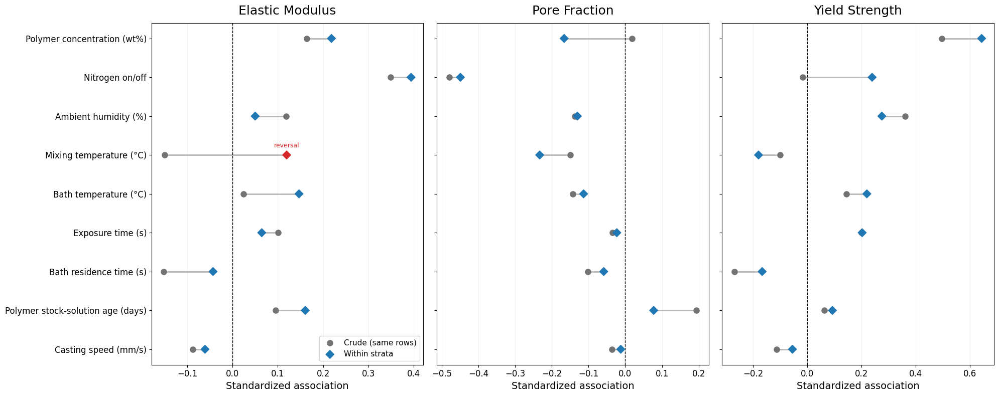

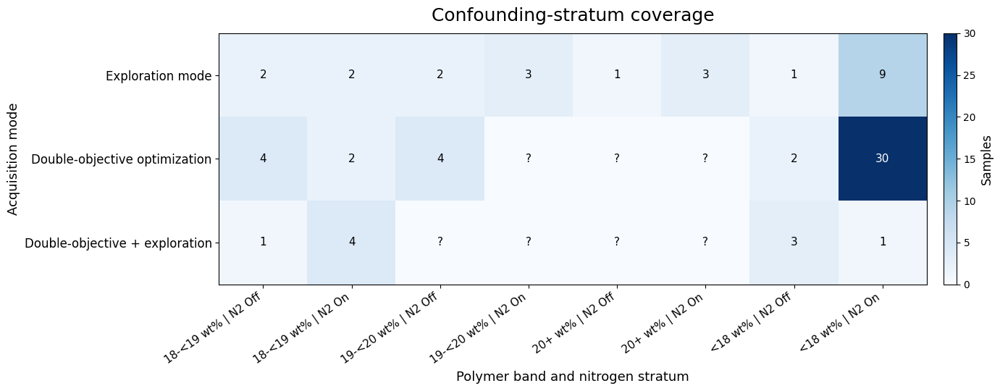

In [41]:
def plot_confounding_stratification(results, coverage):
    feature_order = (results.assign(magnitude=results['within_strata_standardized_slope'].abs())
                     .groupby('feature')['magnitude'].max().sort_values().index.tolist())
    figure, axes = plt.subplots(1, len(CONFOUNDING_PROPERTIES), figsize=(20, 8),
                               sharey=True, squeeze=False)
    for axis, property_name in zip(axes[0], CONFOUNDING_PROPERTIES):
        detail = results[results['property'] == property_name].set_index('feature').reindex(feature_order)
        positions = np.arange(len(feature_order))
        crude = detail['crude_standardized_slope_same_rows'].to_numpy(float)
        adjusted = detail['within_strata_standardized_slope'].to_numpy(float)
        for position, start, end in zip(positions, crude, adjusted):
            if np.isfinite(start) and np.isfinite(end):
                axis.plot([start, end], [position, position], color='0.72', linewidth=2, zorder=1)
        axis.scatter(crude, positions, color='0.45', marker='o', s=65,
                     label='Crude (same rows)', zorder=2)
        reversal = detail['direction_reversal'].fillna(False).to_numpy(bool)
        colors = np.where(reversal, '#d62728', '#1f77b4')
        axis.scatter(adjusted, positions, c=colors, marker='D', s=70,
                     label='Within strata', zorder=3)
        for position, is_reversal in zip(positions, reversal):
            if is_reversal:
                axis.text(adjusted[position], position + .20, 'reversal', color='#d62728',
                          fontsize=9, ha='center')
        axis.axvline(0, color='black', linewidth=1, linestyle='--')
        axis.set_title(property_name, fontsize=18, pad=12)
        axis.set_xlabel('Standardized association', fontsize=14)
        axis.set_yticks(positions)
        axis.set_yticklabels(feature_order, fontsize=12)
        axis.tick_params(axis='x', labelsize=12)
        axis.grid(axis='x', alpha=.2)
    axes[0, 0].legend(fontsize=11, loc='best')
    figure.tight_layout()

    coverage_plot = coverage.copy()
    coverage_plot['column'] = (coverage_plot['polymer_stratum'].astype(str)
                               + ' wt% | N2 ' + coverage_plot['nitrogen_stratum'])
    matrix = coverage_plot.pivot(index='acquisition_mode', columns='column', values='n').fillna(0)
    ordered_modes = [phase['mode_label'] for phase in PHASES if phase['mode_label'] in matrix.index]
    matrix = matrix.reindex(ordered_modes)
    coverage_figure, coverage_axis = plt.subplots(figsize=(15, 5.5))
    image = coverage_axis.imshow(matrix.to_numpy(), cmap='Blues', aspect='auto', vmin=0)
    coverage_axis.set_xticks(range(len(matrix.columns)))
    coverage_axis.set_xticklabels(matrix.columns, rotation=35, ha='right', fontsize=11)
    coverage_axis.set_yticks(range(len(matrix.index)))
    coverage_axis.set_yticklabels(matrix.index, fontsize=12)
    coverage_axis.set_xlabel('Polymer band and nitrogen stratum', fontsize=13)
    coverage_axis.set_ylabel('Acquisition mode', fontsize=13)
    coverage_axis.set_title('Confounding-stratum coverage', fontsize=18, pad=12)
    for row in range(len(matrix.index)):
        for column in range(len(matrix.columns)):
            count = int(matrix.iloc[row, column])
            coverage_axis.text(column, row, str(count) if count else '?', ha='center', va='center',
                               color='white' if count > matrix.to_numpy().max() * .55 else 'black', fontsize=11)
    colorbar = coverage_figure.colorbar(image, ax=coverage_axis, pad=.02)
    colorbar.set_label('Samples', fontsize=12)
    coverage_figure.tight_layout()
    return figure, axes[0], coverage_figure, coverage_axis


figure_confounding, axes_confounding, figure_confounding_coverage, axis_confounding_coverage =     plot_confounding_stratification(confounding_results, confounding_coverage)
plt.show()

if SAVE_OUTPUTS:
    confounding_output = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    confounding_output.mkdir(parents=True, exist_ok=True)
    confounding_results.to_csv(confounding_output / 'confounding_stratified_associations.csv', index=False)
    confounding_coverage.to_csv(confounding_output / 'confounding_stratum_coverage.csv', index=False)
    figure_confounding.savefig(confounding_output / 'confounding_stratified_associations.png', dpi=180)
    figure_confounding_coverage.savefig(confounding_output / 'confounding_stratum_coverage.png', dpi=180)


## Cross-validated feature importance

This section estimates which controllable and environmental variables are most useful for predicting each selected property. It uses a regularized linear (ridge) model with **repeated cross-validated permutation importance**. Importance is the increase in held-out mean absolute error (MAE) after shuffling one feature; larger positive values indicate greater predictive value.

Permutation importance measures **predictive usefulness, not effect direction**. Direction is therefore shown separately using the ridge coefficient for each standardized feature, averaged across the same cross-validation fits. A positive signed effect means higher feature values are associated with a higher predicted response; a negative effect means they are associated with a lower predicted response. Coefficients are normalized to the largest absolute effect within each response for visualization. These are conditional model associations—not causal effects—and correlated inputs can change or redistribute their signs.

Here, confidence means **stability across repeated train/test splits**, not a classical hypothesis-test confidence level. The table reports a 2.5th-to-97.5th percentile uncertainty interval across split repetitions, `probability_positive` (the fraction of repetitions with importance above zero), and `top_3_fraction` (how often the feature ranks among the three most important). A feature is `stable positive` only when its entire interval is above zero, `stable negative` when the interval is below zero, and `uncertain` otherwise.

The heatmap normalizes positive importances within each response so patterns can be compared across properties with different units. The detailed table retains raw mean importance and fold/repeat variability. With this small campaign dataset, treat these rankings as exploratory associations—not causal effects. Correlated process settings may share or mask importance.
NIPS bath solvent concentration (`nips_bath_solvent_wt_percent`, wt%) is included as an input in feature importance, response models, SHAP, PCA, confounding diagnostics, and bath-temperature/residence-time interactions. Constant features are omitted where the analysis requires variation.


In [42]:
import numpy as np

FEATURES = {
    'polymer_solution_age_days': 'Polymer stock-solution age (days)',
    'polymer_wt': 'Polymer concentration (wt%)',
    'mixing_temp': 'Mixing temperature (°C)',
    'bath_temp': 'Bath temperature (°C)',
    'pullcast_speed': 'Casting speed (mm/s)',
    'nitrogen': 'Nitrogen on/off',
    'nitrogen_exposure_time': 'Exposure time - N2 on (s)',
    'air_exposure_time': 'Exposure time - N2 off (s)',
    'nips_bath_wait_time': 'Bath residence time (s)',
    'nips_bath_solvent_wt_percent': 'NIPS bath solvent concentration (wt%)',
    'Humidity Mean': 'Ambient humidity (%)',
}
MIN_TARGET_SAMPLES = 12
N_CV_REPEATS = 50
N_PERMUTATION_REPEATS = 10
RANDOM_STATE = 42
RIDGE_ALPHA = 1.0
FEATURE_IMPORTANCE_PROPERTIES = list(PROPERTIES) + ['CV']

def nitrogen_to_binary(value):
    """Convert CSV boolean/string nitrogen values without relying on another cell."""
    return 1 if (value is True or str(value).strip().lower() in {'true', '1', 'yes', 'on'}) else 0

def cross_validated_permutation_importance(data, properties, features=FEATURES):
    records = []
    for property_name in properties:
        target_column = f'{property_name} Mean'
        usable = data.dropna(subset=[target_column]).copy()
        if len(usable) < MIN_TARGET_SAMPLES:
            print(f'Skipping {property_name}: only {len(usable)} usable samples')
            continue
        X = usable[list(features)].copy()
        X['nitrogen'] = X['nitrogen'].map(nitrogen_to_binary)
        X = X.apply(pd.to_numeric, errors='coerce')
        # Drop constants: they cannot have permutation importance in this subset.
        variable_columns = [column for column in X if X[column].nunique(dropna=True) > 1]
        X = X[variable_columns]
        y = pd.to_numeric(usable[target_column], errors='coerce')
        splits = min(5, max(3, len(usable) // 5))
        repeat_importances = []
        repeat_coefficients = []
        for cv_repeat in range(N_CV_REPEATS):
            split_generator = np.random.RandomState(RANDOM_STATE + cv_repeat)
            shuffled_indices = split_generator.permutation(len(X))
            validation_folds = np.array_split(shuffled_indices, splits)
            weighted_sum = np.zeros(X.shape[1])
            weighted_coefficient_sum = np.zeros(X.shape[1])
            held_out_count = 0
            for fold, test_index in enumerate(validation_folds, start=1):
                train_index = np.setdiff1d(shuffled_indices, test_index)
                X_train_frame, X_test_frame = X.iloc[train_index], X.iloc[test_index]
                medians = X_train_frame.median()
                X_train = X_train_frame.fillna(medians).to_numpy(dtype=float)
                X_test = X_test_frame.fillna(medians).to_numpy(dtype=float)
                center, scale = X_train.mean(axis=0), X_train.std(axis=0)
                scale[scale == 0] = 1
                X_train = (X_train - center) / scale
                X_test = (X_test - center) / scale
                y_train = y.iloc[train_index].to_numpy(dtype=float)
                y_test = y.iloc[test_index].to_numpy(dtype=float)
                y_center = y_train.mean()
                coefficients = np.linalg.solve(
                    X_train.T @ X_train + RIDGE_ALPHA * np.eye(X_train.shape[1]),
                    X_train.T @ (y_train - y_center),
                )
                baseline_error = np.mean(np.abs(y_test - (y_center + X_test @ coefficients)))
                fold_values = np.zeros((X.shape[1], N_PERMUTATION_REPEATS))
                fold_generator = np.random.RandomState(RANDOM_STATE + 1000 * cv_repeat + fold)
                for feature_index in range(X.shape[1]):
                    for permutation_repeat in range(N_PERMUTATION_REPEATS):
                        permuted = X_test.copy()
                        permuted[:, feature_index] = fold_generator.permutation(permuted[:, feature_index])
                        permuted_error = np.mean(np.abs(
                            y_test - (y_center + permuted @ coefficients)
                        ))
                        fold_values[feature_index, permutation_repeat] = permuted_error - baseline_error
                weighted_sum += fold_values.mean(axis=1) * len(test_index)
                weighted_coefficient_sum += coefficients * len(test_index)
                held_out_count += len(test_index)
            repeat_importances.append(weighted_sum / held_out_count)
            repeat_coefficients.append(weighted_coefficient_sum / held_out_count)
        repeat_importances = np.asarray(repeat_importances)
        repeat_coefficients = np.asarray(repeat_coefficients)
        repeat_ranks = np.argsort(np.argsort(-repeat_importances, axis=1), axis=1) + 1
        for feature_index, feature in enumerate(variable_columns):
            values = repeat_importances[:, feature_index]
            coefficient_values = repeat_coefficients[:, feature_index]
            interval_low, interval_high = np.percentile(values, [2.5, 97.5])
            probability_positive = np.mean(values > 0)
            stability_label = ('stable positive' if interval_low > 0 else
                               'stable negative' if interval_high < 0 else 'uncertain')
            records.append({
                'property': property_name, 'feature': features[feature],
                'importance_mean': values.mean(),
                'importance_interval_low': interval_low,
                'importance_interval_high': interval_high,
                'probability_positive': probability_positive,
                'top_3_fraction': np.mean(repeat_ranks[:, feature_index] <= min(3, X.shape[1])),
                'stability': stability_label,
                'signed_effect_mean': coefficient_values.mean(),
                'signed_effect_interval_low': np.percentile(coefficient_values, 2.5),
                'signed_effect_interval_high': np.percentile(coefficient_values, 97.5),
                'probability_effect_positive': np.mean(coefficient_values > 0),
                'importance_sd_across_splits': values.std(ddof=1),
                'n_samples': len(usable), 'n_folds': splits, 'n_cv_repeats': N_CV_REPEATS,
            })
    return pd.DataFrame(records).sort_values(['property', 'importance_mean'], ascending=[True, False])

feature_importance = cross_validated_permutation_importance(
    campaign_detailed, FEATURE_IMPORTANCE_PROPERTIES
)
feature_importance.head(20)

,property,feature,importance_mean,importance_interval_low,importance_interval_high,probability_positive,top_3_fraction,stability,signed_effect_mean,signed_effect_interval_low,signed_effect_interval_high,probability_effect_positive,importance_sd_across_splits,n_samples,n_folds,n_cv_repeats
67,CV,Exposure time - N2 off (s),0.011051,0.008791,0.013240,1.00,1.00,stable positive,0.025424,0.024031,0.026505,1.00,0.001233,65,5,50
65,CV,Nitrogen on/off,0.008611,0.006619,0.010022,1.00,1.00,stable positive,0.021792,0.020855,0.022460,1.00,0.001007,65,5,50
62,CV,Mixing temperature (°C),0.004452,0.002183,0.006599,1.00,0.82,stable positive,-0.015389,-0.016233,-0.014414,0.00,0.001141,65,5,50
68,CV,Bath residence time (s),0.003318,0.001686,0.004664,1.00,0.16,stable positive,0.012913,0.012153,0.013600,1.00,0.000849,65,5,50
60,CV,Polymer stock-solution age (days),0.002671,0.001319,0.003616,1.00,0.02,stable positive,-0.011106,-0.011537,-0.010469,0.00,0.000647,65,5,50
61,CV,Polymer concentration (wt%),0.001010,-0.000260,0.002010,0.96,0.00,uncertain,0.007491,0.006773,0.008354,1.00,0.000660,65,5,50
69,CV,Ambient humidity (%),0.000647,-0.000551,0.001555,0.92,0.00,uncertain,-0.005613,-0.006065,-0.004939,0.00,0.000514,65,5,50
63,CV,Bath temperature (°C),0.000495,-0.000573,0.001208,0.84,0.00,uncertain,-0.005282,-0.005904,-0.004727,0.00,0.000497,65,5,50
64,CV,Casting speed (mm/s),-0.000142,-0.001215,0.000758,0.40,0.00,uncertain,-0.000924,-0.001861,0.000034,0.06,0.000473,65,5,50
66,CV,Exposure time - N2 on (s),-0.000371,-0.001014,0.000274,0.16,0.00,uncertain,0.000355,-0.000636,0.000886,0.84,0.000331,65,5,50


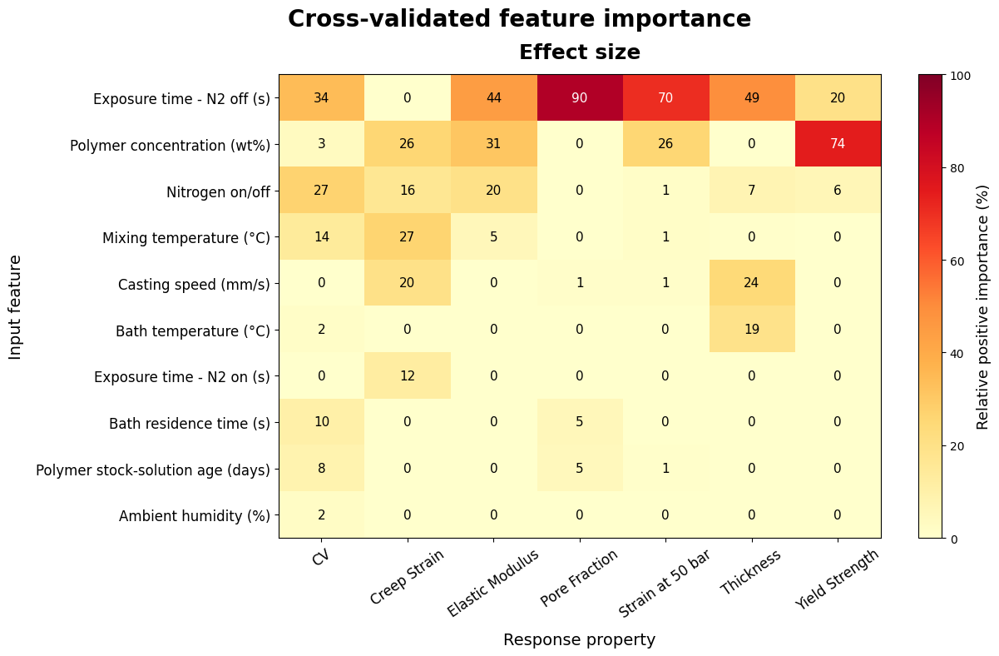

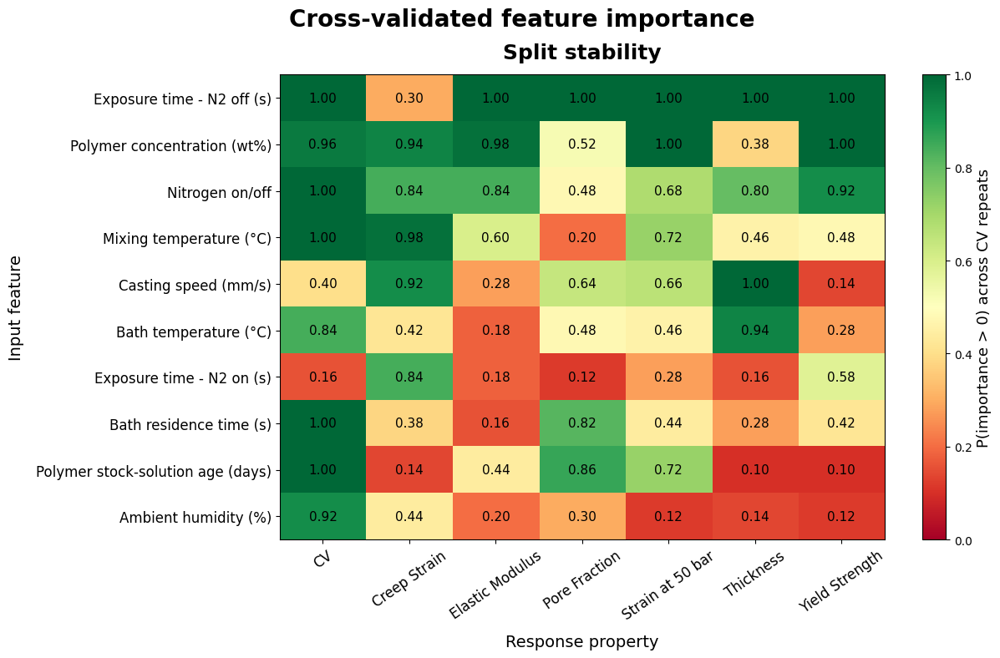

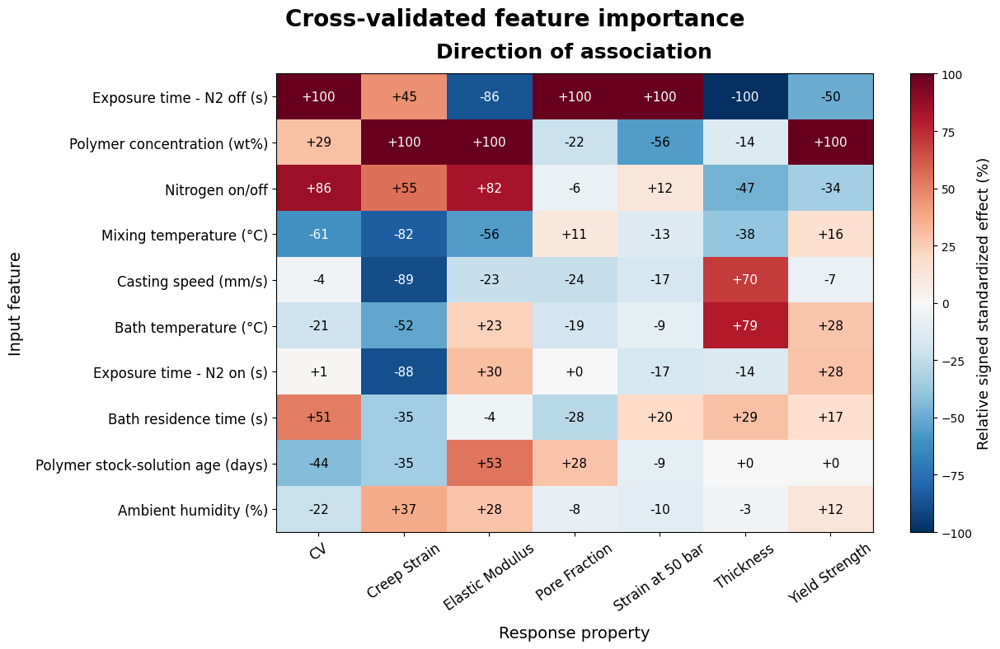

In [43]:
# Normalize positive importance within each property for a comparable 0–100% heatmap.
importance_for_plot = feature_importance.copy()
importance_for_plot['positive_importance'] = importance_for_plot['importance_mean'].clip(lower=0)
importance_for_plot['relative_importance'] = importance_for_plot.groupby('property')['positive_importance'].transform(
    lambda values: 100 * values / values.sum() if values.sum() > 0 else values
)
importance_matrix = importance_for_plot.pivot(index='feature', columns='property', values='relative_importance').fillna(0)
feature_order = importance_matrix.max(axis=1).sort_values(ascending=False).index
importance_matrix = importance_matrix.loc[feature_order]
confidence_matrix = importance_for_plot.pivot(index='feature', columns='property', values='probability_positive').fillna(0.5)
confidence_matrix = confidence_matrix.reindex(index=feature_order, columns=importance_matrix.columns)
importance_for_plot['relative_signed_effect'] = importance_for_plot.groupby('property')['signed_effect_mean'].transform(
    lambda values: 100 * values / values.abs().max() if values.abs().max() > 0 else values
)
signed_effect_matrix = importance_for_plot.pivot(index='feature', columns='property', values='relative_signed_effect').fillna(0)
signed_effect_matrix = signed_effect_matrix.reindex(index=feature_order, columns=importance_matrix.columns)

importance_figsize = (max(12, 1.8 * len(importance_matrix.columns)), max(7, 0.8 * len(importance_matrix.index)))
figure_importance, importance_axis = plt.subplots(figsize=importance_figsize)
figure_importance_confidence, confidence_axis = plt.subplots(figsize=importance_figsize)
figure_importance_direction, signed_effect_axis = plt.subplots(figsize=importance_figsize)
heatmap = importance_axis.imshow(importance_matrix.to_numpy(), cmap='YlOrRd', vmin=0, vmax=100, aspect='auto')
confidence_heatmap = confidence_axis.imshow(confidence_matrix.to_numpy(), cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
signed_effect_heatmap = signed_effect_axis.imshow(signed_effect_matrix.to_numpy(), cmap='RdBu_r', vmin=-100, vmax=100, aspect='auto')
for axis, matrix in [(importance_axis, importance_matrix), (confidence_axis, confidence_matrix),
                     (signed_effect_axis, signed_effect_matrix)]:
    axis.set_xticks(range(len(matrix.columns)))
    axis.set_xticklabels(matrix.columns)
    axis.set_yticks(range(len(matrix.index)))
    axis.set_yticklabels(matrix.index)
    axis.tick_params(axis='x', labelsize=12, rotation=35)
    axis.tick_params(axis='y', labelsize=12)
for row_index in range(len(importance_matrix.index)):
    for column_index in range(len(importance_matrix.columns)):
        effect = importance_matrix.iloc[row_index, column_index]
        confidence = confidence_matrix.iloc[row_index, column_index]
        signed_effect = signed_effect_matrix.iloc[row_index, column_index]
        importance_axis.text(column_index, row_index, f'{effect:.0f}', ha='center', va='center',
                             fontsize=11, color='white' if effect > 55 else 'black')
        confidence_axis.text(column_index, row_index, f'{confidence:.2f}', ha='center', va='center', fontsize=11)
        signed_effect_axis.text(column_index, row_index, f'{signed_effect:+.0f}', ha='center', va='center',
                                fontsize=11, color='white' if abs(signed_effect) > 60 else 'black')
importance_colorbar = figure_importance.colorbar(heatmap, ax=importance_axis)
importance_colorbar.set_label('Relative positive importance (%)', fontsize=13)
confidence_colorbar = figure_importance_confidence.colorbar(confidence_heatmap, ax=confidence_axis)
confidence_colorbar.set_label('P(importance > 0) across CV repeats', fontsize=13)
signed_effect_colorbar = figure_importance_direction.colorbar(signed_effect_heatmap, ax=signed_effect_axis)
signed_effect_colorbar.set_label('Relative signed standardized effect (%)', fontsize=13)
importance_axis.set_title('Effect size', fontsize=18, fontweight='semibold', pad=14)
confidence_axis.set_title('Split stability', fontsize=18, fontweight='semibold', pad=14)
signed_effect_axis.set_title('Direction of association', fontsize=18, fontweight='semibold', pad=14)
importance_axis.set_xlabel('Response property', fontsize=14, labelpad=10)
confidence_axis.set_xlabel('Response property', fontsize=14, labelpad=10)
signed_effect_axis.set_xlabel('Response property', fontsize=14, labelpad=10)
importance_axis.set_ylabel('Input feature', fontsize=14, labelpad=10)
confidence_axis.set_ylabel('Input feature', fontsize=14, labelpad=10)
signed_effect_axis.set_ylabel('Input feature', fontsize=14, labelpad=10)
for figure in (figure_importance, figure_importance_confidence, figure_importance_direction):
    figure.suptitle('Cross-validated feature importance', fontsize=20, fontweight='semibold')
    figure.tight_layout()
plt.show()

## Coupled nitrogen–exposure response surfaces

These panels use the same ridge specification to predict each property while varying nitrogen state and coupon-to-bath exposure time together. All other features are held at their median values. Black-edged points are the actual experiments. Because nitrogen is binary, only the **off** and **on** rows are physically observed; shading between them is visual interpolation, not an intermediate nitrogen setting.

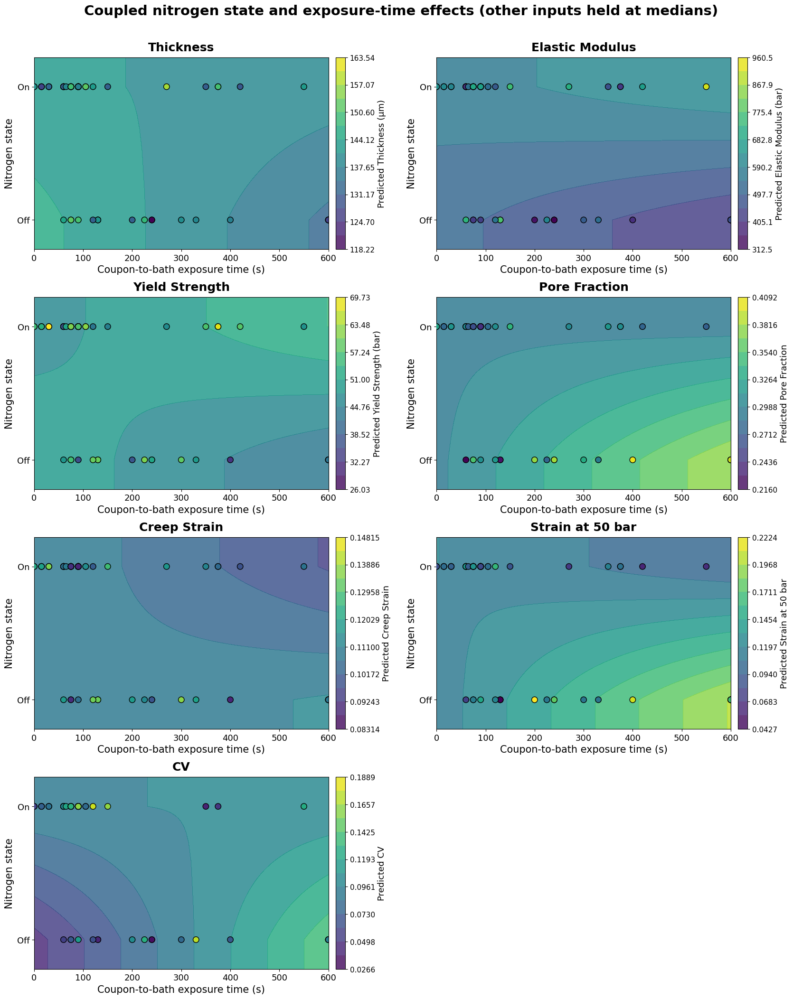

In [44]:
def fit_ridge_response_surface(data, property_name, features=FEATURES):
    target_column = f'{property_name} Mean'
    usable = data.dropna(subset=[target_column]).copy()
    X = usable[list(features)].copy()
    X['nitrogen'] = X['nitrogen'].map(nitrogen_to_binary)
    X = X.apply(pd.to_numeric, errors='coerce')
    variable_columns = [column for column in X if X[column].nunique(dropna=True) > 1]
    X = X[variable_columns]
    medians = X.median()
    X_numeric = X.fillna(medians).to_numpy(dtype=float)
    center, scale = X_numeric.mean(axis=0), X_numeric.std(axis=0)
    scale[scale == 0] = 1
    X_standardized = (X_numeric - center) / scale
    y = pd.to_numeric(usable[target_column], errors='coerce').to_numpy(dtype=float)
    baseline = y.mean()
    coefficients = np.linalg.solve(
        X_standardized.T @ X_standardized + RIDGE_ALPHA * np.eye(X_standardized.shape[1]),
        X_standardized.T @ (y - baseline),
    )
    exposure_grid = np.linspace(0, data['coupon_to_bath_wait_time'].max(), 121)
    surface_rows = []
    for nitrogen_state in (0, 1):
        grid = pd.DataFrame([medians.to_dict()] * len(exposure_grid))[variable_columns]
        if 'nitrogen' in grid:
            grid['nitrogen'] = nitrogen_state
        if 'nitrogen_exposure_time' in grid:
            grid['nitrogen_exposure_time'] = exposure_grid * nitrogen_state
        if 'air_exposure_time' in grid:
            grid['air_exposure_time'] = exposure_grid * (1 - nitrogen_state)
        grid_standardized = (grid.to_numpy(dtype=float) - center) / scale
        surface_rows.append(baseline + grid_standardized @ coefficients)
    return exposure_grid, np.vstack(surface_rows), usable

surface_properties = [prop for prop in FEATURE_IMPORTANCE_PROPERTIES
                      if campaign_detailed[f'{prop} Mean'].notna().sum() >= MIN_TARGET_SAMPLES]
surface_columns = 2
surface_rows = int(np.ceil(len(surface_properties) / surface_columns))
figure_nitrogen_exposure, surface_grid = plt.subplots(
    surface_rows, surface_columns, figsize=(17, 5.2 * surface_rows), squeeze=False
)
axes_nitrogen_exposure = list(surface_grid.flat)
for axis, property_name in zip(axes_nitrogen_exposure, surface_properties):
    exposure_grid, predicted_surface, observed = fit_ridge_response_surface(campaign_detailed, property_name)
    target_column = f'{property_name} Mean'
    value_min = min(predicted_surface.min(), observed[target_column].min())
    value_max = max(predicted_surface.max(), observed[target_column].max())
    levels = np.linspace(value_min, value_max, 15)
    # Duplicate the binary-state predictions into padded margins so observations
    # at 0 and 1 sit inside the colored field rather than on its outer edges.
    padded_states = [-0.22, 0, 1, 1.22]
    padded_surface = np.vstack([predicted_surface[0], predicted_surface[0],
                                predicted_surface[1], predicted_surface[1]])
    contour = axis.contourf(exposure_grid, padded_states, padded_surface, levels=levels, cmap='viridis', alpha=0.82)
    axis.scatter(observed['coupon_to_bath_wait_time'], observed['nitrogen_binary'],
                 c=observed[target_column], cmap='viridis', vmin=value_min, vmax=value_max,
                 s=80, edgecolor='black', linewidth=1.0, zorder=3)
    axis.set_title(property_name, fontsize=18, fontweight='semibold', pad=10)
    axis.set_xlabel('Coupon-to-bath exposure time (s)', fontsize=15)
    axis.set_ylabel('Nitrogen state', fontsize=15)
    axis.set_yticks([0, 1])
    axis.set_yticklabels(['Off', 'On'], fontsize=13)
    axis.set_ylim(-0.22, 1.22)
    axis.tick_params(axis='x', labelsize=13)
    property_colorbar = figure_nitrogen_exposure.colorbar(contour, ax=axis, pad=0.02)
    property_colorbar.set_label(f'Predicted {property_label(property_name)}', fontsize=13)
    property_colorbar.ax.tick_params(labelsize=11)
for axis in axes_nitrogen_exposure[len(surface_properties):]:
    axis.remove()
figure_nitrogen_exposure.suptitle(
    'Coupled nitrogen state and exposure-time effects (other inputs held at medians)',
    fontsize=21, fontweight='semibold', y=1.01
)
figure_nitrogen_exposure.tight_layout()
plt.show()

## Ambient-humidity–exposure response surfaces

These panels vary ambient SHT40 humidity and coupon-to-bath exposure time while holding the remaining inputs at their medians. Predictions are averaged equally across a nitrogen-off prediction and a nitrogen-on prediction, so the surface represents a balanced nitrogen-marginalized response rather than assuming one nitrogen state. Actual experiments are overlaid as circles (N2 on) and squares (N2 off).

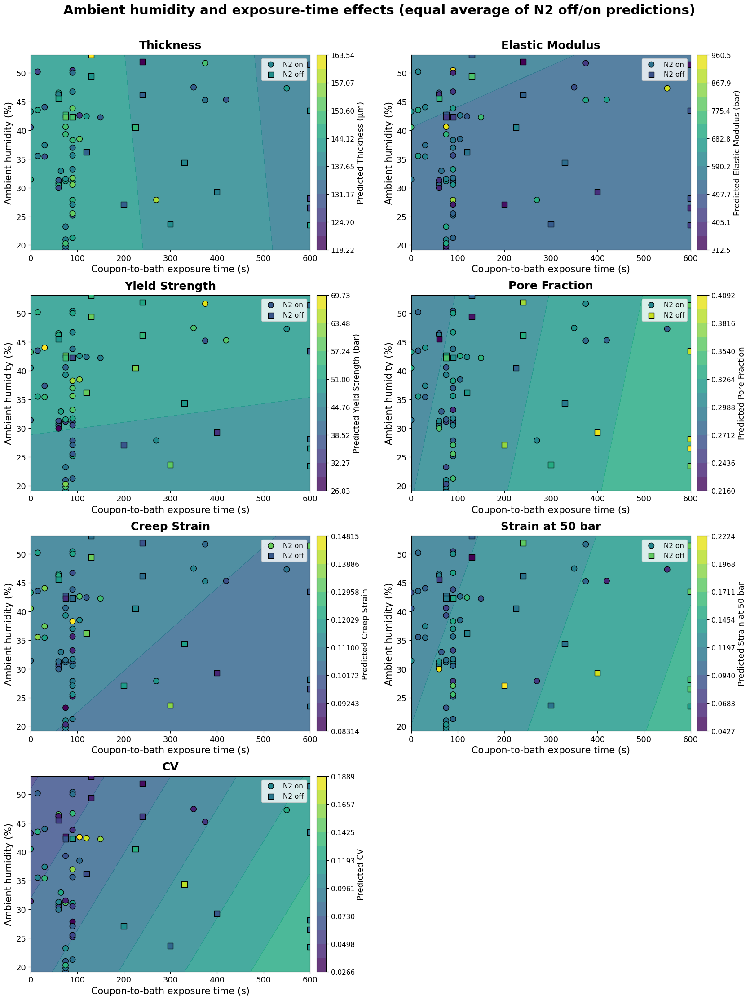

In [45]:
def fit_humidity_exposure_surface(data, property_name, features=FEATURES):
    target_column = f'{property_name} Mean'
    usable = data.dropna(subset=[target_column]).copy()
    X = usable[list(features)].copy()
    X['nitrogen'] = X['nitrogen'].map(nitrogen_to_binary)
    X = X.apply(pd.to_numeric, errors='coerce')
    variable_columns = [column for column in X if X[column].nunique(dropna=True) > 1]
    X = X[variable_columns]
    medians = X.median()
    X_numeric = X.fillna(medians).to_numpy(dtype=float)
    center, scale = X_numeric.mean(axis=0), X_numeric.std(axis=0)
    scale[scale == 0] = 1
    X_standardized = (X_numeric - center) / scale
    y = pd.to_numeric(usable[target_column], errors='coerce').to_numpy(dtype=float)
    baseline = y.mean()
    coefficients = np.linalg.solve(
        X_standardized.T @ X_standardized + RIDGE_ALPHA * np.eye(X_standardized.shape[1]),
        X_standardized.T @ (y - baseline),
    )
    humidity_observed = pd.to_numeric(data['Humidity Mean'], errors='coerce').dropna()
    humidity_grid = np.linspace(humidity_observed.min(), humidity_observed.max(), 80)
    exposure_grid = np.linspace(0, data['coupon_to_bath_wait_time'].max(), 100)
    exposure_mesh, humidity_mesh = np.meshgrid(exposure_grid, humidity_grid)
    state_predictions = []
    for nitrogen_state in (0, 1):
        grid = pd.DataFrame([medians.to_dict()] * exposure_mesh.size)[variable_columns]
        if 'Humidity Mean' in grid:
            grid['Humidity Mean'] = humidity_mesh.ravel()
        if 'nitrogen' in grid:
            grid['nitrogen'] = nitrogen_state
        if 'nitrogen_exposure_time' in grid:
            grid['nitrogen_exposure_time'] = exposure_mesh.ravel() * nitrogen_state
        if 'air_exposure_time' in grid:
            grid['air_exposure_time'] = exposure_mesh.ravel() * (1 - nitrogen_state)
        grid_standardized = (grid.to_numpy(dtype=float) - center) / scale
        state_predictions.append((baseline + grid_standardized @ coefficients).reshape(humidity_mesh.shape))
    marginalized_surface = np.mean(state_predictions, axis=0)
    return exposure_mesh, humidity_mesh, marginalized_surface, usable

figure_humidity_exposure, humidity_surface_grid = plt.subplots(
    surface_rows, surface_columns, figsize=(17, 5.5 * surface_rows), squeeze=False
)
axes_humidity_exposure = list(humidity_surface_grid.flat)
for axis, property_name in zip(axes_humidity_exposure, surface_properties):
    exposure_mesh, humidity_mesh, predicted_surface, observed = fit_humidity_exposure_surface(
        campaign_detailed, property_name
    )
    target_column = f'{property_name} Mean'
    value_min = min(predicted_surface.min(), observed[target_column].min())
    value_max = max(predicted_surface.max(), observed[target_column].max())
    levels = np.linspace(value_min, value_max, 15)
    contour = axis.contourf(exposure_mesh, humidity_mesh, predicted_surface,
                            levels=levels, cmap='viridis', alpha=0.82)
    for nitrogen_state, marker, label in [(1, 'o', 'N2 on'), (0, 's', 'N2 off')]:
        state_points = observed[observed['nitrogen_binary'] == nitrogen_state]
        axis.scatter(state_points['coupon_to_bath_wait_time'], state_points['Humidity Mean'],
                     c=state_points[target_column], cmap='viridis', vmin=value_min, vmax=value_max,
                     marker=marker, s=80, edgecolor='black', linewidth=1.0, label=label, zorder=3)
    axis.set_title(property_name, fontsize=18, fontweight='semibold', pad=10)
    axis.set_xlabel('Coupon-to-bath exposure time (s)', fontsize=15)
    axis.set_ylabel('Ambient humidity (%)', fontsize=15)
    axis.tick_params(labelsize=13)
    axis.legend(fontsize=11, loc='best', frameon=True)
    property_colorbar = figure_humidity_exposure.colorbar(contour, ax=axis, pad=0.02)
    property_colorbar.set_label(f'Predicted {property_label(property_name)}', fontsize=13)
    property_colorbar.ax.tick_params(labelsize=11)
for axis in axes_humidity_exposure[len(surface_properties):]:
    axis.remove()
figure_humidity_exposure.suptitle(
    'Ambient humidity and exposure-time effects (equal average of N2 off/on predictions)',
    fontsize=21, fontweight='semibold', y=1.01
)
figure_humidity_exposure.tight_layout()
plt.show()

## Cross-validated pairwise interactions

Each hierarchical ridge model keeps every main effect and adds one standardized pairwise product. Positive MAE improvement means the interaction improves held-out prediction. The signed coefficient indicates whether a joint high–high setting predicts more (+) or less (−) than the additive effects imply. Stability is the fraction of 50 repeated CV splits improved by the interaction. These are exploratory conditional associations, not causal effects.

In [46]:
INTERACTION_FEATURES = {
    'polymer_solution_age_days': 'Polymer stock-solution age (days)',
    'polymer_wt': 'Polymer concentration (wt%)', 'mixing_temp': 'Mixing temperature (°C)',
    'bath_temp': 'Bath temperature (°C)', 'pullcast_speed': 'Casting speed (mm/s)',
    'nitrogen': 'Nitrogen on/off', 'coupon_to_bath_wait_time': 'Exposure time (s)',
    'nips_bath_wait_time': 'Bath residence time (s)',
    'nips_bath_solvent_wt_percent': 'NIPS bath solvent concentration (wt%)', 'Humidity Mean': 'Ambient humidity (%)'}
INTERACTION_PAIRS = [('polymer_solution_age_days', 'polymer_wt'),
                     ('polymer_solution_age_days', 'mixing_temp'),
                     ('nitrogen', 'coupon_to_bath_wait_time'),
                     ('Humidity Mean', 'coupon_to_bath_wait_time'),
                     ('polymer_wt', 'mixing_temp'), ('polymer_wt', 'bath_temp'),
                     ('bath_temp', 'nips_bath_wait_time'),
                     ('nips_bath_solvent_wt_percent', 'bath_temp'),
                     ('nips_bath_solvent_wt_percent', 'nips_bath_wait_time')]

def ridge_fit_predict(train, test, response):
    center = response.mean()
    coef = np.linalg.solve(train.T @ train + RIDGE_ALPHA * np.eye(train.shape[1]),
                           train.T @ (response - center))
    return center + test @ coef, coef

def repeated_interaction_analysis(data, properties):
    records = []
    for prop in properties:
        usable = data.dropna(subset=[f'{prop} Mean']).copy()
        if len(usable) < MIN_TARGET_SAMPLES: continue
        frame = usable[list(INTERACTION_FEATURES)].copy()
        frame['nitrogen'] = frame['nitrogen'].map(nitrogen_to_binary)
        frame = frame.apply(pd.to_numeric, errors='coerce')
        columns = [c for c in frame if frame[c].nunique(dropna=True) > 1]
        frame, response = frame[columns], pd.to_numeric(usable[f'{prop} Mean']).to_numpy(float)
        folds = min(5, max(3, len(frame) // 5))
        for first, second in INTERACTION_PAIRS:
            if first not in columns or second not in columns: continue
            gains, effects = [], []
            a, b = columns.index(first), columns.index(second)
            for repeat in range(N_CV_REPEATS):
                order = np.random.RandomState(RANDOM_STATE + repeat).permutation(len(frame))
                gain_sum = effect_sum = count = 0
                for test_index in np.array_split(order, folds):
                    train_index = np.setdiff1d(order, test_index)
                    train_frame, test_frame = frame.iloc[train_index], frame.iloc[test_index]
                    medians = train_frame.median()
                    train, test = train_frame.fillna(medians).to_numpy(float), test_frame.fillna(medians).to_numpy(float)
                    center, scale = train.mean(0), train.std(0); scale[scale == 0] = 1
                    train, test = (train-center)/scale, (test-center)/scale
                    train_product, test_product = train[:, a]*train[:, b], test[:, a]*test[:, b]
                    product_center, product_scale = train_product.mean(), train_product.std() or 1
                    train_product, test_product = (train_product-product_center)/product_scale, (test_product-product_center)/product_scale
                    y_train, y_test = response[train_index], response[test_index]
                    additive, _ = ridge_fit_predict(train, test, y_train)
                    coupled, coef = ridge_fit_predict(np.c_[train, train_product], np.c_[test, test_product], y_train)
                    n = len(test_index); count += n
                    gain_sum += (np.mean(abs(y_test-additive)) - np.mean(abs(y_test-coupled))) * n
                    effect_sum += coef[-1] * n
                gains.append(gain_sum/count); effects.append(effect_sum/count)
            gains, effects = np.asarray(gains), np.asarray(effects)
            low, high = np.percentile(gains, [2.5, 97.5])
            records.append({'property': prop, 'interaction': f'{INTERACTION_FEATURES[first]} × {INTERACTION_FEATURES[second]}',
                'mae_improvement_mean': gains.mean(), 'mae_improvement_interval_low': low,
                'mae_improvement_interval_high': high, 'probability_improves': np.mean(gains > 0),
                'interaction_effect_mean': effects.mean(),
                'interaction_effect_interval_low': np.percentile(effects, 2.5),
                'interaction_effect_interval_high': np.percentile(effects, 97.5),
                'support': 'supported' if low > 0 else 'uncertain', 'n_samples': len(usable)})
    return pd.DataFrame(records)

interaction_results = repeated_interaction_analysis(campaign_detailed, FEATURE_IMPORTANCE_PROPERTIES)
interaction_results.sort_values(['property', 'mae_improvement_mean'], ascending=[True, False]).head(20)

,property,interaction,mae_improvement_mean,mae_improvement_interval_low,mae_improvement_interval_high,probability_improves,interaction_effect_mean,interaction_effect_interval_low,interaction_effect_interval_high,support,n_samples
44,CV,Nitrogen on/off × Exposure time (s),0.000390,-0.001092,0.002178,0.74,-0.014666,-0.015619,-0.013208,uncertain,65
45,CV,Ambient humidity (%) × Exposure time (s),-0.000026,-0.001365,0.001133,0.46,-0.007177,-0.007772,-0.006715,uncertain,65
43,CV,Polymer stock-solution age (days) × Mixing tem...,-0.000056,-0.002690,0.001913,0.46,0.009944,0.009201,0.010877,uncertain,65
47,CV,Polymer concentration (wt%) × Bath temperature...,-0.000439,-0.001897,0.000179,0.14,-0.000657,-0.001459,0.000277,uncertain,65
42,CV,Polymer stock-solution age (days) × Polymer co...,-0.000566,-0.002244,0.000552,0.28,0.006015,0.005311,0.007149,uncertain,65
48,CV,Bath temperature (°C) × Bath residence time (s),-0.000715,-0.002329,0.000320,0.12,-0.002671,-0.003337,-0.001586,uncertain,65
46,CV,Polymer concentration (wt%) × Mixing temperatu...,-0.000717,-0.002106,0.000113,0.06,-0.000219,-0.000806,0.000400,uncertain,65
30,Creep Strain,Nitrogen on/off × Exposure time (s),0.000086,-0.000291,0.000344,0.72,-0.002674,-0.002897,-0.002444,uncertain,72
34,Creep Strain,Bath temperature (°C) × Bath residence time (s),-0.000074,-0.000512,0.000307,0.36,-0.001442,-0.001681,-0.001193,uncertain,72
33,Creep Strain,Polymer concentration (wt%) × Bath temperature...,-0.000171,-0.000614,0.000103,0.14,0.001702,0.001475,0.001916,uncertain,72


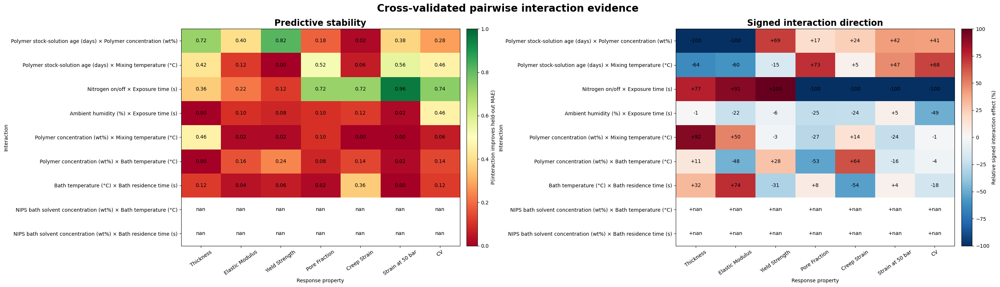

In [47]:
interaction_labels = [f'{INTERACTION_FEATURES[a]} × {INTERACTION_FEATURES[b]}' for a, b in INTERACTION_PAIRS]
interaction_properties = [p for p in FEATURE_IMPORTANCE_PROPERTIES if p in interaction_results.property.unique()]
gain = interaction_results.pivot(index='interaction', columns='property', values='probability_improves').reindex(index=interaction_labels, columns=interaction_properties)
direction = interaction_results.pivot(index='interaction', columns='property', values='interaction_effect_mean').reindex(index=interaction_labels, columns=interaction_properties)
direction = direction.apply(lambda x: 100*x/x.abs().max() if x.abs().max() else x)
figure_interactions, interaction_axes = plt.subplots(1, 2, figsize=(max(18, 4*len(interaction_properties)), 8))
for axis, matrix, cmap, limits, title, label in [(interaction_axes[0], gain, 'RdYlGn', (0,1), 'Predictive stability', 'P(interaction improves held-out MAE)'), (interaction_axes[1], direction, 'RdBu_r', (-100,100), 'Signed interaction direction', 'Relative signed interaction effect (%)')]:
    image = axis.imshow(matrix, cmap=cmap, vmin=limits[0], vmax=limits[1], aspect='auto')
    axis.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=35); axis.set_yticks(range(len(matrix.index)), matrix.index)
    for row in range(len(matrix.index)):
        for column in range(len(matrix.columns)):
            value = matrix.iloc[row, column]; text = f'{value:.2f}' if limits[1] == 1 else f'{value:+.0f}'
            axis.text(column, row, text, ha='center', va='center', fontsize=10)
    axis.set_title(title, fontsize=17, fontweight='semibold'); axis.set_xlabel('Response property'); axis.set_ylabel('Interaction')
    figure_interactions.colorbar(image, ax=axis, pad=.02).set_label(label)
figure_interactions.suptitle('Cross-validated pairwise interaction evidence', fontsize=20, fontweight='semibold')
figure_interactions.tight_layout(); plt.show()

## Linear SHAP analysis

For the standardized ridge model, the SHAP contribution under a mean-background/feature-independence assumption is `(standardized feature value) × (ridge coefficient)`. The contributions are additive: their sum plus the baseline prediction equals the model prediction. Positive values push a predicted property upward; negative values push it downward.

The first figure summarizes global mean absolute SHAP magnitude. It is followed by a signed per-iteration contribution plot for every modeled response; point color indicates the original feature value. These are model explanations, not causal effects. Correlated campaign settings can redistribute attribution among features.

In [48]:
def calculate_linear_shap(data, properties, features=FEATURES):
    shap_records = []
    prediction_records = []
    for property_name in properties:
        target_column = f'{property_name} Mean'
        usable = data.dropna(subset=[target_column]).copy()
        if len(usable) < MIN_TARGET_SAMPLES:
            continue
        X = usable[list(features)].copy()
        X['nitrogen'] = X['nitrogen'].map(nitrogen_to_binary)
        X = X.apply(pd.to_numeric, errors='coerce')
        variable_columns = [column for column in X if X[column].nunique(dropna=True) > 1]
        X = X[variable_columns]
        medians = X.median()
        X_numeric = X.fillna(medians).to_numpy(dtype=float)
        center, scale = X_numeric.mean(axis=0), X_numeric.std(axis=0)
        scale[scale == 0] = 1
        X_standardized = (X_numeric - center) / scale
        y = pd.to_numeric(usable[target_column], errors='coerce').to_numpy(dtype=float)
        baseline = y.mean()
        coefficients = np.linalg.solve(
            X_standardized.T @ X_standardized + RIDGE_ALPHA * np.eye(X_standardized.shape[1]),
            X_standardized.T @ (y - baseline),
        )
        shap_values = X_standardized * coefficients
        predictions = baseline + shap_values.sum(axis=1)
        for row_position, (_, sample) in enumerate(usable.iterrows()):
            prediction_records.append({
                'property': property_name, 'iteration': sample['iteration'],
                'observed': y[row_position], 'prediction': predictions[row_position],
                'baseline': baseline,
            })
            for feature_position, feature in enumerate(variable_columns):
                shap_records.append({
                    'property': property_name, 'iteration': sample['iteration'],
                    'feature': features[feature], 'feature_column': feature,
                    'feature_value': X_numeric[row_position, feature_position],
                    'shap_value': shap_values[row_position, feature_position],
                })
    return pd.DataFrame(shap_records), pd.DataFrame(prediction_records)

shap_values, shap_predictions = calculate_linear_shap(
    campaign_detailed, FEATURE_IMPORTANCE_PROPERTIES
)
# Numerical check of the additive SHAP identity.
assert np.allclose(
    shap_predictions['prediction'],
    shap_predictions['baseline'] + shap_values.groupby(['property', 'iteration'])['shap_value'].sum().reindex(
        pd.MultiIndex.from_frame(shap_predictions[['property', 'iteration']])
    ).to_numpy(),
)
shap_values.head()

,property,iteration,feature,feature_column,feature_value,shap_value
0,Thickness,1,Polymer stock-solution age (days),polymer_solution_age_days,2.0,0.009581
1,Thickness,1,Polymer concentration (wt%),polymer_wt,17.0,0.520625
2,Thickness,1,Mixing temperature (°C),mixing_temp,25.0,2.739993
3,Thickness,1,Bath temperature (°C),bath_temp,5.0,-3.460717
4,Thickness,1,Casting speed (mm/s),pullcast_speed,10.0,-0.017209


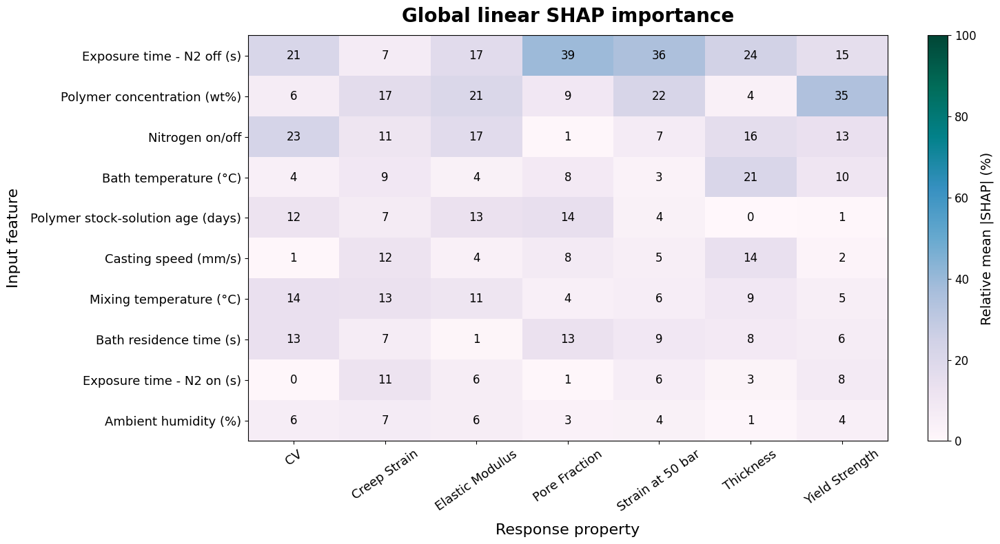

In [49]:
global_shap = (shap_values.assign(abs_shap=lambda frame: frame['shap_value'].abs())
               .groupby(['feature', 'property'], as_index=False)['abs_shap'].mean())
global_shap['relative_mean_abs_shap'] = global_shap.groupby('property')['abs_shap'].transform(
    lambda values: 100 * values / values.sum() if values.sum() > 0 else values
)
shap_matrix = global_shap.pivot(index='feature', columns='property', values='relative_mean_abs_shap').fillna(0)
shap_matrix = shap_matrix.loc[shap_matrix.max(axis=1).sort_values(ascending=False).index]

figure_shap_global, shap_global_axis = plt.subplots(
    figsize=(max(12, 2.2 * len(shap_matrix.columns)), max(7, 0.8 * len(shap_matrix.index)))
)
shap_image = shap_global_axis.imshow(shap_matrix.to_numpy(), cmap='PuBuGn', vmin=0, vmax=100, aspect='auto')
shap_global_axis.set_xticks(range(len(shap_matrix.columns)))
shap_global_axis.set_xticklabels(shap_matrix.columns)
shap_global_axis.set_yticks(range(len(shap_matrix.index)))
shap_global_axis.set_yticklabels(shap_matrix.index)
for row_index in range(len(shap_matrix.index)):
    for column_index in range(len(shap_matrix.columns)):
        value = shap_matrix.iloc[row_index, column_index]
        shap_global_axis.text(column_index, row_index, f'{value:.0f}', ha='center', va='center',
                              fontsize=12, color='white' if value > 55 else 'black')
shap_global_colorbar = figure_shap_global.colorbar(shap_image, ax=shap_global_axis)
shap_global_colorbar.set_label('Relative mean |SHAP| (%)', fontsize=14)
shap_global_colorbar.ax.tick_params(labelsize=12)
shap_global_axis.set_title('Global linear SHAP importance', fontsize=20, fontweight='semibold', pad=14)
shap_global_axis.set_xlabel('Response property', fontsize=16, labelpad=10)
shap_global_axis.set_ylabel('Input feature', fontsize=16, labelpad=10)
shap_global_axis.tick_params(axis='x', labelsize=13, rotation=35)
shap_global_axis.tick_params(axis='y', labelsize=13)
figure_shap_global.tight_layout()
plt.show()

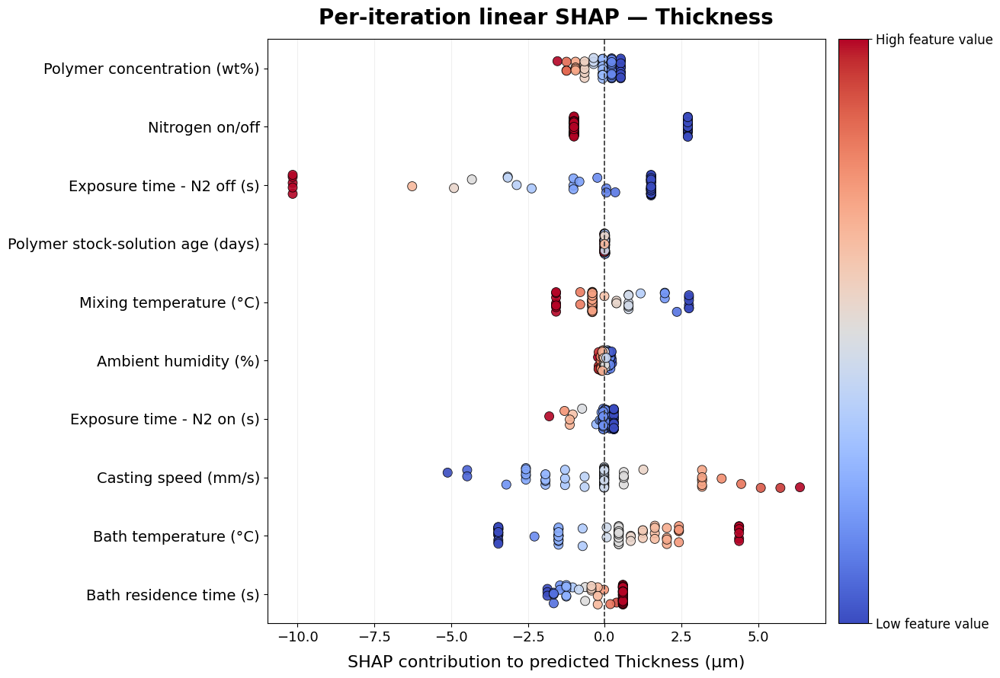

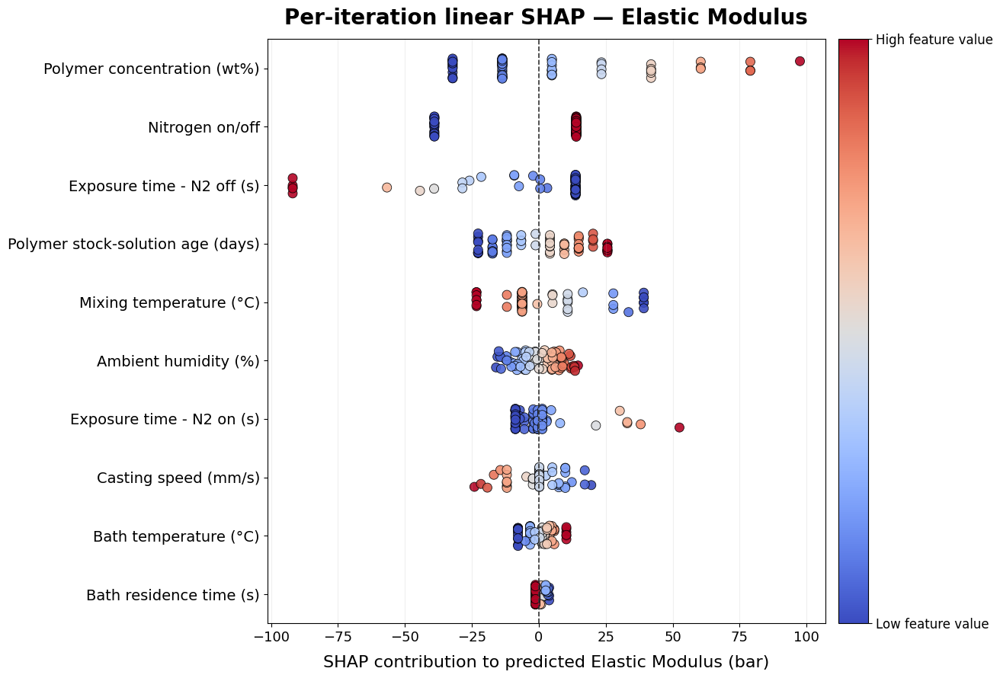

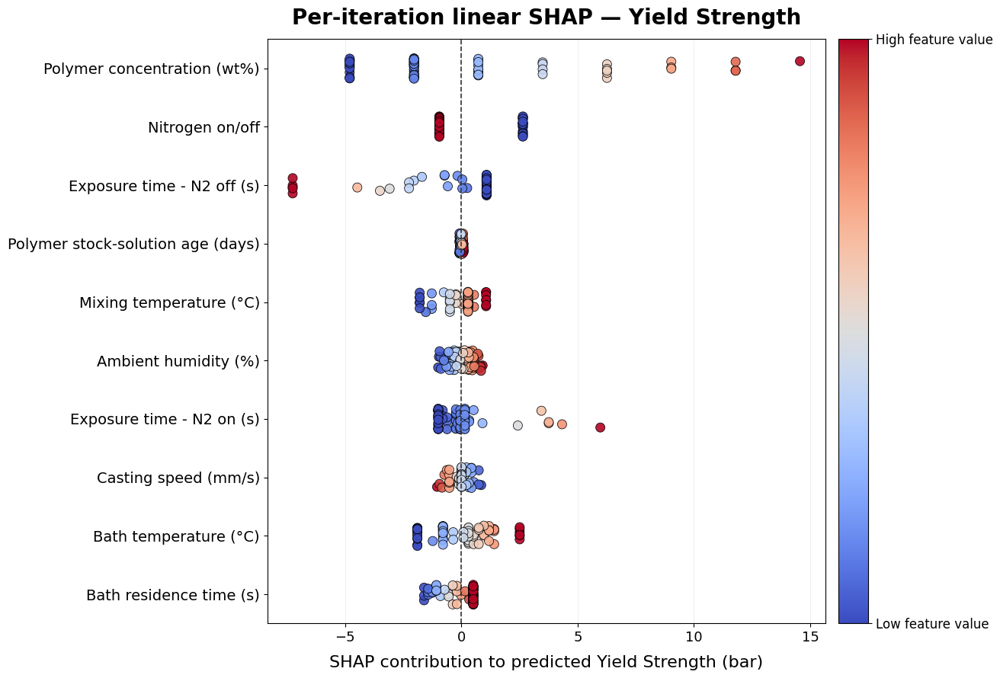

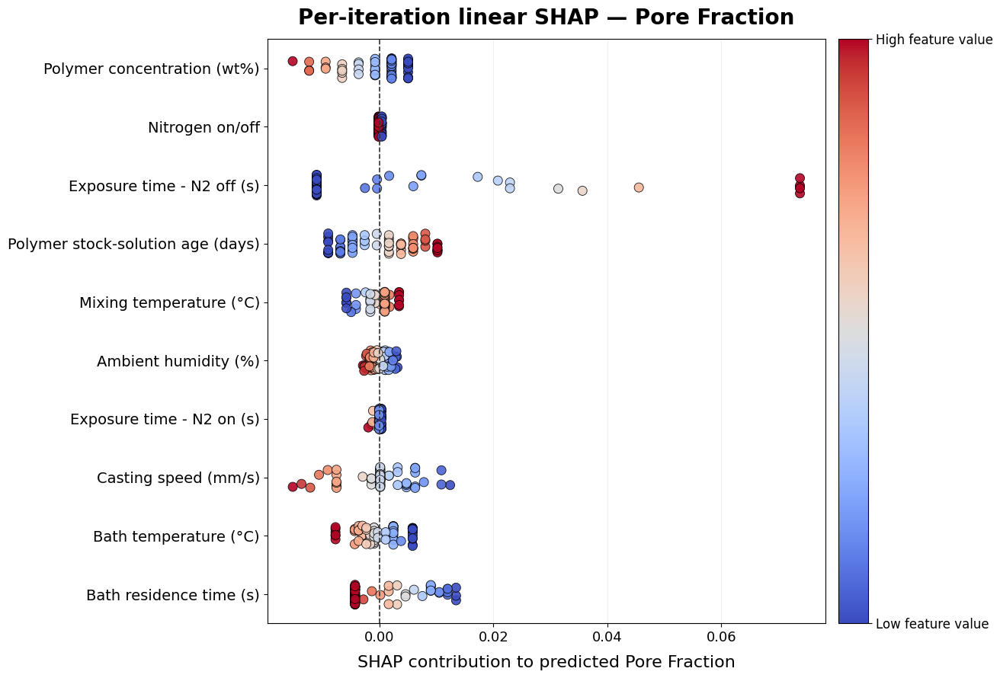

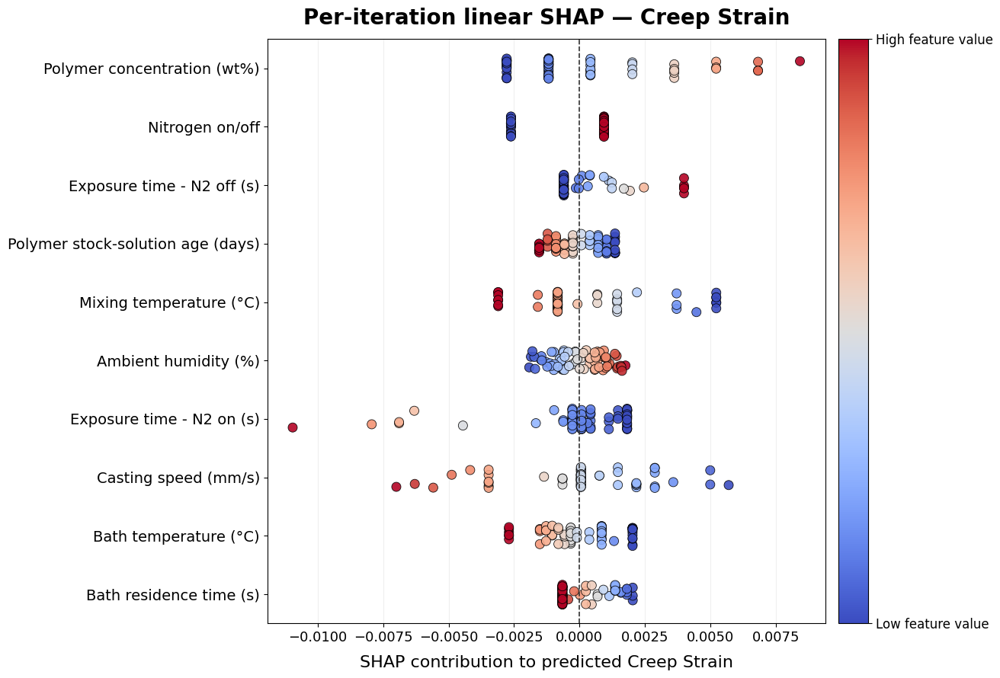

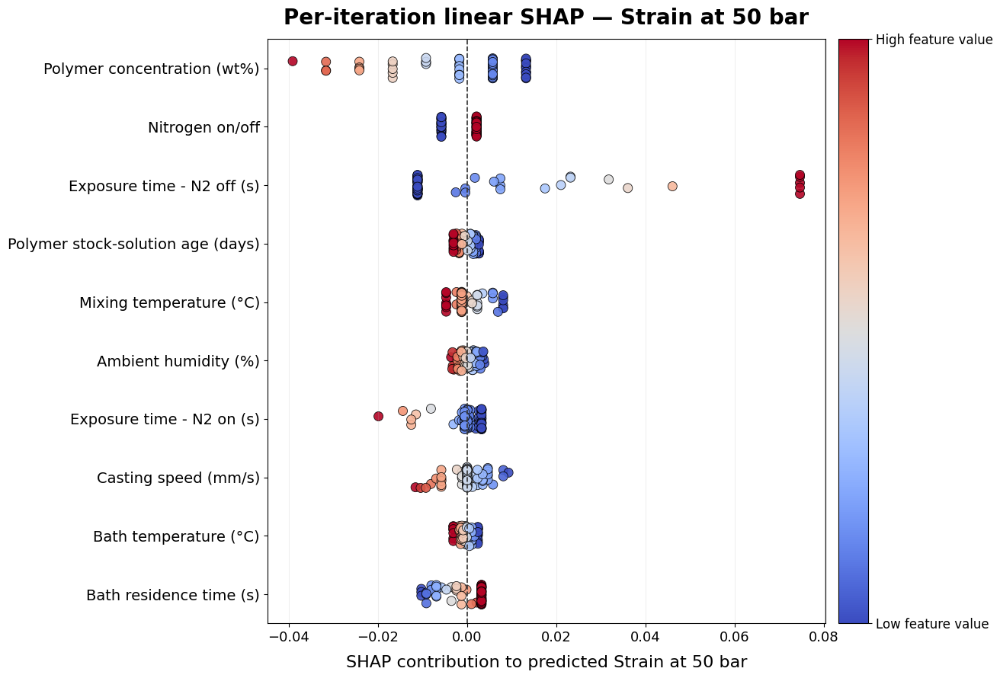

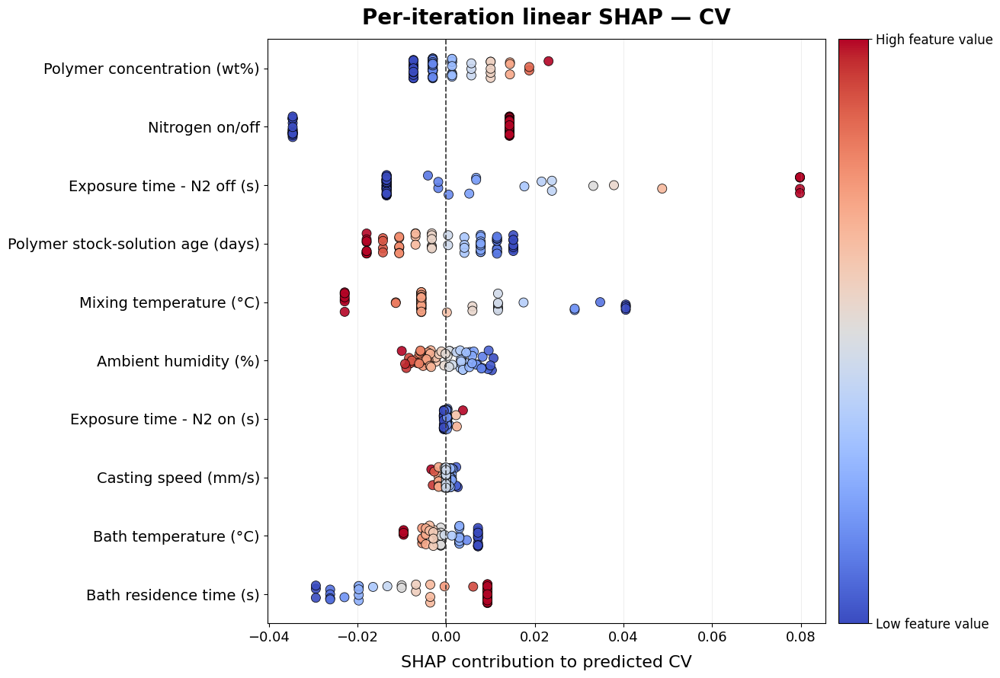

In [50]:
# Use descending Elastic Modulus mean |SHAP| for every response (top to bottom).
modulus_shap = shap_values[shap_values['property'] == 'Elastic Modulus']
if modulus_shap.empty:
    raise ValueError('Elastic Modulus SHAP values are required for the shared parameter order.')
SHAP_FEATURE_ORDER = (modulus_shap.assign(abs_shap=modulus_shap['shap_value'].abs())
                      .groupby('feature')['abs_shap'].mean()
                      .sort_values(ascending=False, kind='stable').index.tolist())
# Keep any features absent from the modulus model at the bottom in a fixed order.
SHAP_FEATURE_ORDER += sorted(set(shap_values['feature']) - set(SHAP_FEATURE_ORDER))

def plot_shap_detail(detail, property_name, feature_order=None):
    feature_order = SHAP_FEATURE_ORDER if feature_order is None else list(feature_order)
    figure, axis = plt.subplots(figsize=(13, max(7, 0.9 * len(feature_order))))
    jitter_generator = np.random.RandomState(RANDOM_STATE)
    for feature_position, feature in enumerate(feature_order):
        feature_points = detail[detail['feature'] == feature].copy()
        if feature_points.empty:
            continue  # Preserve the shared row for features absent from this model.
        values = feature_points['feature_value'].to_numpy(dtype=float)
        value_min, value_max = np.nanmin(values), np.nanmax(values)
        normalized_values = np.full(len(values), 0.5) if value_min == value_max else (values - value_min) / (value_max - value_min)
        vertical_positions = feature_position + jitter_generator.uniform(-0.18, 0.18, len(feature_points))
        axis.scatter(feature_points['shap_value'], vertical_positions, c=normalized_values,
                     cmap='coolwarm', vmin=0, vmax=1, s=75, edgecolor='black', linewidth=0.6, alpha=0.9)
    axis.axvline(0, color='#333333', linestyle='--', linewidth=1.2)
    axis.set_yticks(range(len(feature_order)))
    axis.set_yticklabels(feature_order, fontsize=14)
    axis.set_ylim(len(feature_order) - 0.5, -0.5)
    axis.set_xlabel(f'SHAP contribution to predicted {property_label(property_name)}', fontsize=16, labelpad=10)
    axis.set_title(f'Per-iteration linear SHAP — {property_name}', fontsize=20, fontweight='semibold', pad=14)
    axis.tick_params(axis='x', labelsize=13)
    axis.grid(axis='x', alpha=0.2)
    color_scale = plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap='coolwarm')
    color_scale.set_array([])
    colorbar = figure.colorbar(color_scale, ax=axis, pad=0.02)
    colorbar.set_ticks([0, 1])
    colorbar.set_ticklabels(['Low feature value', 'High feature value'])
    colorbar.ax.tick_params(labelsize=12)
    figure.tight_layout()
    return figure, axis

figure_shap_details = {}
axes_shap_details = {}
for property_name in FEATURE_IMPORTANCE_PROPERTIES:
    detail = shap_values[shap_values['property'] == property_name].copy()
    if detail.empty:
        continue
    figure_shap_details[property_name], axes_shap_details[property_name] = plot_shap_detail(
        detail, property_name
    )
    plt.show()

## Elastic modulus–pore fraction Pareto frontier

These plots treat **higher Elastic Modulus and higher Pore Fraction as desirable**. A point is Pareto optimal when no other experiment is at least as high on both objectives and strictly higher on at least one. The black dashed line and larger black-framed dots show the observed Pareto frontier; it is a guide through measured non-dominated experiments, not a fitted response curve. Each panel colors the same experiments by one process or environmental parameter. Missing parameter values are gray.

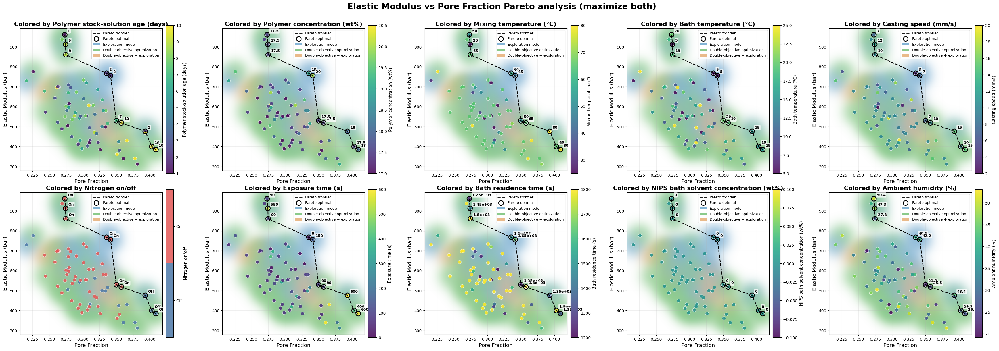

,iteration,Pore Fraction Mean,Elastic Modulus Mean,polymer_solution_age_days,polymer_wt,mixing_temp,bath_temp,pullcast_speed,nitrogen,coupon_to_bath_wait_time,nips_bath_wait_time,nips_bath_solvent_wt_percent,Humidity Mean
25,26,0.273146,960.516725,1.0,17.5,50,20,7,True,90,1250,0.0,50.42
21,22,0.274343,912.838324,9.0,17.5,25,5,12,True,550,1450,0.0,47.28
54,55,0.274730,860.492197,9.0,17.5,65,19,10,True,90,1800,0.0,27.84
1,2,0.335541,767.834901,2.0,19.0,60,5,3,True,0,1500,0.0,40.49
3,4,0.341439,755.938877,2.0,20.0,45,5,7,True,150,1650,0.0,42.22
46,47,0.350121,529.690044,7.0,17.5,50,20,7,True,90,1250,0.0,21.24
63,64,0.357568,519.026435,10.0,17.5,65,19,10,True,90,1800,0.0,25.51
2,3,0.393204,476.749173,2.0,18.0,80,15,15,False,600,1350,0.0,43.42
62,63,0.403007,400.472025,10.0,17.5,65,15,10,False,400,1800,0.0,29.27
56,57,0.409215,385.216831,10.0,18.0,80,15,15,False,600,1350,0.0,26.49


In [51]:
PARETO_X = 'Pore Fraction Mean'
PARETO_Y = 'Elastic Modulus Mean'
PARETO_HALO_RADIUS = 0.055  # Gaussian width as a fraction of each axis range.
PARETO_HALO_ALPHA = 0.55
PARETO_PARAMETERS = {
    'polymer_solution_age_days': 'Polymer stock-solution age (days)',
    'polymer_wt': 'Polymer concentration (wt%)',
    'mixing_temp': 'Mixing temperature (°C)',
    'bath_temp': 'Bath temperature (°C)',
    'pullcast_speed': 'Casting speed (mm/s)',
    'nitrogen': 'Nitrogen on/off',
    'coupon_to_bath_wait_time': 'Exposure time (s)',
    'nips_bath_wait_time': 'Bath residence time (s)',
    'nips_bath_solvent_wt_percent': 'NIPS bath solvent concentration (wt%)',
    'Humidity Mean': 'Ambient humidity (%)',
}

def shade_pareto_modes(axis, points, x_column=PARETO_X, y_column=PARETO_Y):
    """Blend local Gaussian halos; these show campaign mode, not uncertainty."""
    from matplotlib.colors import to_rgb
    from matplotlib.patches import Patch
    xlim, ylim = axis.get_xlim(), axis.get_ylim()
    grid_x, grid_y = np.meshgrid(np.linspace(0, 1, 300), np.linspace(0, 1, 300))
    total = np.zeros_like(grid_x)
    colors = np.zeros(grid_x.shape + (3,))
    opacity = np.zeros_like(grid_x)
    handles = []
    for phase in PHASES:
        label, color = phase['mode_label'], phase['color']
        mask = _phase_mask(phase, points)
        density = np.zeros_like(grid_x)
        for x, y in points.loc[mask, [x_column, y_column]].to_numpy():
            x = (x - xlim[0]) / (xlim[1] - xlim[0])
            y = (y - ylim[0]) / (ylim[1] - ylim[0])
            density += np.exp(-((grid_x - x)**2 + (grid_y - y)**2) / (2 * PARETO_HALO_RADIUS**2))
        phase_alpha = phase.get('halo_alpha', PARETO_HALO_ALPHA)
        opacity += density * phase_alpha
        total += density
        colors += density[..., None] * np.asarray(to_rgb(color))
        if mask.any():
            handles.append(Patch(facecolor=color, alpha=phase_alpha, label=label))
    rgba = np.zeros(grid_x.shape + (4,))
    rgba[..., :3] = colors / np.maximum(total[..., None], 1e-12)
    rgba[..., 3] = (opacity / np.maximum(total, 1e-12)) * (1 - np.exp(-total))
    axis.imshow(rgba, extent=(*xlim, *ylim), origin='lower', aspect='auto',
                interpolation='bilinear', zorder=0)
    axis.set_xlim(xlim)
    axis.set_ylim(ylim)
    return handles

def pareto_maximize_mask(values):
    """Return non-dominated rows when every column is maximized."""
    values = np.asarray(values, dtype=float)
    is_pareto = np.ones(len(values), dtype=bool)
    for row_index, point in enumerate(values):
        dominates = np.all(values >= point, axis=1) & np.any(values > point, axis=1)
        is_pareto[row_index] = not dominates.any()
    return is_pareto

def prepare_pareto_data(data, x_column, y_column):
    points = data.copy()
    for column in (x_column, y_column):
        points[column] = pd.to_numeric(points[column], errors='coerce')
    points = points.dropna(subset=[x_column, y_column])
    points['pareto_optimal'] = pareto_maximize_mask(points[[x_column, y_column]].to_numpy())
    return points

pareto_data = prepare_pareto_data(campaign_detailed, PARETO_X, PARETO_Y)
pareto_frontier = pareto_data[pareto_data['pareto_optimal']].sort_values(PARETO_X)

def plot_pareto_campaign(*, with_halo=True, data=None,
                         x_property='Pore Fraction', y_property='Elastic Modulus'):
    PARETO_X, PARETO_Y = f'{x_property} Mean', f'{y_property} Mean'
    pareto_data = prepare_pareto_data(campaign_detailed if data is None else data, PARETO_X, PARETO_Y)
    pareto_frontier = pareto_data[pareto_data['pareto_optimal']].sort_values(PARETO_X)
    n_rows, n_columns = 2, 5
    figure_pareto, axes_pareto = plt.subplots(n_rows, n_columns, figsize=(35, 12), squeeze=False)
    for axis, (parameter, parameter_label) in zip(axes_pareto.flat, PARETO_PARAMETERS.items()):
        if parameter == 'nitrogen':
            color_values = pareto_data[parameter].map(nitrogen_to_binary).astype(float)
            scatter = axis.scatter(pareto_data[PARETO_X], pareto_data[PARETO_Y], c=color_values,
                                   cmap=plt.matplotlib.colors.ListedColormap(['#4C78A8', '#E45756']),
                                   vmin=-0.5, vmax=1.5, s=75, alpha=0.85, edgecolor='white', linewidth=0.6)
            colorbar = figure_pareto.colorbar(scatter, ax=axis, ticks=[0, 1], pad=0.02)
            colorbar.ax.set_yticklabels(['Off', 'On'])
        else:
            color_values = pd.to_numeric(pareto_data[parameter], errors='coerce')
            valid_color = color_values.notna()
            if (~valid_color).any():
                axis.scatter(pareto_data.loc[~valid_color, PARETO_X], pareto_data.loc[~valid_color, PARETO_Y],
                             color='#BDBDBD', s=75, alpha=0.7, edgecolor='white', linewidth=0.6)
            scatter = axis.scatter(pareto_data.loc[valid_color, PARETO_X], pareto_data.loc[valid_color, PARETO_Y],
                                   c=color_values[valid_color], cmap='viridis', s=75, alpha=0.85,
                                   edgecolor='white', linewidth=0.6)
            colorbar = figure_pareto.colorbar(scatter, ax=axis, pad=0.02)
        colorbar.set_label(parameter_label, fontsize=11)
        axis.plot(pareto_frontier[PARETO_X], pareto_frontier[PARETO_Y], 'k--', linewidth=2.0,
                  label='Pareto frontier', zorder=4)
        axis.scatter(pareto_frontier[PARETO_X], pareto_frontier[PARETO_Y], marker='o', s=135,
                     facecolor='none', edgecolor='black', linewidth=2.0, label='Pareto optimal', zorder=5)
        for _, frontier_point in pareto_frontier.iterrows():
            if parameter == 'nitrogen':
                value_label = 'On' if nitrogen_to_binary(frontier_point[parameter]) else 'Off'
            else:
                parameter_value = pd.to_numeric(frontier_point[parameter], errors='coerce')
                value_label = 'NA' if pd.isna(parameter_value) else f'{parameter_value:.3g}'
            axis.annotate(value_label, (frontier_point[PARETO_X], frontier_point[PARETO_Y]),
                          xytext=(7, 7), textcoords='offset points', fontsize=9, fontweight='semibold',
                          color='black', bbox=dict(boxstyle='round,pad=0.18', facecolor='white',
                                                   edgecolor='none', alpha=0.78), zorder=6)
        axis.set_title(f'Colored by {parameter_label}', fontsize=15, fontweight='semibold')
        axis.set_xlabel(property_label(x_property), fontsize=13)
        axis.set_ylabel(property_label(y_property), fontsize=13)
        axis.grid(alpha=0.2)
        axis.set_box_aspect(1)
        mode_handles = shade_pareto_modes(axis, pareto_data, PARETO_X, PARETO_Y) if with_halo else []
        handles, labels = axis.get_legend_handles_labels()
        axis.legend(handles=handles + mode_handles, loc='best', fontsize=9)
    for axis in axes_pareto.flat[len(PARETO_PARAMETERS):]:
        axis.set_visible(False)
    figure_pareto.suptitle(f'{y_property} vs {x_property} Pareto analysis (maximize both)',
                           fontsize=21, fontweight='semibold', y=1.01)
    figure_pareto.tight_layout()
    return figure_pareto, axes_pareto

# Version 1: exploration-mode halos.
figure_pareto, axes_pareto = plot_pareto_campaign(with_halo=True)
plt.show()

pareto_data.loc[pareto_data['pareto_optimal'],
                ['iteration', PARETO_X, PARETO_Y] + list(PARETO_PARAMETERS)].sort_values(PARETO_X)

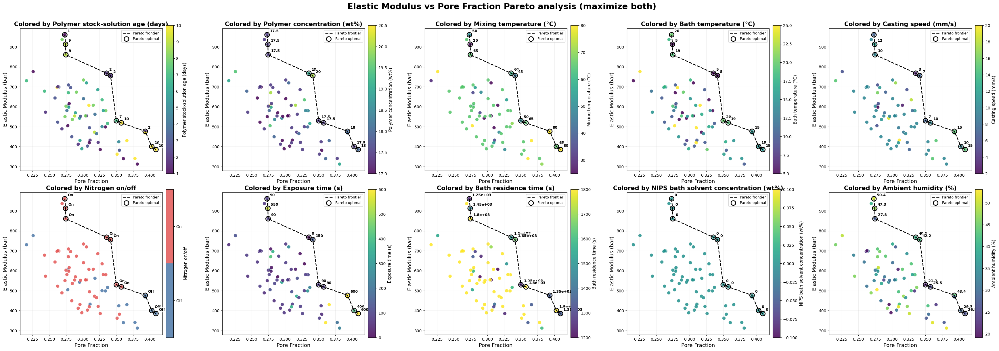

In [52]:
# Version 2: the same Pareto plots without halos.
figure_pareto_no_halo, axes_pareto_no_halo = plot_pareto_campaign(with_halo=False)
plt.show()


## Elastic modulus?yield strength Pareto frontier

These plots treat **higher Elastic Modulus and higher Yield Strength as desirable**, using the same campaign filters, parameter colors, frontier annotations, and optional campaign-mode halos as above. Only experiments with both property means are included; the frontier is recomputed for this objective pair.


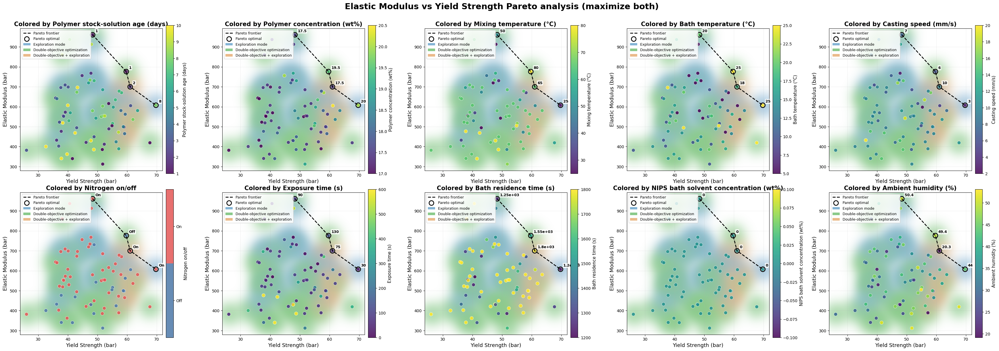

,iteration,Yield Strength Mean,Elastic Modulus Mean,polymer_solution_age_days,polymer_wt,mixing_temp,bath_temp,pullcast_speed,nitrogen,coupon_to_bath_wait_time,nips_bath_wait_time,nips_bath_solvent_wt_percent,Humidity Mean
25,26,48.351827,960.516725,1.0,17.5,50,20,7,True,90,1250,0.0,50.42
28,29,59.702607,776.033094,1.0,19.5,80,25,6,False,130,1550,0.0,49.40
66,67,61.027286,699.801552,2.0,17.5,65,18,10,True,75,1800,0.0,20.28
20,21,69.726613,607.411716,8.0,20.0,25,25,3,True,30,1200,0.0,44.01


In [53]:
yield_pareto_data = prepare_pareto_data(
    campaign_detailed, 'Yield Strength Mean', 'Elastic Modulus Mean'
)
# Version 1: exploration-mode halos.
figure_yield_pareto, axes_yield_pareto = plot_pareto_campaign(
    data=yield_pareto_data, x_property='Yield Strength', with_halo=True
)
plt.show()

yield_pareto_data.loc[yield_pareto_data['pareto_optimal'],
                      ['iteration', 'Yield Strength Mean', 'Elastic Modulus Mean']
                      + list(PARETO_PARAMETERS)].sort_values('Yield Strength Mean')


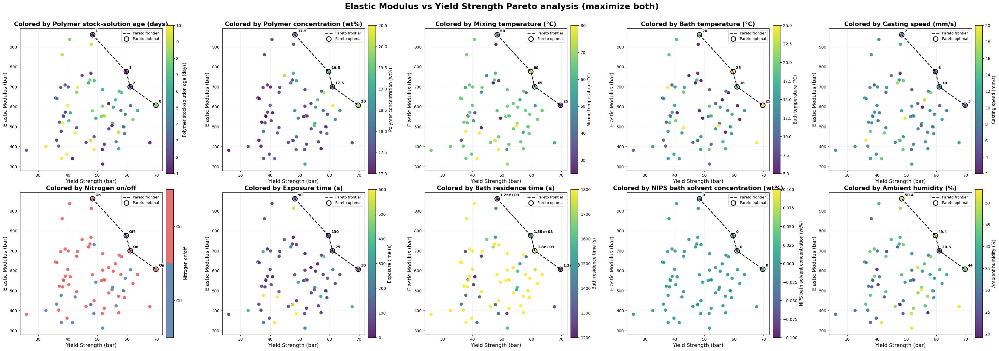

In [54]:
# Version 2: the same modulus-yield strength Pareto plots without halos.
figure_yield_pareto_no_halo, axes_yield_pareto_no_halo = plot_pareto_campaign(
    data=yield_pareto_data, x_property='Yield Strength', with_halo=False
)
plt.show()


## Pareto frontiers by optimization mode

Compare the original exploration campaign, the September 30 double-objective campaign, and the October 30 double-objective campaign with modest exploration. Each panel recomputes the non-dominated frontier within each mode, maximizing both plotted properties. Pale points show all eligible observations; connected bold points show each mode's frontier.


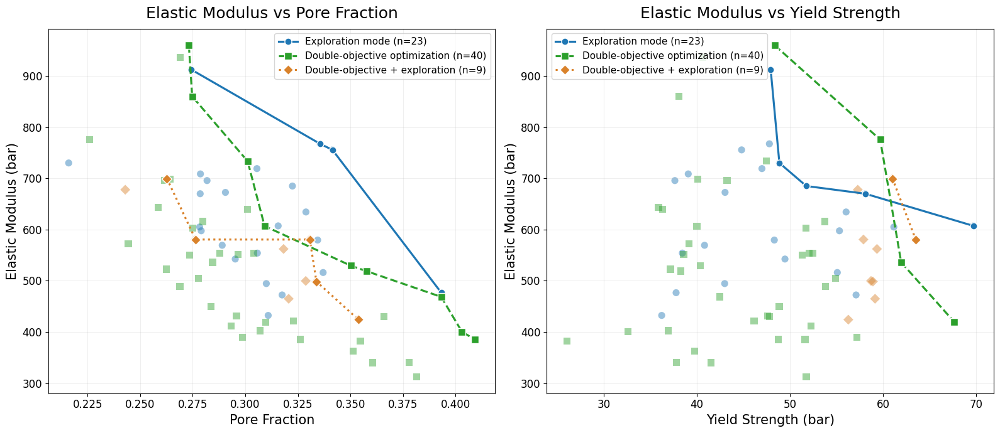

In [55]:
def plot_mode_pareto_frontiers(data):
    # Recompute dominance separately inside each phase, never from the pooled frontier.
    figure, axes = plt.subplots(1, 2, figsize=(16, 7))
    records = []
    for axis, x_property in zip(axes, ['Pore Fraction', 'Yield Strength']):
        x_column, y_column = f'{x_property} Mean', 'Elastic Modulus Mean'
        for phase, marker, linestyle in zip(PHASES, ['o', 's', 'D', '^'], ['-', '--', ':', '-.']):
            mask = _phase_mask(phase, data)
            points = data.loc[mask].copy()
            for column in [x_column, y_column]:
                points[column] = pd.to_numeric(points[column], errors='coerce')
            points = points[np.isfinite(points[[x_column, y_column]]).all(axis=1)]
            if points.empty:
                continue
            points['pareto_optimal'] = pareto_maximize_mask(points[[x_column, y_column]].to_numpy())
            frontier = points[points['pareto_optimal']].sort_values([x_column, y_column])
            axis.scatter(points[x_column], points[y_column], color=phase['color'],
                         marker=marker, s=65, alpha=.45, edgecolors='none', zorder=1)
            axis.plot(frontier[x_column], frontier[y_column], color=phase['color'],
                      marker=marker, linestyle=linestyle, markersize=8, linewidth=2.3,
                      markeredgecolor='white', zorder=3,
                      label=f"{phase['mode_label']} (n={len(points)})")
            frontier = frontier.assign(mode=phase['mode_label'], x_property=x_property)
            records.append(frontier[['mode', 'x_property', 'iteration', 'condition', 'campaign',
                                     'sample_time', x_column, y_column]])
        axis.set_title(f'Elastic Modulus vs {x_property}', fontsize=18, pad=12)
        axis.set_xlabel(property_label(x_property), fontsize=15)
        axis.set_ylabel(property_label('Elastic Modulus'), fontsize=15)
        axis.tick_params(labelsize=12)
        axis.grid(alpha=.20)
        axis.legend(fontsize=11, loc='best')
    figure.tight_layout()
    frontier_table = pd.concat(records, ignore_index=True, sort=False) if records else pd.DataFrame()
    return figure, axes, frontier_table

figure_mode_pareto, axes_mode_pareto, mode_pareto_frontiers = plot_mode_pareto_frontiers(campaign_detailed)
plt.show()
if SAVE_OUTPUTS:
    mode_pareto_output = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    mode_pareto_output.mkdir(parents=True, exist_ok=True)
    figure_mode_pareto.savefig(mode_pareto_output / 'pareto_frontiers_by_mode.png', dpi=180)
    mode_pareto_frontiers.to_csv(mode_pareto_output / 'pareto_frontiers_by_mode.csv', index=False)


## Principal-component analysis of the feature space

PCA uses the same filtered experiments and input features as the feature-importance analysis, including stock-solution age. Missing/nonfinite inputs are median-imputed, constant or entirely missing features are dropped, and inputs are standardized to equal variance before fitting one shared PCA. Property observations only set point colors; they do not enter the PCA fit. Axis labels report explained variance, and the coefficient table shows which features define each component.

Each panel colors this shared PC1?PC2 projection by an observed property mean. Gray points have no finite observation for that property. Arrow colors use the same search-mode palette as the campaign/Pareto plots; each arrow uses the destination experiment's mode (also at campaign boundaries). Arrows connect consecutive experiments in chronological iteration order, becoming more opaque from early to late steps (including across campaign boundaries). Start/end markers identify the trajectory endpoints. Overlapping projections have no visible arrow. These paths describe the experimental sequence; they do not imply interpolation or causality.


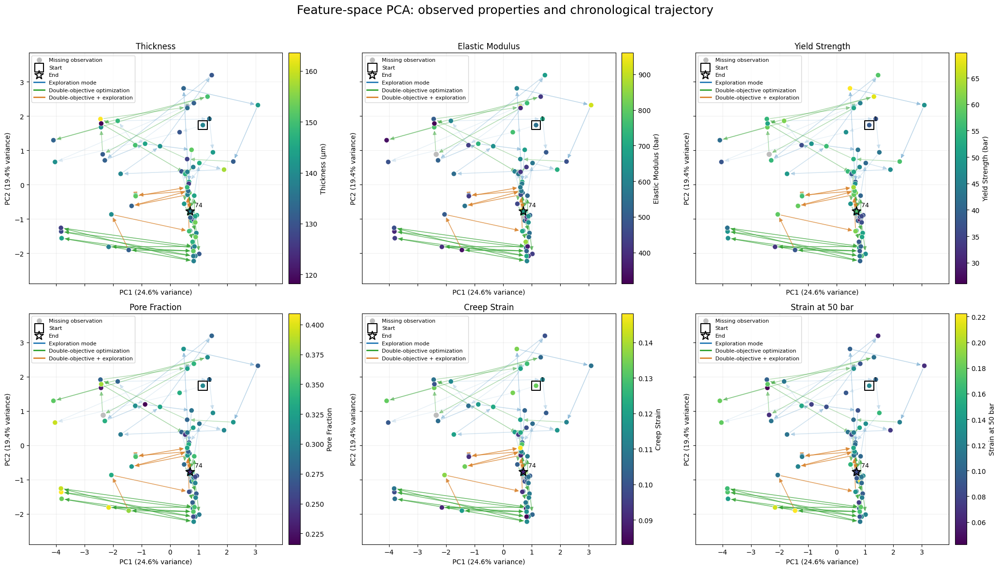

PC1 + PC2 explain 44.0% of standardized input variance.


,label,PC1,PC2
feature,,,
polymer_solution_age_days,Polymer stock-solution age (days),0.051,-0.361
polymer_wt,Polymer concentration (wt%),-0.223,0.400
mixing_temp,Mixing temperature (°C),-0.295,-0.344
bath_temp,Bath temperature (°C),-0.090,-0.066
pullcast_speed,Casting speed (mm/s),-0.163,-0.079
nitrogen,Nitrogen on/off,0.576,-0.054
nitrogen_exposure_time,Exposure time - N2 on (s),0.384,0.217
air_exposure_time,Exposure time - N2 off (s),-0.569,-0.040
nips_bath_wait_time,Bath residence time (s),0.144,-0.428


In [56]:
PCA_PROPERTIES = list(PROPERTIES)
PCA_ARROW_ALPHA = (0.08, 0.85)  # Earliest to latest chronological step.


def prepare_feature_pca(data, features):
    points = data.sort_values(['sample_time', 'iteration'], kind='stable').copy()
    if len(points) < 3:
        raise ValueError('Feature PCA requires at least three experiments.')
    inputs = points[list(features)].copy()
    inputs['nitrogen'] = inputs['nitrogen'].map(nitrogen_to_binary)
    inputs = inputs.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    variable = [column for column in inputs if inputs[column].nunique(dropna=True) > 1]
    if len(variable) < 2:
        raise ValueError('Feature PCA requires at least two varying input features.')
    inputs = inputs[variable].fillna(inputs[variable].median())
    standardized = (inputs - inputs.mean()) / inputs.std(ddof=0)
    _, singular_values, components = np.linalg.svd(standardized.to_numpy(), full_matrices=False)
    # Resolve arbitrary SVD signs reproducibly using each component's largest coefficient.
    for component in components:
        if component[np.argmax(np.abs(component))] < 0:
            component *= -1
    scores = standardized.to_numpy() @ components[:2].T
    points[['PC1', 'PC2']] = scores
    variance_ratio = singular_values**2 / np.sum(singular_values**2)
    coefficients = pd.DataFrame(components[:2].T, index=variable, columns=['PC1', 'PC2'])
    coefficients.index.name = 'feature'
    coefficients.insert(0, 'label', [features[column] for column in variable])
    return points, coefficients, variance_ratio[:2]


def plot_feature_pca(points, properties, variance_ratio):
    from matplotlib.patches import FancyArrowPatch
    from matplotlib.lines import Line2D
    properties = list(properties)
    if not properties:
        raise ValueError('Choose at least one PCA color property.')
    columns = min(3, len(properties))
    rows = int(np.ceil(len(properties) / columns))
    figure, grid = plt.subplots(rows, columns, figsize=(7 * columns, 6 * rows),
                               squeeze=False, sharex=True, sharey=True)
    coordinates = points[['PC1', 'PC2']].to_numpy()
    arrow_alphas = np.linspace(*PCA_ARROW_ALPHA, len(points) - 1)
    # Each step takes the destination experiment's search-mode color.
    mode_colors = np.full(len(points), '#353535', dtype=object)
    classified = np.zeros(len(points), dtype=bool)
    mode_handles = []
    for phase in PHASES:
        mask = _phase_mask(phase, points).to_numpy(dtype=bool)
        mode_colors[mask] = phase['color']
        classified |= mask
        if mask[1:].any():
            mode_handles.append(Line2D([], [], color=phase['color'], linewidth=2,
                                       label=phase['mode_label']))
    if (~classified[1:]).any():
        mode_handles.append(Line2D([], [], color='#353535', linewidth=2,
                                   label='Unclassified search mode'))
    for axis, prop in zip(grid.flat, properties):
        for start, end, alpha, mode_color in zip(
                coordinates[:-1], coordinates[1:], arrow_alphas, mode_colors[1:]):
            if np.allclose(start, end):
                continue
            axis.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>',
                           mutation_scale=12, linewidth=1.1, color=mode_color,
                           alpha=float(alpha), shrinkA=5, shrinkB=5, zorder=1))
        observations = pd.to_numeric(points[f'{prop} Mean'], errors='coerce')
        valid = np.isfinite(observations)
        axis.scatter(points.loc[~valid, 'PC1'], points.loc[~valid, 'PC2'],
                     color='#bdbdbd', s=45, label='Missing observation', zorder=2)
        if valid.any():
            scatter = axis.scatter(points.loc[valid, 'PC1'], points.loc[valid, 'PC2'],
                                   c=observations[valid], cmap='viridis', s=55,
                                   edgecolors='white', linewidths=0.5, zorder=3)
            figure.colorbar(scatter, ax=axis, pad=0.02).set_label(property_label(prop))
        for position, marker, label in [(0, 's', 'Start'), (-1, '*', 'End')]:
            axis.scatter(*coordinates[position], marker=marker, s=180, facecolors='none',
                         edgecolors='black', linewidths=1.5, label=label, zorder=4)
            axis.annotate(str(int(points.iloc[position]['iteration'])), coordinates[position],
                          xytext=(7, 7), textcoords='offset points', fontsize=9)
        axis.set(title=prop, xlabel=f'PC1 ({variance_ratio[0]:.1%} variance)',
                 ylabel=f'PC2 ({variance_ratio[1]:.1%} variance)')
        axis.grid(alpha=0.2)
        axis.margins(0.12)
        handles, _ = axis.get_legend_handles_labels()
        axis.legend(handles=handles + mode_handles, fontsize=8, loc='best')
    for axis in list(grid.flat)[len(properties):]:
        axis.set_visible(False)
    figure.suptitle('Feature-space PCA: observed properties and chronological trajectory', fontsize=18)
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    return figure, grid


feature_pca_data, feature_pca_coefficients, feature_pca_variance = prepare_feature_pca(
    campaign_detailed, FEATURES
)
figure_feature_pca, axes_feature_pca = plot_feature_pca(
    feature_pca_data, PCA_PROPERTIES, feature_pca_variance
)
plt.show()
print(f'PC1 + PC2 explain {feature_pca_variance.sum():.1%} of standardized input variance.')
display(feature_pca_coefficients.round(3))

if SAVE_OUTPUTS:
    pca_output = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    pca_output.mkdir(parents=True, exist_ok=True)
    figure_feature_pca.savefig(pca_output / 'feature_space_pca.png', dpi=180, bbox_inches='tight')
    feature_pca_data.to_csv(pca_output / 'feature_space_pca_scores.csv', index=False)
    feature_pca_coefficients.to_csv(pca_output / 'feature_space_pca_coefficients.csv')


## K-means clusters and PCA within each cluster

K-means groups experiments using their **shared PC1?PC2 scores** (Euclidean distance, without rescaling the two axes). Set `PCA_N_CLUSTERS` below; the default is 3. The best of 20 reproducible initializations is retained. These clusters describe the two-dimensional projection, so they may miss separation in higher components.

The overview shows cluster membership and centroids. Each cluster then gets its **own PCA fit on the original input features**, with median imputation, standardization, and constant-feature removal recomputed inside that cluster. Separate property-colored figures retain search-mode arrow colors and increasing chronological opacity. Arrows connect successive retained members of that cluster, potentially skipping experiments in other clusters. Local axes and explained variance differ between clusters and cannot be compared as shared coordinates. Clusters with fewer than three members or fewer than two varying inputs are reported and skipped. Coefficient tables describe each local PCA.


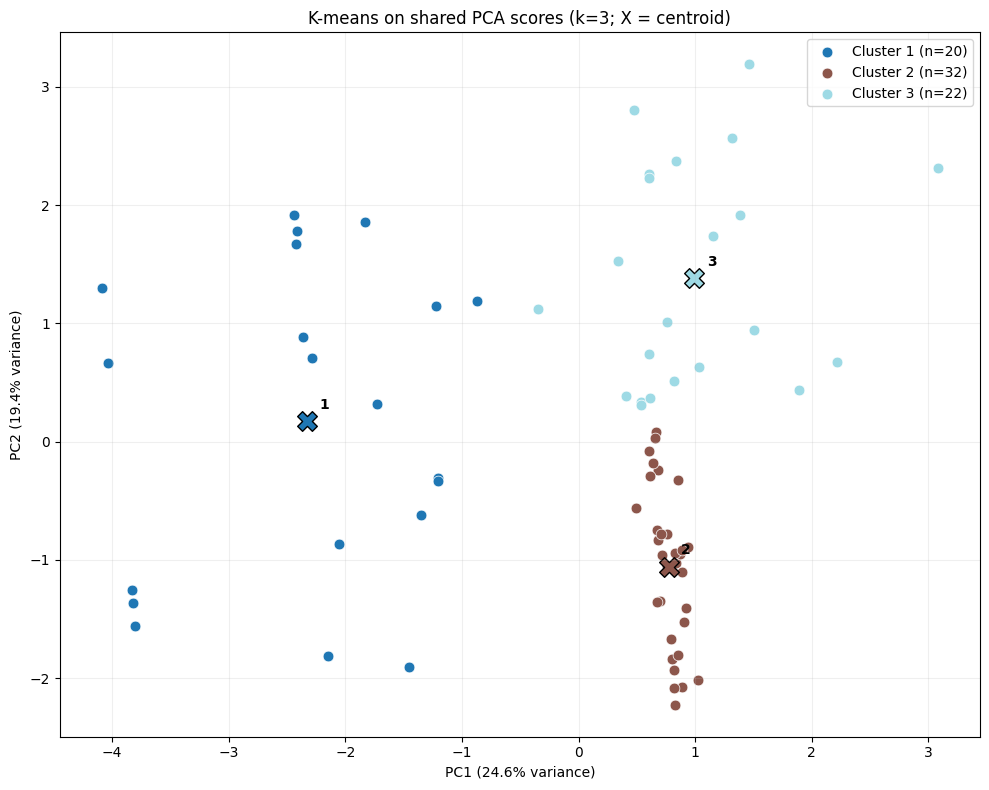

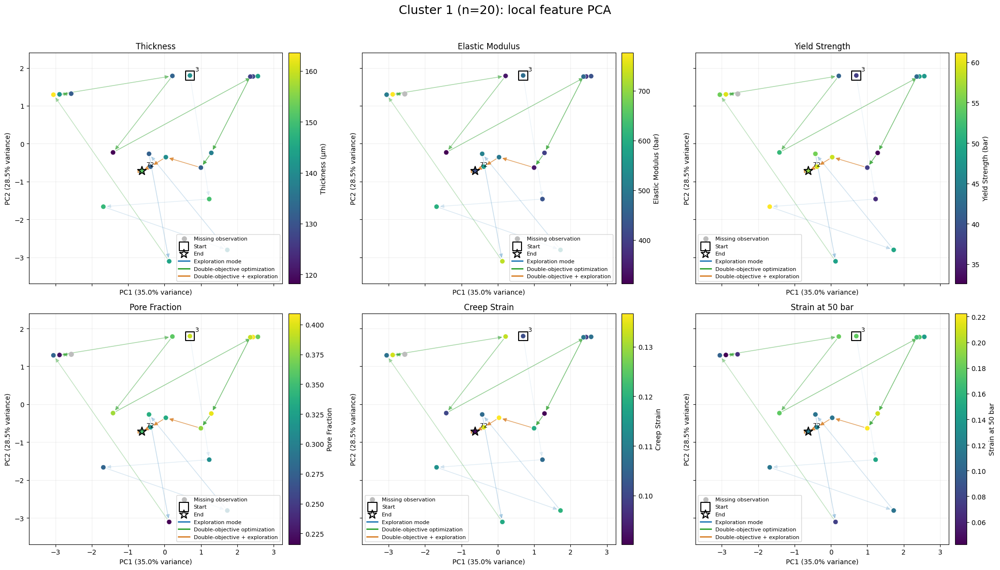

Cluster 1: local PC1 + PC2 explain 63.4% of input variance.


,label,PC1,PC2
feature,,,
polymer_solution_age_days,Polymer stock-solution age (days),0.432,-0.030
polymer_wt,Polymer concentration (wt%),-0.386,-0.009
mixing_temp,Mixing temperature (°C),-0.103,0.619
bath_temp,Bath temperature (°C),-0.266,0.453
pullcast_speed,Casting speed (mm/s),0.478,-0.095
air_exposure_time,Exposure time - N2 off (s),0.384,0.395
nips_bath_wait_time,Bath residence time (s),-0.156,-0.495
Humidity Mean,Ambient humidity (%),-0.427,-0.023


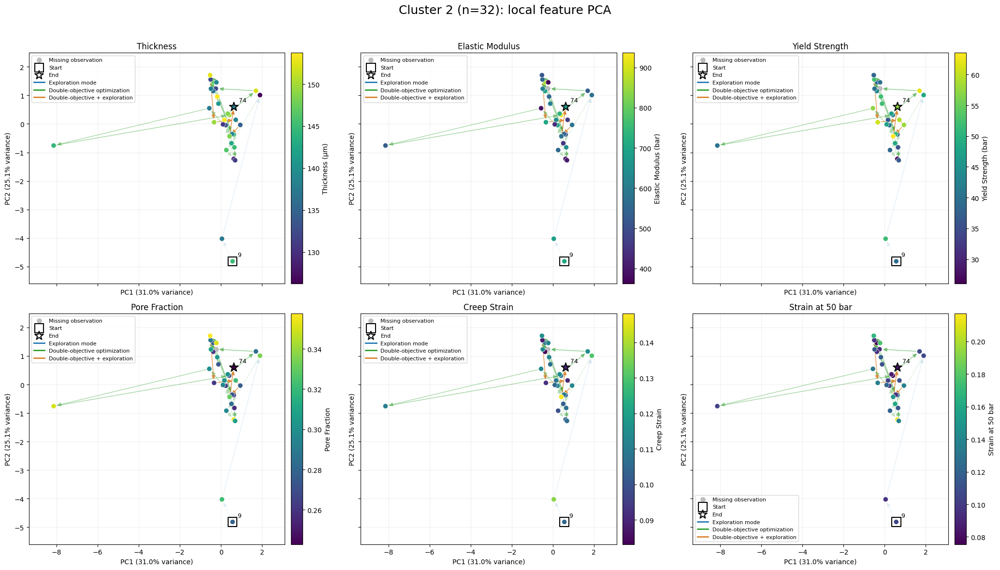

Cluster 2: local PC1 + PC2 explain 56.1% of input variance.


,label,PC1,PC2
feature,,,
polymer_solution_age_days,Polymer stock-solution age (days),-0.110,0.430
polymer_wt,Polymer concentration (wt%),0.105,0.117
mixing_temp,Mixing temperature (°C),0.589,0.068
bath_temp,Bath temperature (°C),-0.328,0.277
pullcast_speed,Casting speed (mm/s),0.268,0.545
nitrogen_exposure_time,Exposure time - N2 on (s),-0.039,0.600
nips_bath_wait_time,Bath residence time (s),0.589,0.068
Humidity Mean,Ambient humidity (%),0.319,-0.240


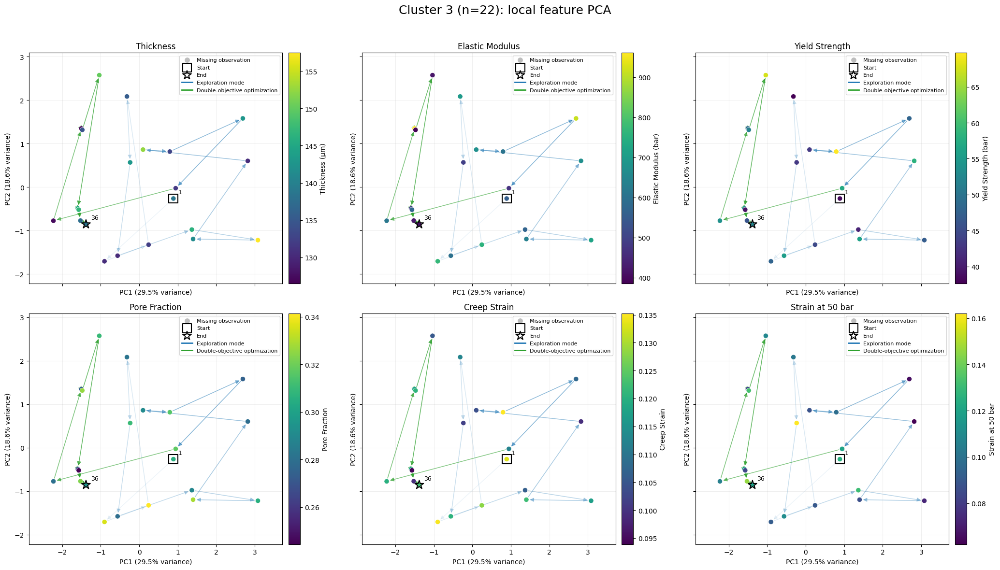

Cluster 3: local PC1 + PC2 explain 48.1% of input variance.


,label,PC1,PC2
feature,,,
polymer_solution_age_days,Polymer stock-solution age (days),0.496,0.010
polymer_wt,Polymer concentration (wt%),0.208,-0.220
mixing_temp,Mixing temperature (°C),-0.492,-0.201
bath_temp,Bath temperature (°C),-0.302,0.532
pullcast_speed,Casting speed (mm/s),0.358,0.088
nitrogen_exposure_time,Exposure time - N2 on (s),0.322,0.478
nips_bath_wait_time,Bath residence time (s),-0.174,-0.424
Humidity Mean,Ambient humidity (%),-0.341,0.459


,cluster,n,status,PC1_variance,PC2_variance
0,1,20,fitted,0.349637,0.284561
1,2,32,fitted,0.310492,0.250604
2,3,22,fitted,0.295099,0.185591


In [57]:
from scipy.cluster.vq import kmeans2

PCA_N_CLUSTERS = 3
PCA_KMEANS_SEED = 42
PCA_KMEANS_RESTARTS = 20


def cluster_pca_scores(points, n_clusters, seed=42, restarts=20):
    if isinstance(n_clusters, bool) or not isinstance(n_clusters, (int, np.integer)) or n_clusters < 2:
        raise ValueError('PCA_N_CLUSTERS must be an integer of at least 2.')
    coordinates = points[['PC1', 'PC2']].to_numpy(dtype=float)
    if not np.isfinite(coordinates).all():
        raise ValueError('K-means requires finite PCA coordinates.')
    if n_clusters > len(np.unique(coordinates, axis=0)):
        raise ValueError('PCA_N_CLUSTERS exceeds the number of distinct PCA positions.')
    generator = np.random.RandomState(seed)
    best = None
    for _ in range(restarts):
        # Sampling distinct positions avoids duplicate initial centroids.
        unique = np.unique(coordinates, axis=0)
        initial = unique[generator.choice(len(unique), n_clusters, replace=False)]
        centers, labels = kmeans2(coordinates, initial, iter=100, minit='matrix', missing='warn')
        if len(np.unique(labels)) != n_clusters:
            continue
        inertia = np.sum((coordinates - centers[labels]) ** 2)
        if best is None or inertia < best[0]:
            best = (inertia, centers, labels)
    if best is None:
        raise ValueError('K-means produced empty clusters; reduce PCA_N_CLUSTERS.')
    inertia, centers, labels = best
    # Stable cluster numbers ordered by centroid PC1, then PC2.
    order = np.lexsort((centers[:, 1], centers[:, 0]))
    remap = np.empty(n_clusters, dtype=int)
    remap[order] = np.arange(1, n_clusters + 1)
    clustered = points.copy()
    clustered['pca_cluster'] = remap[labels]
    centroids = pd.DataFrame(centers[order], columns=['PC1', 'PC2'])
    centroids.index = pd.Index(range(1, n_clusters + 1), name='pca_cluster')
    return clustered, centroids, inertia


clustered_pca_data, pca_cluster_centroids, pca_cluster_inertia = cluster_pca_scores(
    feature_pca_data, PCA_N_CLUSTERS, PCA_KMEANS_SEED, PCA_KMEANS_RESTARTS
)
figure_pca_clusters, axis_pca_clusters = plt.subplots(figsize=(10, 8))
cluster_palette = plt.get_cmap('tab20', PCA_N_CLUSTERS)
for cluster_id, members in clustered_pca_data.groupby('pca_cluster', sort=True):
    axis_pca_clusters.scatter(members['PC1'], members['PC2'], s=60,
                              color=cluster_palette(cluster_id - 1),
                              label=f'Cluster {cluster_id} (n={len(members)})',
                              edgecolors='white', linewidths=0.5)
    center = pca_cluster_centroids.loc[cluster_id]
    axis_pca_clusters.scatter(center.PC1, center.PC2, marker='X', s=200,
                              color=cluster_palette(cluster_id - 1), edgecolors='black')
    axis_pca_clusters.annotate(str(cluster_id), (center.PC1, center.PC2),
                               xytext=(9, 9), textcoords='offset points', fontweight='bold')
axis_pca_clusters.set(title=f'K-means on shared PCA scores (k={PCA_N_CLUSTERS}; X = centroid)',
                      xlabel=f'PC1 ({feature_pca_variance[0]:.1%} variance)',
                      ylabel=f'PC2 ({feature_pca_variance[1]:.1%} variance)')
axis_pca_clusters.legend()
axis_pca_clusters.grid(alpha=0.2)
figure_pca_clusters.tight_layout()
plt.show()

cluster_pca_results = {}
cluster_pca_summary_records = []
for cluster_id, members in clustered_pca_data.groupby('pca_cluster', sort=True):
    try:
        local_scores, local_coefficients, local_variance = prepare_feature_pca(members, FEATURES)
    except ValueError as error:
        print(f'Cluster {cluster_id} (n={len(members)}): skipped local PCA: {error}')
        cluster_pca_summary_records.append(dict(cluster=cluster_id, n=len(members),
                                                 status=str(error)))
        continue
    local_figure, local_axes = plot_feature_pca(local_scores, PCA_PROPERTIES, local_variance)
    local_figure.suptitle(f'Cluster {cluster_id} (n={len(members)}): local feature PCA', fontsize=18)
    plt.show()
    print(f'Cluster {cluster_id}: local PC1 + PC2 explain {local_variance.sum():.1%} of input variance.')
    display(local_coefficients.round(3))
    cluster_pca_results[cluster_id] = dict(scores=local_scores, coefficients=local_coefficients,
                                          variance=local_variance, figure=local_figure)
    cluster_pca_summary_records.append(dict(cluster=cluster_id, n=len(members), status='fitted',
                                             PC1_variance=local_variance[0],
                                             PC2_variance=local_variance[1]))
pca_cluster_summary = pd.DataFrame(cluster_pca_summary_records)
display(pca_cluster_summary)

if SAVE_OUTPUTS:
    cluster_output = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    cluster_output.mkdir(parents=True, exist_ok=True)
    figure_pca_clusters.savefig(cluster_output / 'feature_pca_clusters.png', dpi=180, bbox_inches='tight')
    clustered_pca_data.to_csv(cluster_output / 'feature_pca_cluster_assignments.csv', index=False)
    pca_cluster_centroids.to_csv(cluster_output / 'feature_pca_cluster_centroids.csv')
    pca_cluster_summary.to_csv(cluster_output / 'feature_pca_cluster_summary.csv', index=False)
    for cluster_id, result in cluster_pca_results.items():
        prefix = f'feature_pca_cluster_{cluster_id}'
        result['figure'].savefig(cluster_output / f'{prefix}.png', dpi=180, bbox_inches='tight')
        result['scores'].to_csv(cluster_output / f'{prefix}_scores.csv', index=False)
        result['coefficients'].to_csv(cluster_output / f'{prefix}_coefficients.csv')


In [58]:
# Optional explicit export of the enhanced figure/data; nothing is written otherwise.
if SAVE_OUTPUTS:
    output_dir = repo_root / 'EVALUATE' / 'primospire_nmp_campaign_trends_output'
    output_dir.mkdir(parents=True, exist_ok=True)
    csv_path = output_dir / 'campaign_data_detailed.csv'
    polymer_png = output_dir / 'campaign_properties_by_polymer.png'
    humidity_png = output_dir / 'campaign_properties_by_humidity_nitrogen.png'
    exposure_png = output_dir / 'campaign_properties_by_exposure_time.png'
    bath_png = output_dir / 'campaign_properties_by_bath_temperature.png'
    casting_png = output_dir / 'campaign_properties_by_casting_speed.png'
    importance_csv = output_dir / 'campaign_feature_importance.csv'
    importance_png = output_dir / 'campaign_feature_importance.png'
    importance_confidence_png = output_dir / 'campaign_feature_importance_confidence.png'
    importance_direction_png = output_dir / 'campaign_feature_importance_direction.png'
    nitrogen_exposure_png = output_dir / 'campaign_nitrogen_exposure_surfaces.png'
    humidity_exposure_png = output_dir / 'campaign_humidity_exposure_surfaces.png'
    shap_values_csv = output_dir / 'campaign_linear_shap_values.csv'
    shap_predictions_csv = output_dir / 'campaign_linear_shap_predictions.csv'
    shap_global_png = output_dir / 'campaign_linear_shap_global.png'
    pareto_csv = output_dir / 'elastic_modulus_pore_fraction_pareto.csv'
    pareto_png = output_dir / 'elastic_modulus_pore_fraction_pareto_by_parameter.png'
    pareto_no_halo_png = output_dir / 'elastic_modulus_pore_fraction_pareto_by_parameter_no_halo.png'
    yield_pareto_csv = output_dir / 'elastic_modulus_yield_strength_pareto.csv'
    yield_pareto_png = output_dir / 'elastic_modulus_yield_strength_pareto_by_parameter.png'
    yield_pareto_no_halo_png = output_dir / 'elastic_modulus_yield_strength_pareto_by_parameter_no_halo.png'
    interaction_csv = output_dir / 'campaign_pairwise_interactions.csv'
    interaction_png = output_dir / 'campaign_pairwise_interactions.png'
    campaign_detailed.to_csv(csv_path, index=False)
    figure_polymer.savefig(polymer_png, dpi=180, bbox_inches='tight')
    figure_humidity.savefig(humidity_png, dpi=180, bbox_inches='tight')
    figure_exposure.savefig(exposure_png, dpi=180, bbox_inches='tight')
    figure_bath.savefig(bath_png, dpi=180, bbox_inches='tight')
    figure_casting.savefig(casting_png, dpi=180, bbox_inches='tight')
    feature_importance.to_csv(importance_csv, index=False)
    figure_importance.savefig(importance_png, dpi=180, bbox_inches='tight')
    figure_importance_confidence.savefig(importance_confidence_png, dpi=180, bbox_inches='tight')
    figure_importance_direction.savefig(importance_direction_png, dpi=180, bbox_inches='tight')
    figure_nitrogen_exposure.savefig(nitrogen_exposure_png, dpi=180, bbox_inches='tight')
    figure_humidity_exposure.savefig(humidity_exposure_png, dpi=180, bbox_inches='tight')
    shap_values.to_csv(shap_values_csv, index=False)
    shap_predictions.to_csv(shap_predictions_csv, index=False)
    figure_shap_global.savefig(shap_global_png, dpi=180, bbox_inches='tight')
    pareto_data.to_csv(pareto_csv, index=False)
    figure_pareto.savefig(pareto_png, dpi=180, bbox_inches='tight')
    figure_pareto_no_halo.savefig(pareto_no_halo_png, dpi=180, bbox_inches='tight')
    yield_pareto_data.to_csv(yield_pareto_csv, index=False)
    figure_yield_pareto.savefig(yield_pareto_png, dpi=180, bbox_inches='tight')
    figure_yield_pareto_no_halo.savefig(yield_pareto_no_halo_png, dpi=180, bbox_inches='tight')
    interaction_results.to_csv(interaction_csv, index=False)
    figure_interactions.savefig(interaction_png, dpi=180, bbox_inches='tight')
    shap_detail_paths = []
    for property_name, detail_figure in figure_shap_details.items():
        safe_property = property_name.lower().replace(' ', '_')
        detail_path = output_dir / f'campaign_linear_shap_{safe_property}.png'
        detail_figure.savefig(detail_path, dpi=180, bbox_inches='tight')
        shap_detail_paths.append(detail_path)
    all_saved_paths = [csv_path, polymer_png, humidity_png, exposure_png, bath_png, casting_png,
                       importance_csv, importance_png, importance_confidence_png, importance_direction_png,
                       nitrogen_exposure_png, humidity_exposure_png,
                       shap_values_csv, shap_predictions_csv,
                       shap_global_png, pareto_csv, pareto_png, pareto_no_halo_png, interaction_csv, interaction_png,
                       yield_pareto_csv, yield_pareto_png, yield_pareto_no_halo_png] + shap_detail_paths
    print('Saved ' + '\nSaved '.join(str(path) for path in all_saved_paths))